# TFM: Evaluación y caracterización de la marcha patológica mediante extracción de características de sensores inerciales y aprendizaje automático

**Nombre y apellidos:** Andrea Mei Sala Aracil

**Dataset:** ClinicalGait (Voisard et al., 2025) · **Entrada:** `gait_features_v2.csv`, generado con `extract_gait_features_v2.py` (medias + variabilidad ciclo a ciclo de cada parámetro).

**Pregunta central:** ¿qué información clínica aportan los parámetros de marcha obtenidos con sensores inerciales, y qué limitaciones tiene?

**Objetivos**
- **Caracterizar** la marcha de cada patología frente a la marcha sana.
- **Clasificar** la marcha (sano/patológico, tipo de patología) e identificar qué parámetros describen cada patología.
- **Estimar la severidad** clínica a partir de los parámetros de marcha.

**Estructura**
1. Configuración inicial y carga de datos
2. Exploración, control de calidad y limpieza
3. Análisis descriptivo por cohorte (O1)
4. Preparación de variables (incluye visualización con PCA)
5. Clasificación con validación cruzada agrupada por sujeto (O2)
6. Interpretabilidad (O2)
7. Estimación de la severidad (O3): índice de desviación y modelos predictivos
8. Conclusiones y limitaciones

## 0. Configuración inicial y carga de datos

In [ ]:
# Agrupación de imports necesarios a lo largo del notebook
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import kruskal, spearmanr, mannwhitneyu, rankdata

from sklearn.base import clone
from sklearn.model_selection import StratifiedGroupKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.linear_model import LogisticRegression, LinearRegression, RidgeCV
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (RandomForestClassifier, RandomForestRegressor, ExtraTreesClassifier,
                              HistGradientBoostingClassifier)
from sklearn.neural_network import MLPClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (balanced_accuracy_score, f1_score, roc_auc_score, top_k_accuracy_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             mean_absolute_error, r2_score)

# warnings.filterwarnings("ignore")
# pd.set_option("display.max_columns", 80)
# pd.set_option("display.width", 200)

# estilo común para los gráficos
sns.set_theme(style="whitegrid", context="notebook")

RANDOM_STATE = 42     # semilla fija para resultados reproducibles
N_REPS = 3            # repeticiones de la validación cruzada (con particiones distintas)
np.random.seed(RANDOM_STATE)

# creación de carpetas y funciones para guardar los resultados
os.makedirs("figuras", exist_ok=True)
os.makedirs("tablas", exist_ok=True)

def guardar_fig(nombre):
    plt.savefig(f"figuras/{nombre}.png", dpi=300, bbox_inches="tight")

def guardar_tabla(tabla, nombre):
    tabla.to_csv(f"tablas/{nombre}.csv")

In [ ]:
# grupos de columnas organizadas por naturaleza
ID_COLS       = ["trial_id", "subject", "trial", "session", "daysSinceFirstSession"]
LABEL_COLS    = ["group", "pathologyKey"]
DEMO_COLS     = ["age", "gender", "height_m", "weight_kg", "BMI", "laterality"]
CLINICAL_COLS = ["clinicalDeficitSide", "evaluationScoreValue", "visualGaitAssessment", "TUG_s"]
ACQ_COLS      = ["sensor", "protocolDistance_m", "nCycles_L", "nCycles_R"]

# Parámetros de marcha: MEDIA de los ciclos de cada registro, si procede depediendo del parámetro
MEDIAS = [
    "cadence_stepsPerMin", "strideTime_L_s", "strideTime_R_s", "stepTime_s",
    "stancePhase_L_pct", "stancePhase_R_pct", "doubleSupport_pct", "asymmetry_strideTime_pct",
    "strideLength_L_m", "strideLength_R_m", "gaitSpeed_ms", "asymmetry_strideLength_pct",
    "footStrikeAngle_L_deg", "footStrikeAngle_R_deg",
    "comVerticalAmplitude_m", "comLateralAmplitude_m",
    "shockAttenuation_L_dB", "shockAttenuation_R_dB", "asymmetry_shockAttenuation_dB",
]
# Parámetros de marcha: VARIABILIDAD ciclo a ciclo de cada registro (CV = coeficiente de variación o SD = desviación típica)
VARIAB = [
    "strideTime_L_cv_pct", "strideTime_R_cv_pct", "strideTime_cv_pct", "stepTime_cv_pct",
    "strideLength_L_cv_pct", "strideLength_R_cv_pct", "strideLength_cv_pct",
    "stancePhase_L_sd_pct", "stancePhase_R_sd_pct",
    "footStrikeAngle_L_sd_deg", "footStrikeAngle_R_sd_deg",
    "shockAttenuation_L_sd_dB", "shockAttenuation_R_sd_dB", "doubleSupport_sd_pct",
]

# Unificación de todos los parámetrtos de marcha en única variable
BIOMECH = MEDIAS + VARIAB

# Orden y colores de las cohortes para todas las figuras
ORDEN = ["HS", "HOA", "KOA", "ACL", "CVA", "PD", "CIPN", "RIL"]
GRUPO_DE = {"HS": "healthy", "HOA": "ortho", "KOA": "ortho", "ACL": "ortho",
            "CVA": "neuro", "PD": "neuro", "CIPN": "neuro", "RIL": "neuro"}
  # healthy = verde, ortho = naranja, neuro = azul
COLOR_GRUPO = {"healthy": "#4C9F70", "ortho": "#E8A33D", "neuro": "#5B7DB1"}
PALETA = {p: COLOR_GRUPO[g] for p, g in GRUPO_DE.items()}
PALETA["OA"] = COLOR_GRUPO["ortho"]

In [ ]:
# carga de datos
from google.colab import files
df = pd.read_csv(list(files.upload())[0])

# comprobación de los registros que se cargan
print(f"Registros: {df.shape[0]} | Columnas: {df.shape[1]}")
df.head()

Saving gait_features_v2.csv to gait_features_v2.csv
Registros: 1356 | Columnas: 54


,trial_id,subject,trial,session,daysSinceFirstSession,group,pathologyKey,age,gender,height_m,...,strideLength_L_cv_pct,strideLength_R_cv_pct,strideLength_cv_pct,stancePhase_L_sd_pct,stancePhase_R_sd_pct,footStrikeAngle_L_sd_deg,footStrikeAngle_R_sd_deg,shockAttenuation_L_sd_dB,shockAttenuation_R_sd_dB,doubleSupport_sd_pct
0,HS_1_1,HS_1,1,1,0,healthy,HS,18.0,M,1.79,...,2.147874,4.796778,3.596664,1.190133,1.665147,1.913029,7.521320,0.937725,2.703299,3.479597
1,HS_1_2,HS_1,2,1,0,healthy,HS,18.0,M,1.79,...,3.021279,5.014548,4.002175,1.015727,1.903495,2.200348,4.458500,1.023318,2.167444,3.497492
2,HS_1_3,HS_1,3,1,0,healthy,HS,18.0,M,1.79,...,2.315034,5.054042,4.002918,1.084060,1.571277,6.224050,2.787089,0.724284,2.447571,3.416664
3,HS_1_4,HS_1,4,1,0,healthy,HS,18.0,M,1.79,...,4.111631,3.345134,3.632576,3.099491,0.956530,9.199134,1.310082,2.461830,1.504487,3.668087
4,HS_1_5,HS_1,5,1,0,healthy,HS,18.0,M,1.79,...,4.636915,3.332865,3.954689,1.475594,1.168376,6.511970,4.823311,2.462620,0.687335,3.560979


## 2. Exploración, control de calidad y limpieza de datos

### 2.1 Comprobación del tamaño de cada cohorte

Cada sujeto tiene uno o varios registros (trials) agrupados en visitas (sesiones). La validación de los modelos se debe hacer **por sujeto** para no mezclar registros de un mismo sujeto en entrenamiento y test a la vez. Es necesario conocer las distribuciones de los datos.

Distribución de sujetos, trials por cohorte y trials por patología:

In [ ]:
print("Trials:", len(df), " | Sujetos:", df["subject"].nunique())

# Trials y sujetos únicos por gran grupo (healthy, neuro, ortho)
por_grupo = df.groupby("group").agg(trials=("trial_id", "count"),
                                    sujetos=("subject", "nunique"))
for g, fila in por_grupo.iterrows():
    print(f"  {g}: {fila['trials']} trials | {fila['sujetos']} sujetos")

resumen = (df.groupby(["group", "pathologyKey"])
             .agg(trials=("trial_id", "count"), sujetos=("subject", "nunique"))
             .reset_index())
resumen

Trials: 1356  | Sujetos: 260
  healthy: 360 trials | 73 sujetos
  neuro: 784 trials | 143 sujetos
  ortho: 212 trials | 44 sujetos


,group,pathologyKey,trials,sujetos
0,healthy,HS,360,73
1,neuro,CIPN,98,19
2,neuro,CVA,128,49
3,neuro,PD,160,24
4,neuro,RIL,398,51
5,ortho,ACL,60,11
6,ortho,HOA,74,15
7,ortho,KOA,78,18


In [ ]:
por_sujeto = df.groupby(["pathologyKey", "subject"]).size()
tabla_cohortes = (df.groupby(["group", "pathologyKey"])
                    .agg(sujetos=("subject", "nunique"), registros=("trial_id", "count"))
                    .reset_index().set_index("pathologyKey").loc[ORDEN])
tabla_cohortes["visitas"] = df.groupby("pathologyKey").apply(lambda g: g.groupby(["subject", "session"]).ngroups)
tabla_cohortes["registros_por_sujeto"] = por_sujeto.groupby("pathologyKey").agg(
    lambda x: f"{x.median():.0f} [{x.min()}–{x.max()}]")
guardar_tabla(tabla_cohortes, "2_1_tamano_cohortes")
tabla_cohortes

/tmp/ipykernel_2493/2929417562.py:5: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  tabla_cohortes["visitas"] = df.groupby("pathologyKey").apply(lambda g: g.groupby(["subject", "session"]).ngroups)


,group,sujetos,registros,visitas,registros_por_sujeto
pathologyKey,,,,,
HS,healthy,73,360,79,5 [1–29]
HOA,ortho,15,74,24,5 [1–10]
KOA,ortho,18,78,24,4 [1–9]
ACL,ortho,11,60,16,5 [2–8]
CVA,neuro,49,128,57,2 [2–16]
PD,neuro,24,160,32,5 [5–15]
CIPN,neuro,19,98,20,5 [4–9]
RIL,neuro,51,398,83,5 [1–24]


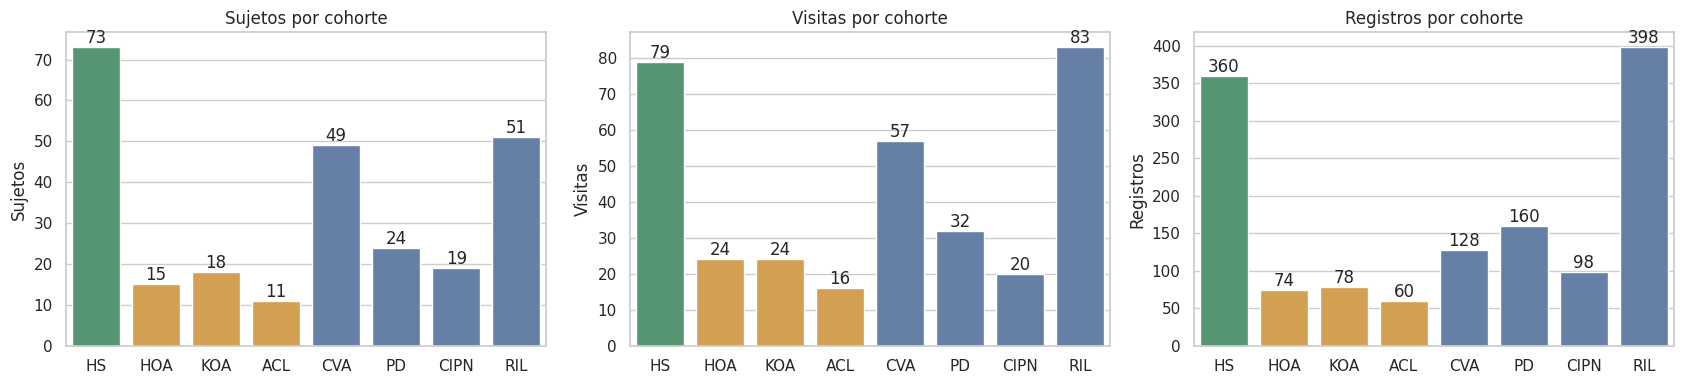

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for ax, col in zip(axes, ["sujetos", "visitas", "registros"]):
    sns.barplot(x=tabla_cohortes.index, y=tabla_cohortes[col], hue=tabla_cohortes.index,
                palette=PALETA, legend=False, ax=ax)
    for cont in ax.containers:
        ax.bar_label(cont)
    ax.set_title(f"{col.capitalize()} por cohorte"); ax.set_xlabel(""); ax.set_ylabel(col.capitalize())
plt.tight_layout(); guardar_fig("2_1_tamano_cohortes"); plt.show()

CONCLUSIONES: hay desbalance importante entre cohortes.

- Personas con muchos registros y otras con pocos supone que unas personas pocas personas dominarían los resultados si se usaran los registros tal cual. **Decisión = Agregar por visita**: hacer la media de todos los registros de cada visita, de forma que cada visita queda como una sola fila. Así cada visita cuenta lo mismo, independientemente del número de registros realizados se hagan en un mismo día.
- Varias visitas de la misma persona implica que si una visita del paciente X está en entrenamiento y otra visita del paciente X está en la comprobación, el modelo no reconoce la patología, reconoce a la persona. Los resultados salen inflados y no fiables. **Decisión = Validar agrupando por sujeto**: obligar a que todos los datos de una misma persona vayan juntos, o todos a entrenamiento o todos a comprobación. Así el modelo siempre se evalúa con personas nuevas, que es lo que pasaría en la realidad con un paciente que llega a consulta.
- Cohortes de tamaños muy distintos, pueden provocar resultados inflados y engañosos. Un modelo que siempre prediga la clase mayoritaría aparentemente podría tener buena exactitud, pero realmente no es capaz de predecir la minoritaria. **Decisión = Emplear exactitud balanceada**: calcular el acierto de cada clase por separado y hacer la media para que cada patología cuente igual aunque tenga pocos pacientes.



### 2.2 Valores ausentes

Las columnas de la puntuación de la escala clínica y la valoración visual de la marcha deben tener valores numéricos, cuando no hay valor contienen el texto "Not evaluated", por lo que hay que convertir el texto a valor NaN. Una columna con números y texto mezclados no se puede usar para calcular medias ni correlaciones en los pasos siguientes.

In [ ]:
# bucle que recorre las columnas de valoraciones clínicas
for col in ["evaluationScoreValue", "visualGaitAssessment"]:
    original = df[col]
    df[col] = pd.to_numeric(original, errors="coerce")
    texto = original[df[col].isna() & original.notna()]
    print(f"{col}: {len(texto)} valores de texto convertidos a NaN")

ausentes = pd.DataFrame({
    "n ausentes": df.isna().sum(),
    "% ausentes": df.isna().mean().mul(100).round(1),
})

# visualizar solo las que tienen ausentes, si no aparecen, es por que no tienen
ausentes = ausentes[ausentes["n ausentes"] > 0].sort_values("n ausentes", ascending=False)
ausentes

evaluationScoreValue: 42 valores de texto convertidos a NaN
visualGaitAssessment: 56 valores de texto convertidos a NaN


,n ausentes,% ausentes
clinicalDeficitSide,956,70.5
TUG_s,901,66.4
evaluationScoreValue,402,29.6
laterality,63,4.6
visualGaitAssessment,56,4.1
BMI,20,1.5
weight_kg,20,1.5
height_m,10,0.7
age,5,0.4
shockAttenuation_L_dB,5,0.4


In [ ]:
cols = ["TUG_s", "clinicalDeficitSide", "evaluationScoreValue"]

# Nº de registros, nº de ausentes y % de ausentes por cohorte
tabla = df.groupby("pathologyKey")[cols].agg(
    lambda x: f"{x.isna().sum()} / {len(x)} ({x.isna().mean()*100:.0f} %)"
).loc[ORDEN]
tabla.columns = ["TUG ausentes", "Lado déficit ausentes", "Puntuación escala clínica ausentes"]
tabla

,TUG ausentes,Lado déficit ausentes,Puntuación escala clínica ausentes
pathologyKey,,,
HS,331 / 360 (92 %),360 / 360 (100 %),360 / 360 (100 %)
HOA,74 / 74 (100 %),0 / 74 (0 %),0 / 74 (0 %)
KOA,78 / 78 (100 %),0 / 78 (0 %),0 / 78 (0 %)
ACL,60 / 60 (100 %),0 / 60 (0 %),0 / 60 (0 %)
CVA,8 / 128 (6 %),0 / 128 (0 %),0 / 128 (0 %)
PD,80 / 160 (50 %),105 / 160 (66 %),0 / 160 (0 %)
CIPN,60 / 98 (61 %),98 / 98 (100 %),5 / 98 (5 %)
RIL,210 / 398 (53 %),393 / 398 (99 %),37 / 398 (9 %)


Los valores ausentes en las variables clínicas no son aleatorios, sino que dependen del protocolo de cada cohorte. El TUG no se registró en ninguna cohorte ortopédica (100 % ausente) y apenas en los sanos (92 %), mientras que en CVA se realizó casi siempre (6 % ausente) y en PD, CIPN y RIL en aproximadamente la mitad de los registros. El lado del déficit solo está disponible en las patologías unilaterales (HOA, KOA, ACL y CVA) y parcialmente en PD (34 %), y falta en sanos, CIPN y RIL, cuya afectación es bilateral. Dado que la presencia o ausencia de estas variables está ligada a la cohorte, su inclusión como entrada de los modelos permitiría identificar la patología sin información de la marcha. Por este motivo se van a excluir de los modelos de clasificación.

Para la estimación de severidad, se va a tener en cuenta la columna de "evaluationScoreValue", que es la puntuación de la escala clínica de cada patología. Se puede ver que está prácticamente completa en los sujetos con alguna patología, faltando unos pocos en RIL y CIPN. En los sanos faltan todos, pero es lógico dado que no tienen patología que puntuar y no se tendrán en cuenta en la estimación.

Para los pocos valores faltantes en los parámetros de la marcha, el valor se puede rellenar con la mediana de esa variable, calculándose dentro del pipeline de cada modelo, es decir, la mediana se calcularía solo con los datos de entrenamiento de cada partición, para no usar información del test.

In [ ]:
# Eliminar registros que no tengan ningún parámetro
vacios = df[BIOMECH].isna().all(axis=1)
print("Registros sin ningún parámetro de marcha:", vacios.sum())
df = df[~vacios].reset_index(drop=True)

Registros sin ningún parámetro de marcha: 0


No hay ningún registro sin ningun parámetro de marcha

### 2.3 Estadística descriptiva y valores extremos

Se comprueba la plausibilidad fisiológica y se buscan valores extremos dentro de cada cohorte con el z-score robusto (mediana y MAD). También se revisa el número de ciclos por registro, porque la variabilidad calculada con pocos ciclos es poco fiable.

In [ ]:
# calcula media, desviación, mínimo, cuartiles y máximo de cada parámetro
desc = df[BIOMECH + ["nCycles_L", "nCycles_R"]].describe().T.round(3)
guardar_tabla(desc, "2_3_descriptiva_global")
desc

,count,mean,std,min,25%,50%,75%,max
cadence_stepsPerMin,1356.0,105.734,13.112,46.649,98.133,106.748,114.379,151.188
strideTime_L_s,1356.0,1.182,0.177,0.803,1.076,1.152,1.247,2.550
strideTime_R_s,1356.0,1.180,0.177,0.819,1.073,1.150,1.245,2.536
stepTime_s,1356.0,0.592,0.086,0.409,0.540,0.577,0.624,1.243
stancePhase_L_pct,1356.0,63.969,3.561,43.921,61.899,63.469,65.532,85.538
stancePhase_R_pct,1356.0,64.210,3.450,54.422,62.191,63.883,65.715,83.208
doubleSupport_pct,1356.0,26.546,5.950,9.027,22.949,25.774,29.187,68.446
asymmetry_strideTime_pct,1356.0,1.023,1.060,0.000,0.363,0.805,1.334,13.655
strideLength_L_m,1356.0,1.136,0.304,0.218,0.947,1.158,1.357,1.999
strideLength_R_m,1356.0,1.154,0.303,0.184,0.944,1.181,1.384,1.929


Se comprueban los rangos de las variables más básicas de la marcha (velocidad, cadencia, tiempo y longitud de zancada, fase de apoyo, doble apoyo) y cuyos límites se conocen con seguridad.

Para el resto de parámetros, no hay límite suniversales aceptados, ya que dependen del sensor y algoritmo utilizado en cada caso.

En el caso de variablidades, en pacientes graves puede ser alta y ser real, por lo que establecer un tope podría marcar errores que no lo son.

Para comprobar que los sensores miden correctamente, se mide la variabilidad de una variable de referencia, en este caso el tiempo de zancada, de los sujetos sanos. Esto es útil porque de lo sanos esperamos que haya poca variabilidad 2-5%, si esta variabilidad es coherente, se puede determinar que el resto también lo son.

In [ ]:
# rangos posibles
RANGOS = {
    "cadence_stepsPerMin": (40, 180), "gaitSpeed_ms": (0.1, 2.5), "doubleSupport_pct": (0, 60),
    "strideTime_L_s": (0.6, 2.5), "strideTime_R_s": (0.6, 2.5),
    "stancePhase_L_pct": (45, 85), "stancePhase_R_pct": (45, 85),
    "strideLength_L_m": (0.2, 2.0), "strideLength_R_m": (0.2, 2.0),
}
fuera = pd.Series({c: ((df[c] < lo) | (df[c] > hi)).sum() for c, (lo, hi) in RANGOS.items()},
                  name="registros fuera de rango")
display(fuera.to_frame())

# Saber en concreto la descripcion de los datos de los sanos
print("Variabilidad del tiempo de zancada en sanos (CV %):")
display(df.loc[df["pathologyKey"] == "HS", "strideTime_cv_pct"].describe().round(2).to_frame().T)
print("Ciclos por registro (mínimo de ambos pies):")
display(df[["nCycles_L", "nCycles_R"]].min(axis=1).describe().round(1).to_frame("ciclos").T)

# Registros con pocos ciclos
ciclos = df[["nCycles_L", "nCycles_R"]].min(axis=1)
for limite in [5, 8]:
    n = (ciclos < limite).sum()
    print(f"Registros con menos de {limite} ciclos: {n} ({n / len(df) * 100:.1f} %)")

,registros fuera de rango
cadence_stepsPerMin,0
gaitSpeed_ms,0
doubleSupport_pct,2
strideTime_L_s,2
strideTime_R_s,2
stancePhase_L_pct,2
stancePhase_R_pct,0
strideLength_L_m,0
strideLength_R_m,3


Variabilidad del tiempo de zancada en sanos (CV %):


,count,mean,std,min,25%,50%,75%,max
strideTime_cv_pct,360.0,4.69,2.64,1.38,3.29,4.16,5.35,30.86


Ciclos por registro (mínimo de ambos pies):


,count,mean,std,min,25%,50%,75%,max
ciclos,1356.0,14.6,7.3,2.0,10.0,13.0,17.0,68.0


Registros con menos de 5 ciclos: 6 (0.4 %)
Registros con menos de 8 ciclos: 77 (5.7 %)


La mayoría de los registros incluye un número suficiente de ciclos de marcha para estimar la variabilidad, la mediana es de 13 ciclos y tres de cada cuatro registros tienen 10 o más (RIC 10–17). Una minoría presenta pocos ciclos (6 registros con menos de 5 y 77 con menos de 8, el 5,7 %), en los que la variabilidad es menos fiable. Estos registros se mantienen, dado que su efecto se atenúa al promediar por visita, pero se señala como una limitación del estudio.

No hay casi registros con valores fuera de rango. En velocidad, cadencia, fase de apoyo derecha y longitud de zancada izquierda hay 0 registros fuera. Sin embargo, hay que comprobar los registros que se salen del rango y analizar si son fallos o son resultados coherentes.

In [ ]:
filas = []
for col, (lo, hi) in RANGOS.items():
    fuera_col = df[(df[col] < lo) | (df[col] > hi)]
    for _, r in fuera_col.iterrows():
        filas.append({
            "parámetro": col,
            "trial_id": r["trial_id"],
            "cohorte": r["pathologyKey"],
            "valor": round(r[col], 4),
            "rango permitido": f"{lo} – {hi}",
            "problema": "por debajo" if r[col] < lo else "por encima",
        })

tabla_fuera = pd.DataFrame(filas)
tabla_fuera

,parámetro,trial_id,cohorte,valor,rango permitido,problema
0,doubleSupport_pct,RIL_4_1,RIL,68.4455,0 – 60,por encima
1,doubleSupport_pct,KOA_18_1,KOA,64.8555,0 – 60,por encima
2,strideTime_L_s,RIL_22_4,RIL,2.5277,0.6 – 2.5,por encima
3,strideTime_L_s,RIL_22_5,RIL,2.5496,0.6 – 2.5,por encima
4,strideTime_R_s,RIL_22_4,RIL,2.5080,0.6 – 2.5,por encima
5,strideTime_R_s,RIL_22_5,RIL,2.5356,0.6 – 2.5,por encima
6,stancePhase_L_pct,PD_23_3,PD,43.9212,45 – 85,por debajo
7,stancePhase_L_pct,RIL_4_1,RIL,85.5377,45 – 85,por encima
8,strideLength_R_m,CVA_5_1,CVA,0.1999,0.2 – 2.0,por debajo
9,strideLength_R_m,RIL_4_5,RIL,0.1905,0.2 – 2.0,por debajo


In [ ]:
# Registros fuera de rango (para ver todos sus parámetros en conjunto)
mascara = pd.concat({c: (df[c] < lo) | (df[c] > hi) for c, (lo, hi) in RANGOS.items()}, axis=1)
raros = df[mascara.any(axis=1)]
display(raros[["trial_id", "pathologyKey", "gaitSpeed_ms", "cadence_stepsPerMin",
               "strideTime_L_s", "strideTime_R_s", "doubleSupport_pct", "stancePhase_L_pct",
               "strideLength_L_m", "strideLength_R_m"]])

,trial_id,pathologyKey,gaitSpeed_ms,cadence_stepsPerMin,strideTime_L_s,strideTime_R_s,doubleSupport_pct,stancePhase_L_pct,strideLength_L_m,strideLength_R_m
466,CVA_5_1,CVA,0.244721,105.816135,1.162500,1.160444,29.359028,54.388477,0.357057,0.199913
738,PD_23_3,PD,1.273346,151.187905,0.802857,0.819375,9.026600,43.921216,1.037362,1.029702
764,RIL_4_1,RIL,0.115212,49.037905,2.382364,2.363214,68.445515,85.537683,0.328821,0.209690
768,RIL_4_5,RIL,0.127178,67.523346,1.765588,1.797794,58.980517,83.701870,0.262082,0.190547
872,RIL_22_4,RIL,0.302723,48.456879,2.527692,2.508000,51.608696,74.530129,0.742446,0.782091
873,RIL_22_5,RIL,0.302182,46.648794,2.549630,2.535600,48.318428,68.897238,0.747433,0.790234
1237,HOA_7_2,HOA,0.136662,82.062073,1.471905,1.470794,55.674683,77.725221,0.217507,0.184380
1355,KOA_18_1,KOA,0.217753,84.775087,1.461304,1.458182,64.855517,83.800564,0.320337,0.315287


Se puede observar lo siguiente:
- CVA_5_1: la zancada derecha tiene un valor justo por debajo del límite establecido, pero su resultado es coherente, ya que la zancada izquierda mide 0,36m, verificándose que un lado da pasos más cortos, típico de la hemiparesia tras ictus.
- PD_23_3: fase de apoyo por debajo (43,9 %), pero en este caso el paciente anda rápido (1,27 m/s, cadencia 151), y al andar rápido el apoyo se acorta. Es coherente.
- RIL_4_1: falla en doble apoyo (68 %) y fase de apoyo (85,5 %). Esto tiene sentido, ya que las dos cosas significan lo mismo, que el paciente pasa casi todo el tiempo con los pies en el suelo. Es lo esperable en alguien que anda muy despacio (0,12 m/s) y con mucha inestabilidad.
- RIL_4_5: zancada derecha por debajo del límite (0,19 m). Es el mismo paciente que RIL_4_1 en otro registro, y vuelve a mostrar una marcha muy lenta (0,13 m/s) con pasos cortos y mucho tiempo en apoyo (doble apoyo del 59 % y fase de apoyo del 84 %, ambos justo por debajo de sus límites). Que el patrón se repita en dos registros distintos confirma que es su forma de andar.
- RIL_22_4 y RIL_22_5: tiempo de zancada por encima del límite en las dos piernas (2,51–2,55 s). Son dos registros del mismo paciente con valores casi idénticos. El paciente anda muy despacio (0,30 m/s) y con una cadencia muy baja (47–48 pasos/min), lo que implica zancadas largas en el tiempo. Un fallo del sensor afectaría a una sola pierna o a un solo registro, no a ambas piernas en dos registros por igual.
- HOA_7_2: zancada derecha por debajo del límite (0,18 m). La izquierda también es muy corta (0,22 m) y la velocidad es muy baja (0,14 m/s), con mucho tiempo en apoyo (doble apoyo del 56 %). Es coherente con un paciente con artrosis de cadera muy limitado, que acorta los pasos, sobre todo del lado afectado.
- KOA_18_1: doble apoyo por encima del límite (64,9 %). El resto de parámetros como velocidad muy baja (0,22 m/s), zancadas cortas (0,32 m) y fase de apoyo alta (84 %) son coherentes con un paciente con artrosis de rodilla que busca estabilidad y reduce la carga en cada pierna manteniendo los dos pies apoyados el mayor tiempo posible.


Como conclusión, los registros fuera de rango apuntan a no ser errores de medida, sino a pacientes con la marcha algo más alterada, pero sus valores son coherentes entre parámetros. Se decide mantener estos registros.

También se comprueba la variabilidad en sanos, ya que sirven de referencia para validar las medidas en el resto de casos.

In [ ]:
# Umbral de valor atípico (regla del RIC) en la variabilidad de los sanos
cv_hs = df.loc[df["pathologyKey"] == "HS", "strideTime_cv_pct"]
q1, q3 = cv_hs.quantile([0.25, 0.75])
umbral = q3 + 1.5 * (q3 - q1)
print(f"Umbral: {umbral:.1f} %")

# Sanos por encima del umbral
atipicos = df[(df["pathologyKey"] == "HS") & (df["strideTime_cv_pct"] > umbral)]
print(f"Registros atípicos: {len(atipicos)} de {len(cv_hs)}")
atipicos[["trial_id", "age", "strideTime_cv_pct", "nCycles_L", "nCycles_R"]]

Umbral: 8.4 %
Registros atípicos: 17 de 360


,trial_id,age,strideTime_cv_pct,nCycles_L,nCycles_R
15,HS_4_3,83.0,12.252313,16,15
16,HS_4_4,83.0,8.781565,15,16
21,HS_4_9,83.0,10.335440,17,17
61,HS_8_1,18.0,11.412901,8,7
117,HS_19_3,61.0,25.055745,16,15
120,HS_20_1,87.0,14.756637,18,20
121,HS_20_2,87.0,18.385728,21,19
127,HS_22_1,42.0,9.486851,12,11
155,HS_28_3,19.0,11.271431,8,8
156,HS_28_4,19.0,30.861218,8,8


Los 17 registros son de 12 sujetos, porque cuatro de ellos aparecen más de una vez.
- HS_4, HS_20 y HS_50 (personas mayores): el CV alto se repite con valores parecidos entre registros y con muchos ciclos. Eso indica que es su forma de andar, algo estable en la persona, no un fallo puntual.
- HS_22_1, HS_73_2, HS_65_2: variabilidad algo alta pero no anómala, están en el extremo de la normalidad.
- HS_8_1, HS_32_4, HS_52_2, HS_58_2, HS_65_2: tienen entre 3 y 10 ciclos en ese registro. Con tan pocas zancadas, una sola mal detectada podría provocar que se dispare el valor.
- HS_19_3: corresponde a una persona joven y tiene suficientes ciclos, puede ser una marcha irregular puntual, no obstante, se decide mantener al no haber prueba suficiente de que sea un error y al promediar los registros de la visita de este sujeto el valor se mezcla con los demás y su efecto se reduce bastante.

Entonces se puede afirmar que el sistema de medida es fiable y los errores son raros, siendo la gran mayoría explicables de forma razonada.

In [ ]:
# ver los de mayor ciclos, las zancadas son cortas al igual que la velocidad, pacientes con pasos pequeños
ciclos = df[["nCycles_L", "nCycles_R"]].min(axis=1)
df.assign(ciclos=ciclos).nlargest(5, "ciclos")[
    ["trial_id", "pathologyKey", "ciclos", "strideLength_L_m", "gaitSpeed_ms", "protocolDistance_m"]]

,trial_id,pathologyKey,ciclos,strideLength_L_m,gaitSpeed_ms,protocolDistance_m
768,RIL_4_5,RIL,68,0.262082,0.127178,10.00
1237,HOA_7_2,HOA,63,0.217507,0.136662,7.25
504,CVA_20_1,CVA,61,0.362085,0.249925,10.00
1068,RIL_42_2,RIL,61,0.280447,0.223643,10.00
505,CVA_20_2,CVA,59,0.239353,0.178937,10.00


### 2.4 Coherencia de las escalas clínicas
Antes de usar las puntuaciones clínicas se comprueba que su sentido coincide con la documentación del dataset (Voisard et al., Tabla 2), ya que cada patología tiene su propia escala clínica, y no todas van en el mismo sentido.
- Si la escala es alto = peor, los pacientes con puntuación alta deberían andar más lento → correlación negativa.
- Si la escala es alto = mejor, los pacientes con puntuación alta deberían andar más rápido → correlación positiva.

Para cada cohorte, calcula la correlación de Spearman (ρ) entre la puntuación y la velocidad. Va de −1 a +1:

- Cerca de +1: cuanto más alta la puntuación, más rápido andan.
- Cerca de −1: cuanto más alta la puntuación, más lento andan.
- Cerca de 0: no hay relación.

Se usa Spearman porque solo mira si cuando una variable sube, la otra tiende a subir (o a bajar), sin importar si es en línea recta. La tendencia es lo que interesa comprobar para después hacer bien la estimación de la severidad.

In [ ]:
SENTIDO_DOC = {"HOA": "alto = peor", "KOA": "alto = peor", "ACL": "alto = mejor", "CVA": "alto = mejor",
               "PD": "alto = peor", "CIPN": "alto = peor", "RIL": "alto = peor"}
ESCALA_DE = {"HOA": "WOMAC", "KOA": "WOMAC", "ACL": "IKDC", "CVA": "FMA-LE",
             "PD": "UPDRS III", "CIPN": "TNSc", "RIL": "OCS"}

vis_tmp = df.groupby(["pathologyKey", "subject", "session"])[["evaluationScoreValue", "gaitSpeed_ms"]].mean().dropna()
filas = []
for p in SENTIDO_DOC:
    d = vis_tmp.loc[p]
    rho, pval = spearmanr(d["evaluationScoreValue"], d["gaitSpeed_ms"])
    esperado = "−" if SENTIDO_DOC[p] == "alto = peor" else "+"
    filas.append({"cohorte": p, "escala": ESCALA_DE[p], "según documentación": SENTIDO_DOC[p],
                  "signo esperado": esperado, "ρ score–velocidad": round(rho, 2), "p": round(pval, 4),
                  "¿coherente?": "sí" if (rho > 0) == (esperado == "+") or pval > 0.05 else "NO"})
coherencia = pd.DataFrame(filas).set_index("cohorte")
guardar_tabla(coherencia, "2_4_coherencia_escalas")
coherencia

,escala,según documentación,signo esperado,ρ score–velocidad,p,¿coherente?
cohorte,,,,,,
HOA,WOMAC,alto = peor,−,0.60,0.0018,NO
KOA,WOMAC,alto = peor,−,0.78,0.0000,NO
ACL,IKDC,alto = mejor,+,0.76,0.0007,sí
CVA,FMA-LE,alto = mejor,+,0.60,0.0000,sí
PD,UPDRS III,alto = peor,−,-0.05,0.7816,sí
CIPN,TNSc,alto = peor,−,0.02,0.9256,sí
RIL,OCS,alto = peor,−,-0.58,0.0000,sí


**Interpretación.**

- **ACL (ρ = 0,76), CVA (ρ = 0,60) y RIL (ρ = −0,58):** correlaciones significativas y en el sentido que indica la documentación. En estas cohortes, la escala clínica está claramente relacionada con la marcha.
- **HOA (ρ = 0,60; p = 0,002) y KOA (ρ = 0,78; p < 0,001):** la WOMAC correlaciona de forma **positiva** y significativa con la velocidad, es decir, los pacientes con puntuación más alta andan más rápido. Esto contradice la documentación (alto = peor) y coincide con el patrón de las escalas en las que alto = mejor.
- **PD (ρ = −0,05) y CIPN (ρ = 0,02):** no se observa evidencia significativa de que haya relación entre la escala y la velocidad. Se marcan como coherentes porque no hay evidencia en contra, pero tampoco confirman el sentido. Es esperable, ya que la UPDRS III y la TNSc evalúan síntomas (temblor, rigidez, alteraciones sensitivas) que no se reflejan principalmente en la velocidad de marcha.

**Decisión.** Se considera que en este dataset la WOMAC está almacenada en su versión normalizada (100 = mejor estado), al contrario de lo indicado en la documentación, por lo que en el análisis de severidad (sección 7) se trata como alto = mejor. Esta discrepancia se señala en la memoria. Además, la ausencia de relación con la velocidad en PD y CIPN anticipa que la estimación de la severidad será más difícil en estas cohortes.

### 2.5 Agregación por visita
Todos los registros de una misma visita comparten sujeto, fecha y score clínico, así que se promedian por visita. Como se ha decidido antes, cada visita pasa a ser una observación para evitar el problema de que los modelos aprendan a identificar a sujetos concretos.

Se promedia todos los registros de cada visita, de modo que cada visita pasa a ser una fila de la nueva tabla "V". A partir de aquí los modelos usan "V". Para la cohorte, la edad, el sexo, la altura, el peso, el IMC, el sensor y la puntuación clínica, coge el primer valor. No tiene sentido hacer la media de estas columnas porque son iguales en todos los paseos de una misma visita: el paciente tiene la misma edad, la misma patología y la misma puntuación clínica en todos sus paseos de ese día.

In [ ]:
# agregación por visita
agg = {c: "mean" for c in BIOMECH}
agg.update({c: "first" for c in ["group", "pathologyKey", "age", "gender", "height_m", "weight_kg",
                                   "BMI", "sensor", "evaluationScoreValue"]})
agg["trial_id"] = "count"
V = (df.groupby(["subject", "session"]).agg(agg)
       .rename(columns={"trial_id": "n_registros"}).reset_index())
print(f"{len(df)} registros → {len(V)} visitas de {V['subject'].nunique()} sujetos")
V.groupby("pathologyKey").size().loc[ORDEN].to_frame("visitas").T

1356 registros → 335 visitas de 260 sujetos


pathologyKey,HS,HOA,KOA,ACL,CVA,PD,CIPN,RIL
visitas,79,24,24,16,57,32,20,83


## 3. Análisis descriptivo por cohorte

### 3.1 Perfil de cada cohorte
Aquí se describe describe a las personas para poder interpretar bien su marcha después y para detectar dos factores (edad y sensor) que podrían confundir los resultados.

Se resume, por cohorte, el número de sujetos, la edad, el % de mujeres, la altura, el IMC y el % de registros hechos con cada sensor. Esta sección vigila dos posibles factores de confusión:

- La edad: los sanos son más jóvenes que la mayoría de pacientes.
- El sensor: en el dataset se usaron dos marcas de sensor (XSens y Technoconcept), y algunas cohortes se registraron casi solo con una. Si una marca mide un poco distinto, el modelo podría aprender a reconocer el sensor en vez de la patología.

In [ ]:
sujetos = df.drop_duplicates("subject")
media_sd = lambda x: f"{x.mean():.1f} ({x.std():.1f})"
perfil = sujetos.groupby("pathologyKey").agg(
    sujetos=("subject", "count"), edad=("age", media_sd),
    mujeres_pct=("gender", lambda g: round((g == "F").mean() * 100)),
    altura_m=("height_m", lambda x: f"{x.mean():.2f} ({x.std():.2f})"), IMC=("BMI", media_sd),
).loc[ORDEN]
sensor_pct = (pd.crosstab(df["pathologyKey"], df["sensor"], normalize="index") * 100).round(0).loc[ORDEN]
perfil = perfil.join(sensor_pct.add_prefix("% "))
guardar_tabla(perfil, "3_1_perfil_cohortes")
perfil

,sujetos,edad,mujeres_pct,altura_m,IMC,% MTw Awinda XSens,% TechnoConcept
pathologyKey,,,,,,,
HS,73,39.8 (20.2),44,1.71 (0.11),24.0 (4.3),72.0,28.0
HOA,15,69.7 (13.2),53,1.69 (0.12),25.2 (4.2),100.0,0.0
KOA,18,69.7 (13.7),61,1.68 (0.09),31.0 (6.1),100.0,0.0
ACL,11,36.7 (11.9),36,1.74 (0.11),23.7 (3.0),100.0,0.0
CVA,49,59.0 (9.5),24,1.70 (0.08),26.1 (5.0),0.0,100.0
PD,24,74.2 (11.4),29,1.71 (0.08),23.7 (4.3),16.0,84.0
CIPN,19,63.4 (10.5),47,1.71 (0.09),24.3 (4.5),5.0,95.0
RIL,51,59.8 (13.8),45,1.68 (0.09),24.8 (3.9),17.0,83.0


**Interpretación.** Las cohortes difieren en dos características que pueden actuar como factores de confusión:

- **Edad:** los sujetos sanos (39,8 ± 20,2 años) son más jóvenes que todas las cohortes de pacientes salvo ACL (36,7 ± 11,9). Las cohortes neurológicas y de artrosis tienen entre 59 y 74 años de media, siendo PD la de mayor edad. Parte de las diferencias de marcha entre sanos y pacientes podría deberse a la edad, lo que se evalúa en la sección 5.6.1.
- **Sensor:** las cohortes ortopédicas se registraron exclusivamente con XSens y CVA exclusivamente con Technoconcept, mientras que PD, CIPN y RIL se registraron mayoritariamente con Technoconcept (83–95 %). Por tanto, el tipo de sensor coincide casi por completo con el grupo de patología (ortopédico frente a neurológico). Los sujetos sanos, registrados con ambos sensores, permiten evaluar este efecto (secciones 3.5 y 5.6.2). Al comparar sanos con pacientes o comparar entre diferentes cohortes, parte de las diferencias de marcha pueden deberse a la edad, esto se debe comprobar más adelante.

La altura es similar entre cohortes (1,68–1,74 m) y se normaliza en la sección 4. El IMC es comparable salvo en KOA (31,0), coherente con el papel del sobrepeso en la artrosis de rodilla. Existen desequilibrios en la proporción de mujeres (24 % en CVA frente a 61 % en KOA), que se señalan como limitación.

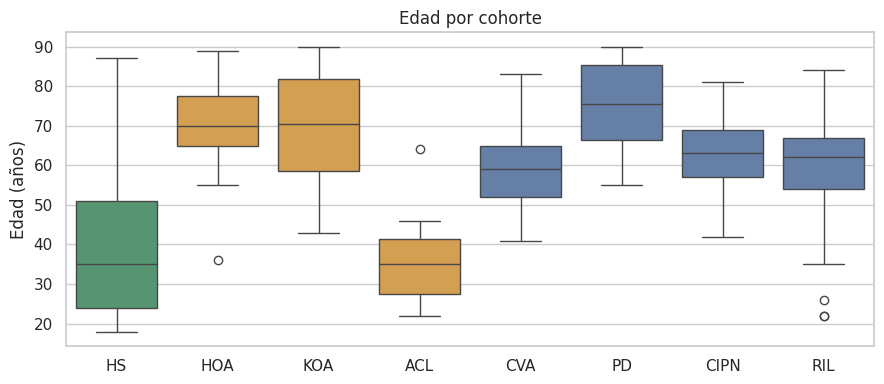

In [ ]:
# distribución edad de cada cohorte
plt.figure(figsize=(9, 4))
sns.boxplot(data=sujetos, x="pathologyKey", y="age", order=ORDEN, hue="pathologyKey", palette=PALETA, legend=False)
plt.title("Edad por cohorte"); plt.xlabel(""); plt.ylabel("Edad (años)")
plt.tight_layout(); guardar_fig("3_1_edad_por_cohorte"); plt.show()

### 3.2 Efecto del sensor en la medida

In [ ]:
# Evitar columnas y variables duplicadas
df = df.loc[:, ~df.columns.duplicated()]
BIOMECH = list(dict.fromkeys(BIOMECH))

# Variables independientes del lado: izquierda/derecha → media y asimetría
PARES = {
    "strideTime_s":           ("strideTime_L_s", "strideTime_R_s"),
    "stancePhase_pct":        ("stancePhase_L_pct", "stancePhase_R_pct"),
    "strideLength_m":         ("strideLength_L_m", "strideLength_R_m"),
    "footStrikeAngle_deg":    ("footStrikeAngle_L_deg", "footStrikeAngle_R_deg"),
    "shockAttenuation_dB":    ("shockAttenuation_L_dB", "shockAttenuation_R_dB"),
    "stancePhase_sd_pct":     ("stancePhase_L_sd_pct", "stancePhase_R_sd_pct"),
    "footStrikeAngle_sd_deg": ("footStrikeAngle_L_sd_deg", "footStrikeAngle_R_sd_deg"),
    "shockAttenuation_sd_dB": ("shockAttenuation_L_sd_dB", "shockAttenuation_R_sd_dB"),
}
ASIM_NUEVAS = {
    "asymmetry_stancePhase_pct":     ("stancePhase_L_pct", "stancePhase_R_pct"),
    "asymmetry_footStrikeAngle_deg": ("footStrikeAngle_L_deg", "footStrikeAngle_R_deg"),
}
LATERALES = {c for par in PARES.values() for c in par} | {
    "strideTime_L_cv_pct", "strideTime_R_cv_pct", "strideLength_L_cv_pct", "strideLength_R_cv_pct"}

def a_bilateral(d):
    out = d[[c for c in BIOMECH if c not in LATERALES]].copy()
    for nueva, (izq, dcha) in PARES.items():
        out[nueva] = d[[izq, dcha]].mean(axis=1)
    for nueva, (izq, dcha) in ASIM_NUEVAS.items():
        out[nueva] = (d[izq] - d[dcha]).abs()
    return out

es_variab = lambda c: "_cv_" in c or "_sd_" in c
columnas = a_bilateral(df.head()).columns
MEDIAS_BIL = [c for c in columnas if not es_variab(c)]
VARIAB_BIL = [c for c in columnas if es_variab(c)]
BIOMECH_BIL = list(dict.fromkeys(MEDIAS_BIL + VARIAB_BIL))

# Primera visita de cada sujeto y un valor por sujeto (mediana de sus registros)
primera = df.groupby("subject")["daysSinceFirstSession"].transform("min")
df_base = df[df["daysSinceFirstSession"] == primera]
df_bil = pd.concat([df_base[["pathologyKey", "subject"]], a_bilateral(df_base)], axis=1)
med_sujeto = df_bil.groupby(["pathologyKey", "subject"])[BIOMECH_BIL].median().reset_index()

# Sensor con el que se midió a cada sujeto
sensor_sujeto = df_base.groupby("subject")["sensor"].agg(lambda s: s.mode()[0])
med_sujeto["sensor"] = med_sujeto["subject"].map(sensor_sujeto)

# Tamaño del efecto: delta de Cliff
def cliff_delta(a, b):
    a, b = np.asarray(a), np.asarray(b)
    return np.sign(a[:, None] - b[None, :]).mean()

print(f"Variables: {len(BIOMECH_BIL)} ({len(MEDIAS_BIL)} medias + {len(VARIAB_BIL)} variabilidad)")
print(f"Sujetos: {med_sujeto['subject'].nunique()}")

Variables: 23 (16 medias + 7 variabilidad)
Sujetos: 260


In [ ]:
# ¿Influye el sensor? (Sanos XSens vs sanos TechnoConcept)
hs = df[(df["pathologyKey"] == "HS") & (df["age"] >= 45)]
hs_bil = pd.concat([hs[["subject", "sensor", "age"]], a_bilateral(hs)], axis=1)
hs_mayores = hs_bil.groupby(["subject", "sensor"])[BIOMECH_BIL + ["age"]].median().reset_index()
print("Sanos ≥ 45 años por sensor:", hs_mayores["sensor"].value_counts().to_dict())

sensores = sorted(hs_mayores["sensor"].unique())
variables = BIOMECH_BIL + ["age"]
n_tests_sensor = len(variables)                     # Bonferroni

filas = []
for c in variables:
    a = hs_mayores.loc[hs_mayores["sensor"] == sensores[0], c].dropna()
    b = hs_mayores.loc[hs_mayores["sensor"] == sensores[1], c].dropna()
    d, p = cliff_delta(a, b), mannwhitneyu(a, b).pvalue
    p_corr = min(p * n_tests_sensor, 1)
    filas.append({"parámetro": c,
                  f"mediana {sensores[0]}": a.median(), f"mediana {sensores[1]}": b.median(),
                  "δ Cliff": d, "p": p, "p_bonferroni": p_corr,
                  "¿depende del sensor?": "SÍ" if (abs(d) > 0.47 and p_corr < 0.05)
                                          else ("indicio" if (abs(d) > 0.47 and p < 0.05) else "")})

efecto_sensor = (pd.DataFrame(filas).set_index("parámetro").round(3)
                   .sort_values("δ Cliff", key=abs, ascending=False))
guardar_tabla(efecto_sensor, "3_2_efecto_sensor")
efecto_sensor

Sanos ≥ 45 años por sensor: {'TechnoConcept': 12, 'MTw Awinda XSens': 10}


,mediana MTw Awinda XSens,mediana TechnoConcept,δ Cliff,p,p_bonferroni,¿depende del sensor?
parámetro,,,,,,
doubleSupport_sd_pct,4.703,3.555,0.933,0.000,0.006,SÍ
strideLength_cv_pct,6.179,10.018,-0.633,0.013,0.322,indicio
gaitSpeed_ms,1.013,1.245,-0.600,0.019,0.462,indicio
stancePhase_pct,64.371,62.528,0.533,0.038,0.907,indicio
asymmetry_strideTime_pct,0.848,0.540,0.517,0.044,1.000,indicio
strideLength_m,1.176,1.297,-0.500,0.052,1.000,
doubleSupport_pct,26.248,23.260,0.433,0.093,1.000,
stepTime_s,0.575,0.556,0.433,0.093,1.000,
shockAttenuation_sd_dB,1.400,1.178,0.417,0.106,1.000,


**Interpretación.** Las cohortes ortopédicas se registraron con XSens y las neurológicas mayoritariamente con TechnoConcept (sección 3.1), por lo que el sensor podría confundirse con el grupo de patología. Para evaluar su efecto se compararon los sujetos sanos de 45 años o más registrados con cada sistema (TechnoConcept, n = 12; XSens, n = 10), de edad comparable entre sí y similar a la de los pacientes, de modo que las diferencias observadas puedan atribuirse al sistema de medida.

Tras la corrección de Bonferroni, solo la variabilidad del doble apoyo mostró una dependencia clara del sensor (δ = 0,93; p corregido = 0,006), con valores más altos en XSens. Al tratarse de una fase breve del ciclo, cuya duración depende de la detección precisa del contacto y el despegue de ambos pies, pequeñas diferencias en la detección de estos eventos se traducen en diferencias relativas importantes en su variabilidad. Otros cuatro parámetros mostraron diferencias grandes que no se mantuvieron tras la corrección (variabilidad de la longitud de zancada, velocidad, fase de apoyo y asimetría del tiempo de zancada); en el caso de la velocidad, la diferencia puede reflejar además distintas poblaciones de sanos en cada centro. Dado el reducido tamaño de los grupos, estos resultados se consideran orientativos.

**Decisión.** Para que el sensor no influya en la caracterización de las patologías, cada patología se compara con los sujetos sanos registrados con su mismo sistema de medida (sección 3.4). Además, la variabilidad del doble apoyo se excluirá de los modelos de clasificación (sección 4).

Que el sensor XSens no mide el doble apoyo desplazado (siempre más largo o más corto), porque entonces también saldría distinta la media. Lo que hace es medirlo con algo más de imprecisión de un paso a otro, y esa imprecisión solo se nota en la variabilidad.

### 3.3 Parámetros de marcha por cohorte
¿Qué parámetros cambian más entre todas las cohortes en general?

Dado que en las patologías unilaterales el lado afectado varía entre pacientes, y que en las bilaterales la distinción entre lados no es informativa, los parámetros medidos en cada pierna se transformaron en variables independientes del lado: la media de ambos lados, que refleja el grado de alteración del parámetro, y su diferencia absoluta, que refleja la asimetría con independencia del lado afectado. De este modo, los perfiles obtenidos describen la patología y no la distribución del lado afectado en la muestra.

In [ ]:
# Tabla descriptiva: mediana [Q1–Q3] por cohorte
mediana_ric = lambda x: f"{x.median():.2f} [{x.quantile(.25):.2f}–{x.quantile(.75):.2f}]"
tabla_param = med_sujeto.groupby("pathologyKey")[BIOMECH_BIL].agg(mediana_ric).T[ORDEN]
guardar_tabla(tabla_param, "3_3_parametros_por_cohorte")

# Kruskal-Wallis: ¿difieren las cohortes en cada parámetro? ¿cuánto? (ε²)
filas = []
for p in BIOMECH_BIL:
    muestras = [g[p].dropna() for _, g in med_sujeto.groupby("pathologyKey")]
    H, pval = kruskal(*muestras)
    n = sum(len(m) for m in muestras)
    filas.append({"parámetro": p,
                  "tipo": "media" if p in MEDIAS_BIL else "variabilidad",
                  "H": H,
                  "p_bonferroni": min(pval * len(BIOMECH_BIL), 1),
                  "epsilon2": H / (n - 1)})

kw = pd.DataFrame(filas).set_index("parámetro").sort_values("epsilon2", ascending=False).round(4)
guardar_tabla(kw, "3_3_kruskal_wallis")
kw

,tipo,H,p_bonferroni,epsilon2
parámetro,,,,
strideLength_cv_pct,variabilidad,116.6124,0.0000,0.4502
shockAttenuation_dB,media,92.5852,0.0000,0.3589
stepTime_cv_pct,variabilidad,82.6577,0.0000,0.3191
gaitSpeed_ms,media,80.2568,0.0000,0.3099
strideLength_m,media,70.4387,0.0000,0.2720
stancePhase_sd_pct,variabilidad,60.6797,0.0000,0.2343
comVerticalAmplitude_m,media,60.6608,0.0000,0.2342
doubleSupport_pct,media,60.0449,0.0000,0.2318
footStrikeAngle_deg,media,60.0327,0.0000,0.2318


**Interpretación.** De los 23 parámetros, 19 difieren significativamente entre cohortes tras la corrección de Bonferroni. Los cuatro que no lo hacen (asimetría y variabilidad del ángulo de contacto del pie, variabilidad de la atenuación del impacto y asimetría del tiempo de zancada) no permiten distinguir entre patologías.

Los parámetros con mayor diferencia entre cohortes (efecto grande, ε² ≥ 0,26) son la variabilidad de la longitud de zancada (0,45), la atenuación del impacto (0,36), la variabilidad del tiempo de paso (0,32), la velocidad (0,31) y la longitud de zancada (0,27). Es decir, las cohortes se diferencian sobre todo en la cantidad de marcha (velocidad y longitud del paso), en la amortiguación del impacto y en la regularidad del paso. El resto de parámetros muestran efectos moderados (ε² ≈ 0,14–0,23); entre ellos, la cadencia, el tiempo de zancada y el tiempo de paso, así como la fase de apoyo y el doble apoyo, presentan valores similares por ser parámetros redundantes (sección 3.5).

En esta comparación las cohortes se registraron con sensores distintos, por lo que parte de las diferencias podría deberse al sistema de medida y no a la patología, especialmente en la variabilidad de la longitud de zancada (sección 3.2). Por ello, se considera una visión general, y la caracterización de cada patología se realiza en la sección 3.4 comparando con sanos registrados con el mismo sensor.

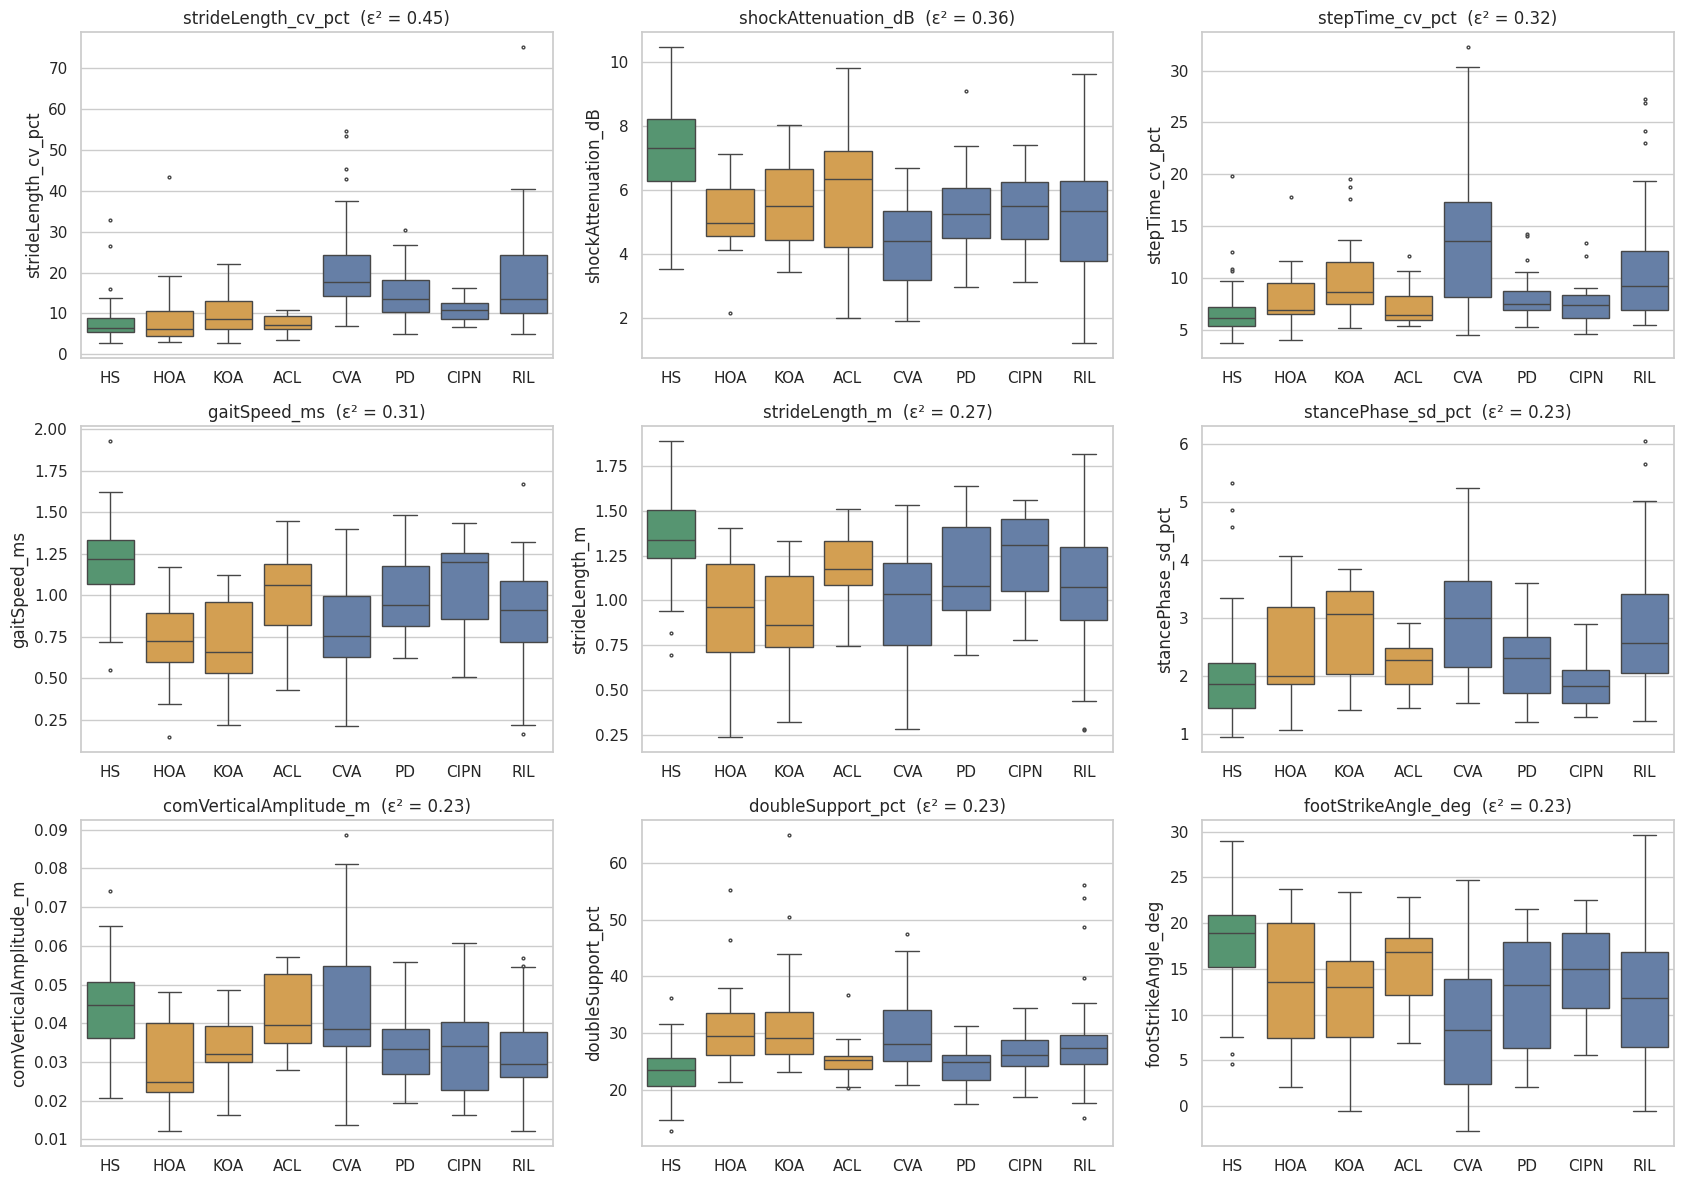

In [ ]:
# boxplots de distribución (los 9 parámetros con más ε²)
clave = kw.index[:9].tolist()
fig, axes = plt.subplots(3, 3, figsize=(17, 12))
for ax, col in zip(axes.ravel(), clave):
    sns.boxplot(data=med_sujeto, x="pathologyKey", y=col, order=ORDEN, hue="pathologyKey",
                palette=PALETA, legend=False, ax=ax, fliersize=2)
    ax.set_title(f"{col}  (ε² = {kw.loc[col, 'epsilon2']:.2f})")
    ax.set_xlabel("")
plt.tight_layout(); guardar_fig("3_3_boxplots_parametros"); plt.show()

**Interpretación de los boxplots.** Los parámetros con mayor tamaño del efecto muestran tres patrones:

- **Sanos frente a patologías:** la atenuación del impacto, la velocidad y la longitud de zancada son mayores en los sanos (medianas ≈ 7,3 dB, 1,22 m/s y 1,33 m) que en prácticamente todas las patologías. HOA y KOA son las cohortes más lentas y con pasos más cortos (≈ 0,7 m/s y 0,9 m).
- **Neurológicas frente a ortopédicas:** la variabilidad de la longitud de zancada es similar en sanos y cohortes ortopédicas (≈ 6–9 %) y mayor en las neurológicas, especialmente en CVA (≈ 18 %), PD y RIL (≈ 13–14 %). CVA es además la cohorte con mayor variabilidad del tiempo de paso y de la fase de apoyo y con menor atenuación del impacto. KOA también muestra una variabilidad algo elevada, por lo que la irregularidad no es exclusiva de las patologías neurológicas.
- **Cohortes próximas a la normalidad:** CIPN y ACL presentan valores cercanos a los de los sanos en la mayoría de parámetros (CIPN prácticamente igual en velocidad y longitud de zancada), lo que anticipa una mayor dificultad para distinguirlas.

La amplia dispersión de CVA y RIL refleja una gran heterogeneidad en el grado de afectación de sus pacientes, aspecto que se aborda en el análisis de la severidad (sección 7).

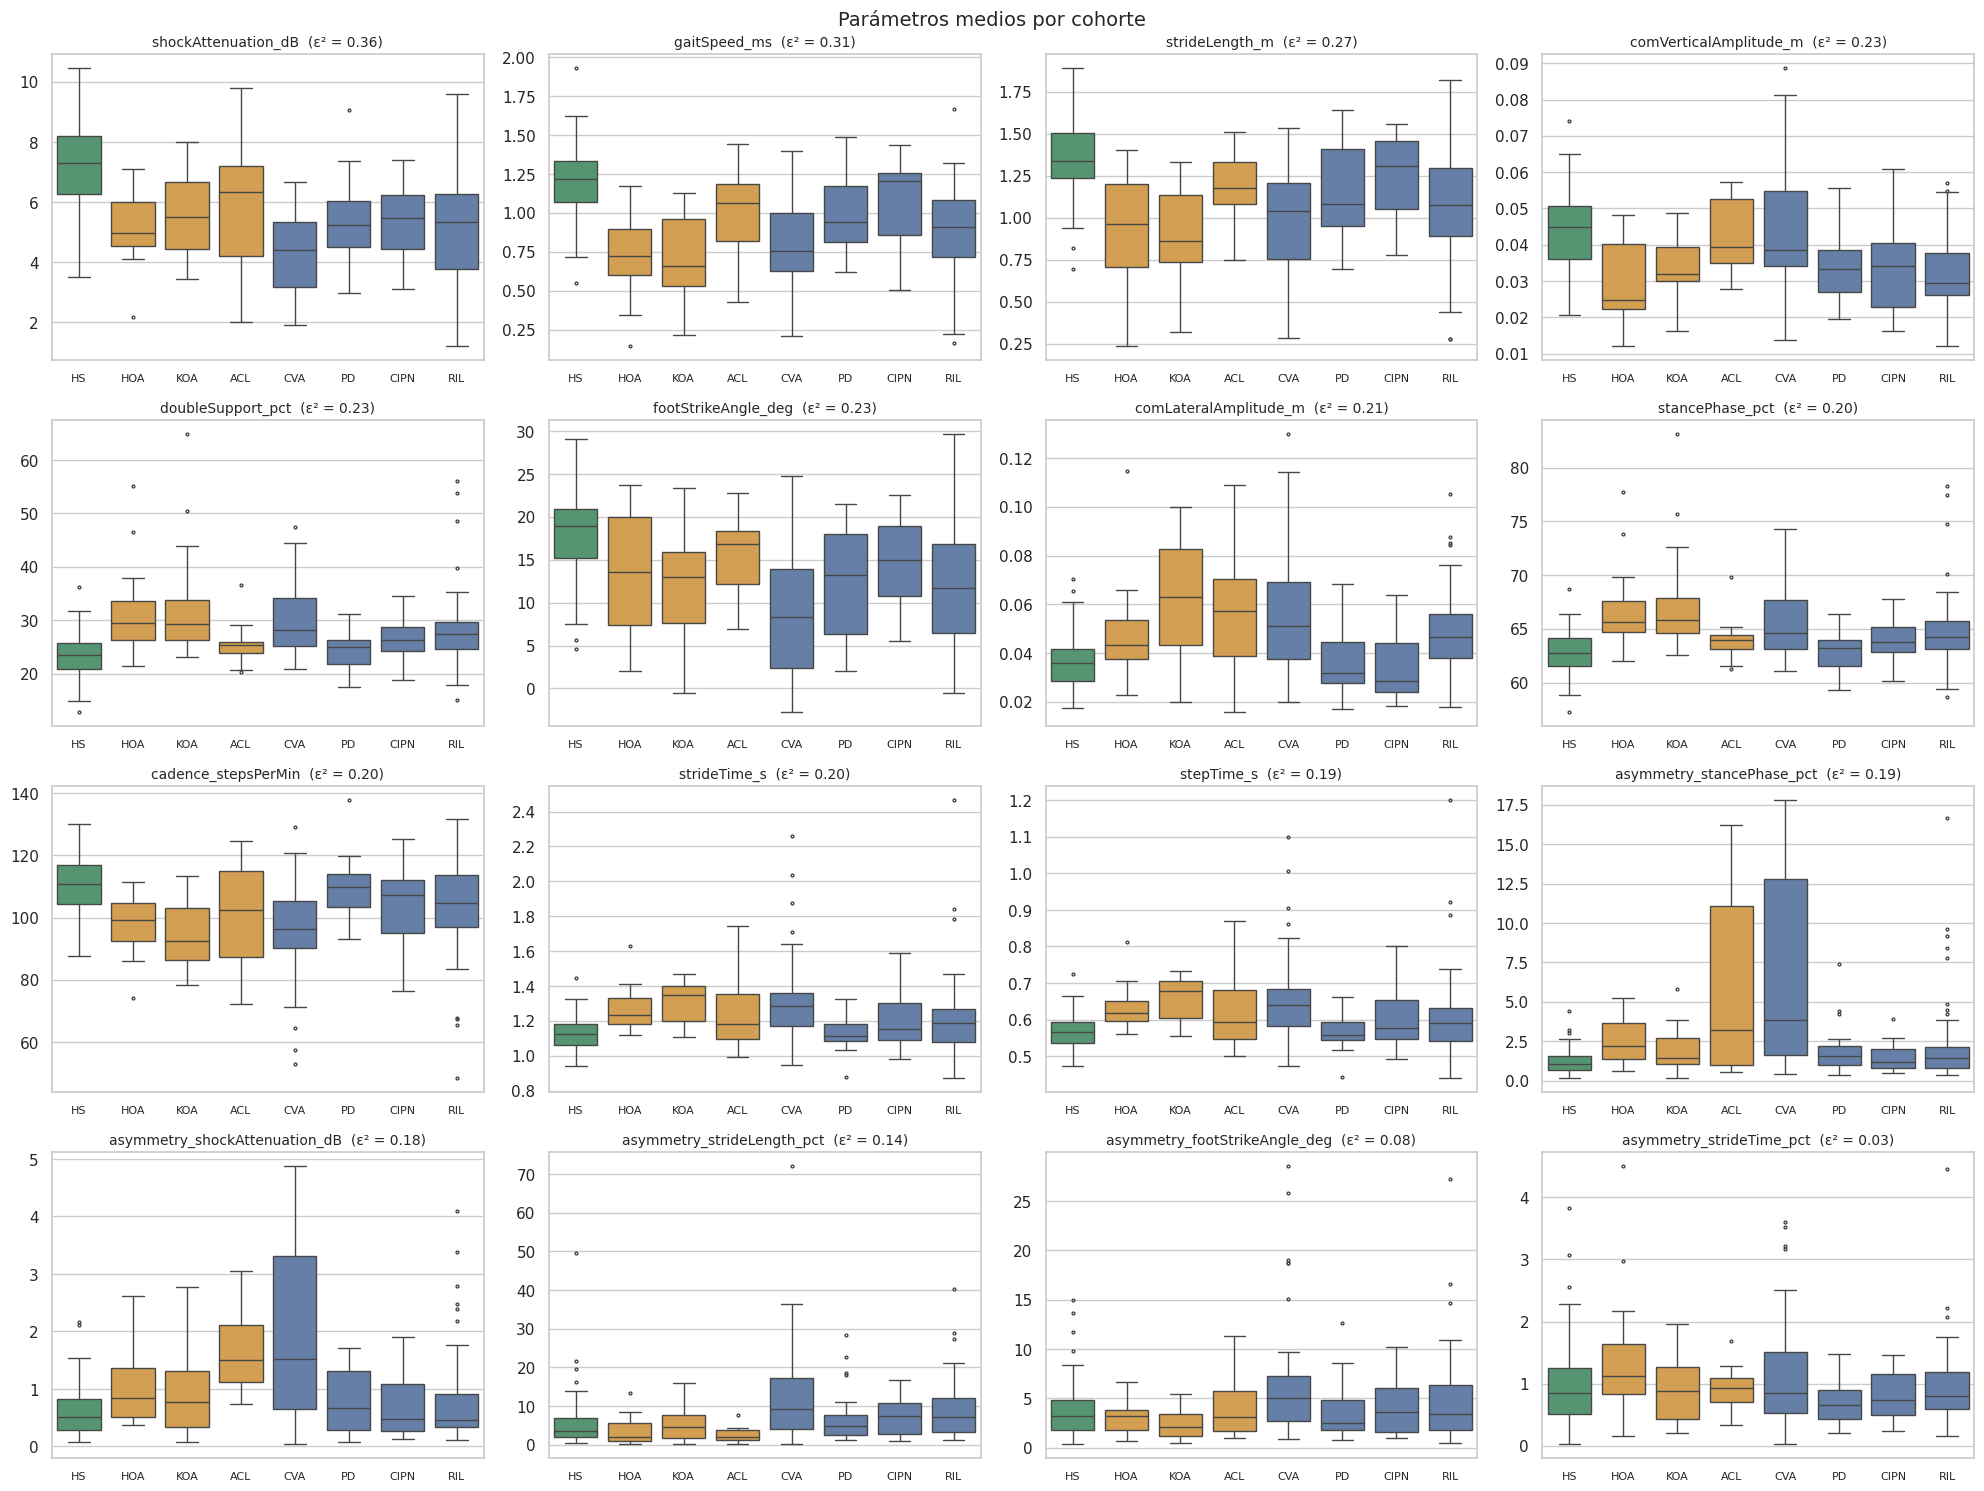

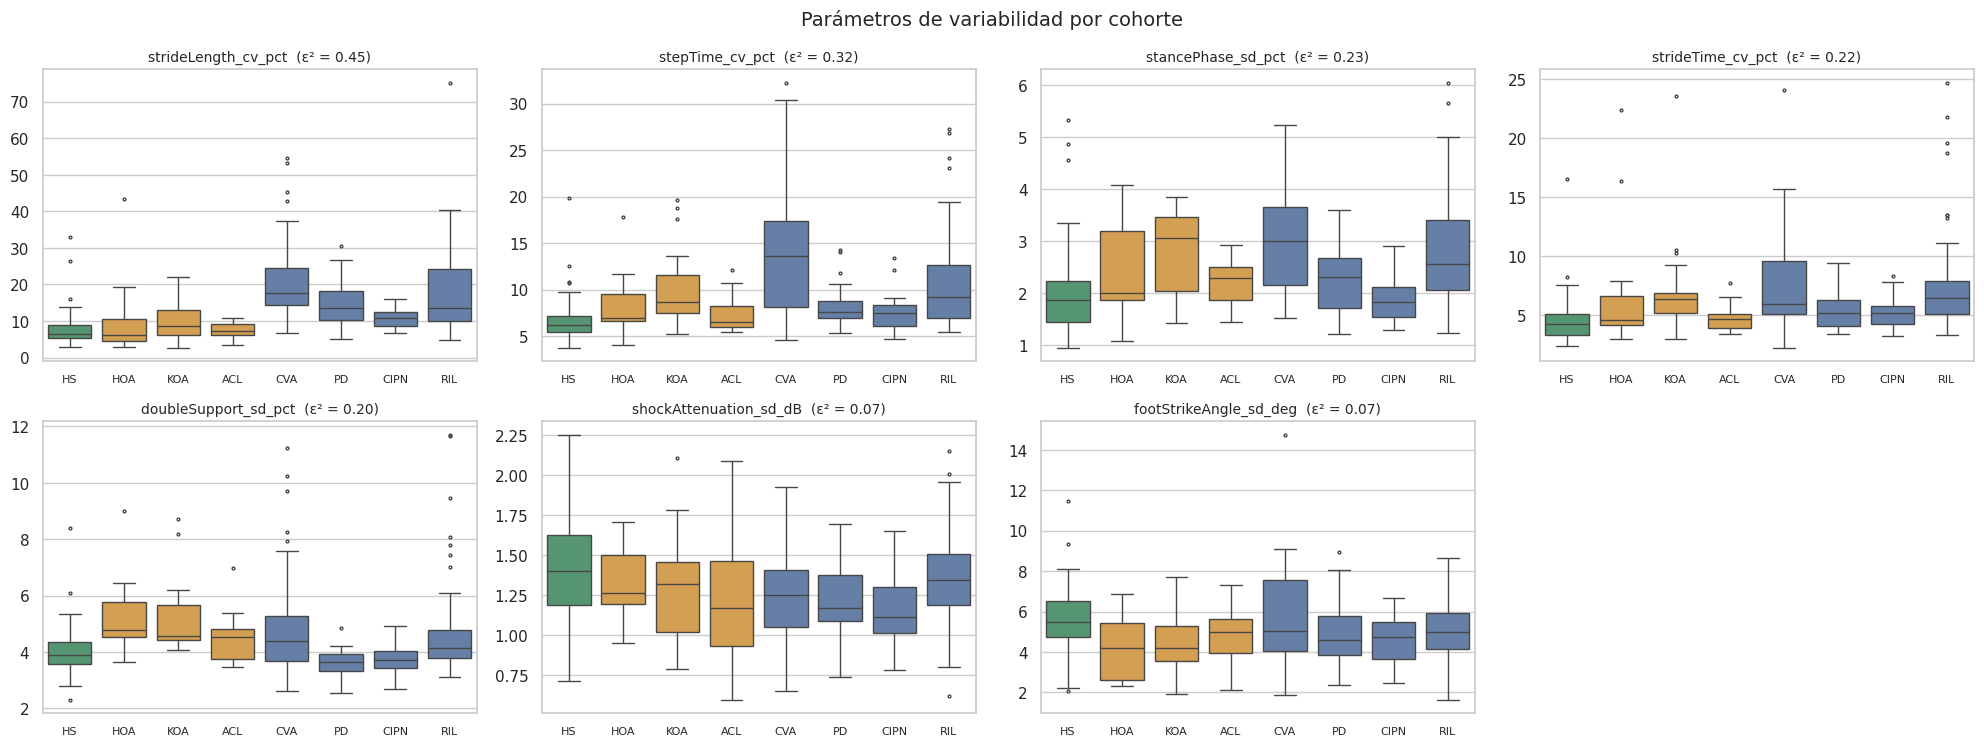

In [ ]:
# Mostrar todos los boxplots
def boxplots(parametros, titulo, nombre_fig, ncols=4):
    nfilas = int(np.ceil(len(parametros) / ncols))
    fig, axes = plt.subplots(nfilas, ncols, figsize=(5 * ncols, 3.8 * nfilas))
    for ax, col in zip(axes.ravel(), parametros):
        sns.boxplot(data=med_sujeto, x="pathologyKey", y=col, order=ORDEN, hue="pathologyKey",
                    palette=PALETA, legend=False, ax=ax, fliersize=2)
        ax.set_title(f"{col}  (ε² = {kw.loc[col, 'epsilon2']:.2f})", fontsize=10)
        ax.set_xlabel(""); ax.set_ylabel(""); ax.tick_params(axis="x", labelsize=8)
    for ax in axes.ravel()[len(parametros):]:   # oculta los huecos vacíos
        ax.axis("off")
    fig.suptitle(titulo, fontsize=14)
    plt.tight_layout(); guardar_fig(nombre_fig); plt.show()

# Ordenados por ε², de más a menos diferentes
medias_ord = [p for p in kw.index if p in MEDIAS_BIL]
variab_ord = [p for p in kw.index if p in VARIAB_BIL]

boxplots(medias_ord, "Parámetros medios por cohorte", "3_3_boxplots_medias_todos")
boxplots(variab_ord, "Parámetros de variabilidad por cohorte", "3_3_boxplots_variabilidad_todos")

### 3.4 Perfil de cada patología frente a la marcha sana

¿qué parámetros están alterados en cada patología?

Aquí se compara cada patología con los sanos, parámetro por parámetro. El resultado es la “firma” de cada patología, es decir, qué tiene alterado y si está aumentado o disminuido (la dirección). En esta parte de caracteriza la marcha de cada patología.

El delta de Cliff enfrenta a cada paciente con cada sano parámetro por parámetro. Se interpreta:
- δ = −1: el paciente tiene siempre un valor menor que el sano.
- δ = 0: empate; no hay diferencia.
- δ = +1: el paciente tiene siempre un valor mayor.

Se utiliza porque no se puede comparar las mesias, al ser parámetrso que se miden con unidades distintas, además así no se arrastran errores de valores extremos.

,sensor,pacientes,sanos de referencia
cohorte,,,
HOA,MTw Awinda XSens,15,53
KOA,MTw Awinda XSens,18,53
ACL,MTw Awinda XSens,11,53
CVA,TechnoConcept,49,20
PD,TechnoConcept,22,20
CIPN,TechnoConcept,18,20
RIL,TechnoConcept,44,20


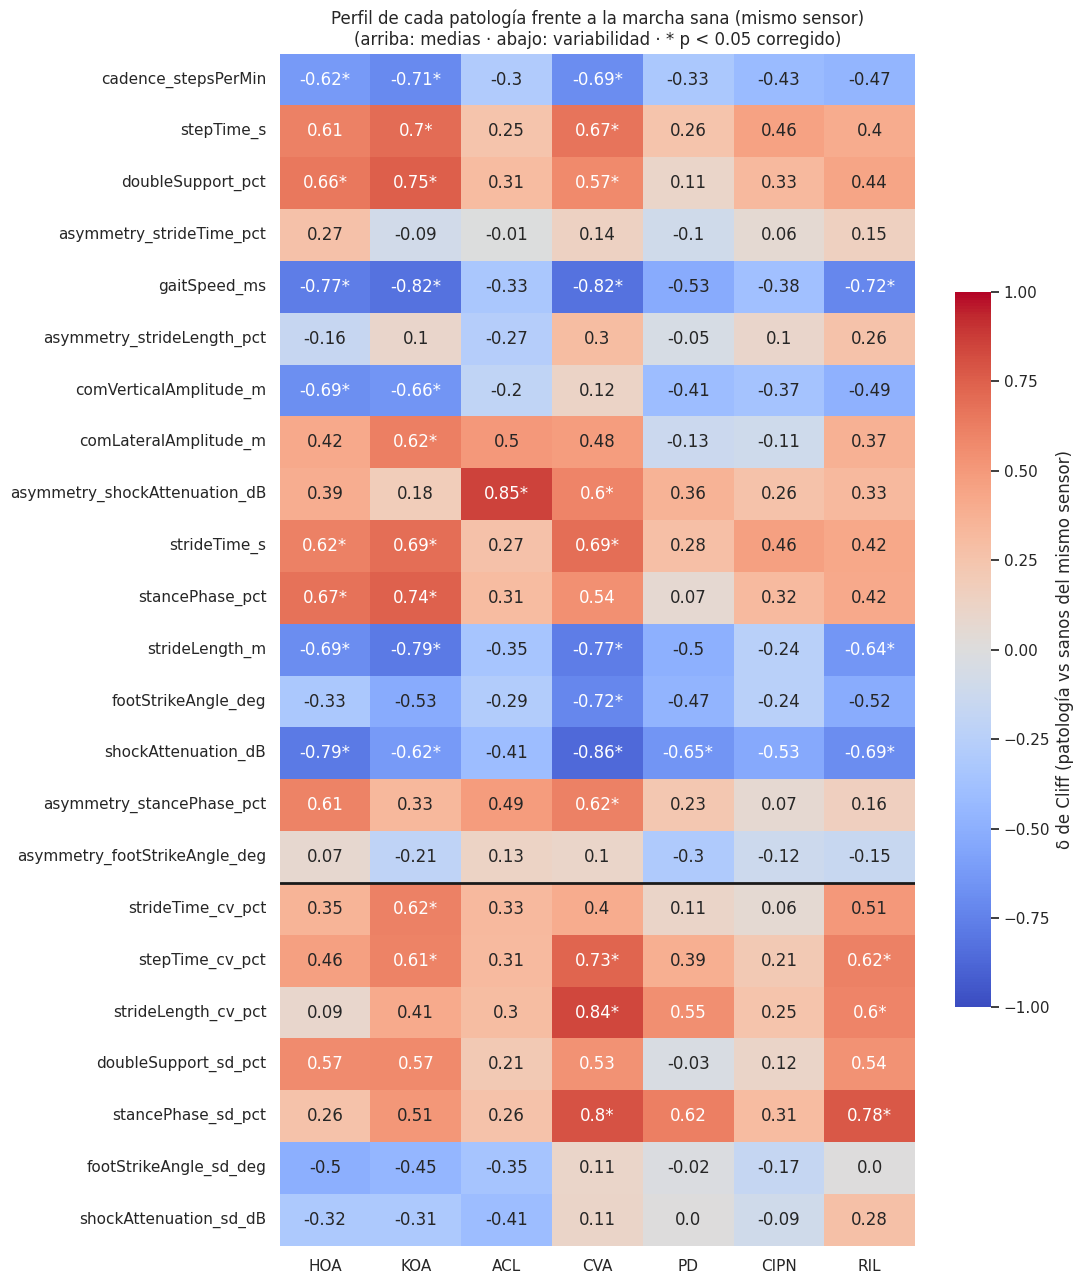

In [ ]:
PATOLOGIAS = [p for p in ORDEN if p != "HS"]
n_tests = len(PATOLOGIAS) * len(BIOMECH_BIL)          # 7 × 23 = 161 → Bonferroni

delta = pd.DataFrame(index=BIOMECH_BIL, columns=PATOLOGIAS, dtype=float)
pval = delta.copy()
info = []
for p in PATOLOGIAS:
    sens = med_sujeto.loc[med_sujeto["pathologyKey"] == p, "sensor"].mode()[0]
    pat = med_sujeto[(med_sujeto["pathologyKey"] == p) & (med_sujeto["sensor"] == sens)]
    hs  = med_sujeto[(med_sujeto["pathologyKey"] == "HS") & (med_sujeto["sensor"] == sens)]
    info.append({"cohorte": p, "sensor": sens, "pacientes": len(pat), "sanos de referencia": len(hs)})
    for c in BIOMECH_BIL:
        a, b = pat[c].dropna(), hs[c].dropna()
        delta.loc[c, p] = cliff_delta(a, b)
        pval.loc[c, p] = min(mannwhitneyu(a, b).pvalue * n_tests, 1)

display(pd.DataFrame(info).set_index("cohorte"))

anot = delta.round(2).astype(str) + np.where(pval < 0.05, "*", "")
plt.figure(figsize=(11, 13))
sns.heatmap(delta, annot=anot, fmt="", cmap="coolwarm", center=0, vmin=-1, vmax=1,
            cbar_kws={"label": "δ de Cliff (patología vs sanos del mismo sensor)", "shrink": .6})
plt.axhline(len(MEDIAS_BIL), color="k", lw=2)
plt.title("Perfil de cada patología frente a la marcha sana (mismo sensor)\n"
          "(arriba: medias · abajo: variabilidad · * p < 0.05 corregido)")
plt.tight_layout(); guardar_fig("3_4_perfil_vs_sanos"); plt.show()
guardar_tabla(delta.round(3), "3_4_delta_cliff")

Cada patología se comparó con los sujetos sanos registrados con su mismo sensor: las cohortes ortopédicas con 53 sanos registrados con XSens y las neurológicas con 20 sanos registrados con TechnoConcept. Se excluyeron de esta comparación los pacientes registrados con el sensor minoritario de su cohorte (2 en PD, 1 en CIPN y 7 en RIL; 5 % del total). El menor tamaño del grupo de referencia de las cohortes neurológicas reduce la potencia estadística de sus comparaciones.

**Interpretación.** Al comparar cada patología con los sanos registrados con su mismo sensor, se obtienen los siguientes perfiles:

- **HOA y KOA:** marcha más lenta (δ = −0,77 y −0,82), con zancadas más cortas, menor cadencia, mayor fase de apoyo y doble apoyo (δ ≈ 0,66–0,75), menor atenuación del impacto y menor oscilación vertical del centro de masas (δ ≈ −0,67). Es compatible con una estrategia de protección de la articulación dolorosa. KOA presenta además una mayor variabilidad temporal (tiempo de zancada y de paso, δ ≈ 0,61) y mayor oscilación lateral, mientras que en HOA la marcha es regular.
- **ACL:** la única alteración significativa es la asimetría de la atenuación del impacto (δ = 0,85), coherente con una lesión unilateral; el resto de parámetros es próximo a la normalidad.
- **CVA:** es la cohorte más alterada. Presenta una marcha lenta y de pasos cortos, un menor ángulo de contacto del pie (δ = −0,72), compatible con el pie caído, asimetría en la atenuación del impacto y en la fase de apoyo (δ ≈ 0,60), coherente con la afectación de un hemicuerpo, y una elevada variabilidad espacial y temporal (δ = 0,73–0,84).
- **PD:** solo la menor atenuación del impacto es significativa (δ = −0,65), aunque se observan diferencias grandes en la variabilidad de la fase de apoyo (0,62) y de la longitud de zancada (0,55) y en la velocidad (−0,53).
- **CIPN:** ninguna diferencia significativa; es la cohorte más próxima a la marcha sana. La mayor variabilidad de la longitud de zancada observada al compararla con todos los sanos se debía al sensor.
- **RIL:** marcha lenta y de pasos cortos (δ = −0,72 y −0,64), con menor atenuación del impacto y una elevada variabilidad tanto espacial como temporal (δ = 0,60–0,78).

En conjunto, la menor atenuación del impacto es la alteración más común a todas las patologías; las cohortes de artrosis se caracterizan por una marcha lenta con mayor apoyo, las patologías unilaterales (ACL, CVA) por la asimetría, y CVA y RIL por la irregularidad. Las cohortes neurológicas se comparan con un grupo de referencia menor (20 sanos), lo que reduce la potencia estadística; por ello, se consideran también los tamaños del efecto grandes (|δ| > 0,47) aunque no alcancen la significación tras la corrección.

In [ ]:
# Para cada patología, coge los 4 parámetros más alterados y muestra flecha si ha aumentado/disminuido respecto a sanos
resumen_perfil = {}
for p in PATOLOGIAS:
    top = delta[p].abs().sort_values(ascending=False).head(4).index
    resumen_perfil[p] = [f"{c} ({'↑' if delta.loc[c, p] > 0 else '↓'}{abs(delta.loc[c, p]):.2f})" for c in top]
resumen_perfil = pd.DataFrame(resumen_perfil, index=["1º", "2º", "3º", "4º"]).T
guardar_tabla(resumen_perfil, "3_4_parametros_mas_alterados")
resumen_perfil

,1º,2º,3º,4º
HOA,shockAttenuation_dB (↓0.79),gaitSpeed_ms (↓0.77),strideLength_m (↓0.69),comVerticalAmplitude_m (↓0.69)
KOA,gaitSpeed_ms (↓0.82),strideLength_m (↓0.79),doubleSupport_pct (↑0.75),stancePhase_pct (↑0.74)
ACL,asymmetry_shockAttenuation_dB (↑0.85),comLateralAmplitude_m (↑0.50),asymmetry_stancePhase_pct (↑0.49),shockAttenuation_dB (↓0.41)
CVA,shockAttenuation_dB (↓0.86),strideLength_cv_pct (↑0.84),gaitSpeed_ms (↓0.82),stancePhase_sd_pct (↑0.80)
PD,shockAttenuation_dB (↓0.65),stancePhase_sd_pct (↑0.62),strideLength_cv_pct (↑0.55),gaitSpeed_ms (↓0.53)
CIPN,shockAttenuation_dB (↓0.53),strideTime_s (↑0.46),stepTime_s (↑0.46),cadence_stepsPerMin (↓0.43)
RIL,stancePhase_sd_pct (↑0.78),gaitSpeed_ms (↓0.72),shockAttenuation_dB (↓0.69),strideLength_m (↓0.64)


Para evitar que un mismo hallazgo ocupe varias posiciones, la firma de cada patología se construyó excluyendo los parámetros redundantes identificados en la sección 3.5 (tiempo de zancada, tiempo de paso y fase de apoyo), representados por la cadencia y el doble apoyo.

In [ ]:
# Firma de cada patología: 4 parámetros más alterados, sin variables redundantes (sección 3.5)
REDUNDANTES = ["strideTime_s", "stepTime_s", "stancePhase_pct"]   # se usan cadencia y doble apoyo
param_firma = [c for c in BIOMECH_BIL if c not in REDUNDANTES]

resumen_perfil = {}
for p in PATOLOGIAS:
    top = delta.loc[param_firma, p].abs().sort_values(ascending=False).head(4).index
    resumen_perfil[p] = [f"{c} ({'↑' if delta.loc[c, p] > 0 else '↓'}{abs(delta.loc[c, p]):.2f}"
                         f"{'*' if pval.loc[c, p] < 0.05 else ''})" for c in top]
resumen_perfil = pd.DataFrame(resumen_perfil, index=["1º", "2º", "3º", "4º"]).T
guardar_tabla(resumen_perfil, "3_4_parametros_mas_alterados")
resumen_perfil

,1º,2º,3º,4º
HOA,shockAttenuation_dB (↓0.79*),gaitSpeed_ms (↓0.77*),strideLength_m (↓0.69*),comVerticalAmplitude_m (↓0.69*)
KOA,gaitSpeed_ms (↓0.82*),strideLength_m (↓0.79*),doubleSupport_pct (↑0.75*),cadence_stepsPerMin (↓0.71*)
ACL,asymmetry_shockAttenuation_dB (↑0.85*),comLateralAmplitude_m (↑0.50),asymmetry_stancePhase_pct (↑0.49),shockAttenuation_dB (↓0.41)
CVA,shockAttenuation_dB (↓0.86*),strideLength_cv_pct (↑0.84*),gaitSpeed_ms (↓0.82*),stancePhase_sd_pct (↑0.80*)
PD,shockAttenuation_dB (↓0.65*),stancePhase_sd_pct (↑0.62),strideLength_cv_pct (↑0.55),gaitSpeed_ms (↓0.53)
CIPN,shockAttenuation_dB (↓0.53),cadence_stepsPerMin (↓0.43),gaitSpeed_ms (↓0.38),comVerticalAmplitude_m (↓0.37)
RIL,stancePhase_sd_pct (↑0.78*),gaitSpeed_ms (↓0.72*),shockAttenuation_dB (↓0.69*),strideLength_m (↓0.64*)


**Firma de cada patología.** Para evitar redundancias, la tabla excluye el tiempo de zancada, el tiempo de paso y la fase de apoyo (representados por la cadencia y el doble apoyo, sección 3.5). El asterisco indica significación tras la corrección de Bonferroni.

- **HOA y KOA:** firmas sólidas (las cuatro alteraciones significativas) centradas en la cantidad de marcha: menor velocidad y longitud de zancada, junto con menor atenuación del impacto y oscilación vertical en HOA, y mayor doble apoyo y menor cadencia en KOA.
- **ACL:** su rasgo principal es la asimetría de la atenuación del impacto (δ = 0,85); el resto de alteraciones son moderadas y no significativas.
- **CVA:** la firma más marcada (δ = 0,80–0,86), que combina menor atenuación del impacto, elevada irregularidad (variabilidad de la longitud de zancada y de la fase de apoyo) y menor velocidad.
- **RIL:** firma sólida que combina irregularidad (variabilidad de la fase de apoyo), menor velocidad, menor atenuación y pasos más cortos.
- **PD:** solo la menor atenuación del impacto es significativa; la irregularidad y la menor velocidad son moderadas.
- **CIPN:** ninguna alteración significativa y todas de magnitud moderada (δ = 0,37–0,53); es la cohorte más próxima a la marcha sana.

La menor atenuación del impacto forma parte de la firma de todas las patologías. Las cohortes de artrosis alteran principalmente la cantidad de marcha (velocidad, longitud del paso y apoyo), mientras que CVA, RIL y, en menor medida, PD alteran su regularidad. CIPN, ACL y PD, con firmas más débiles, serán previsiblemente las más difíciles de identificar en los modelos de clasificación.

### 3.5 Correlación entre parámetros

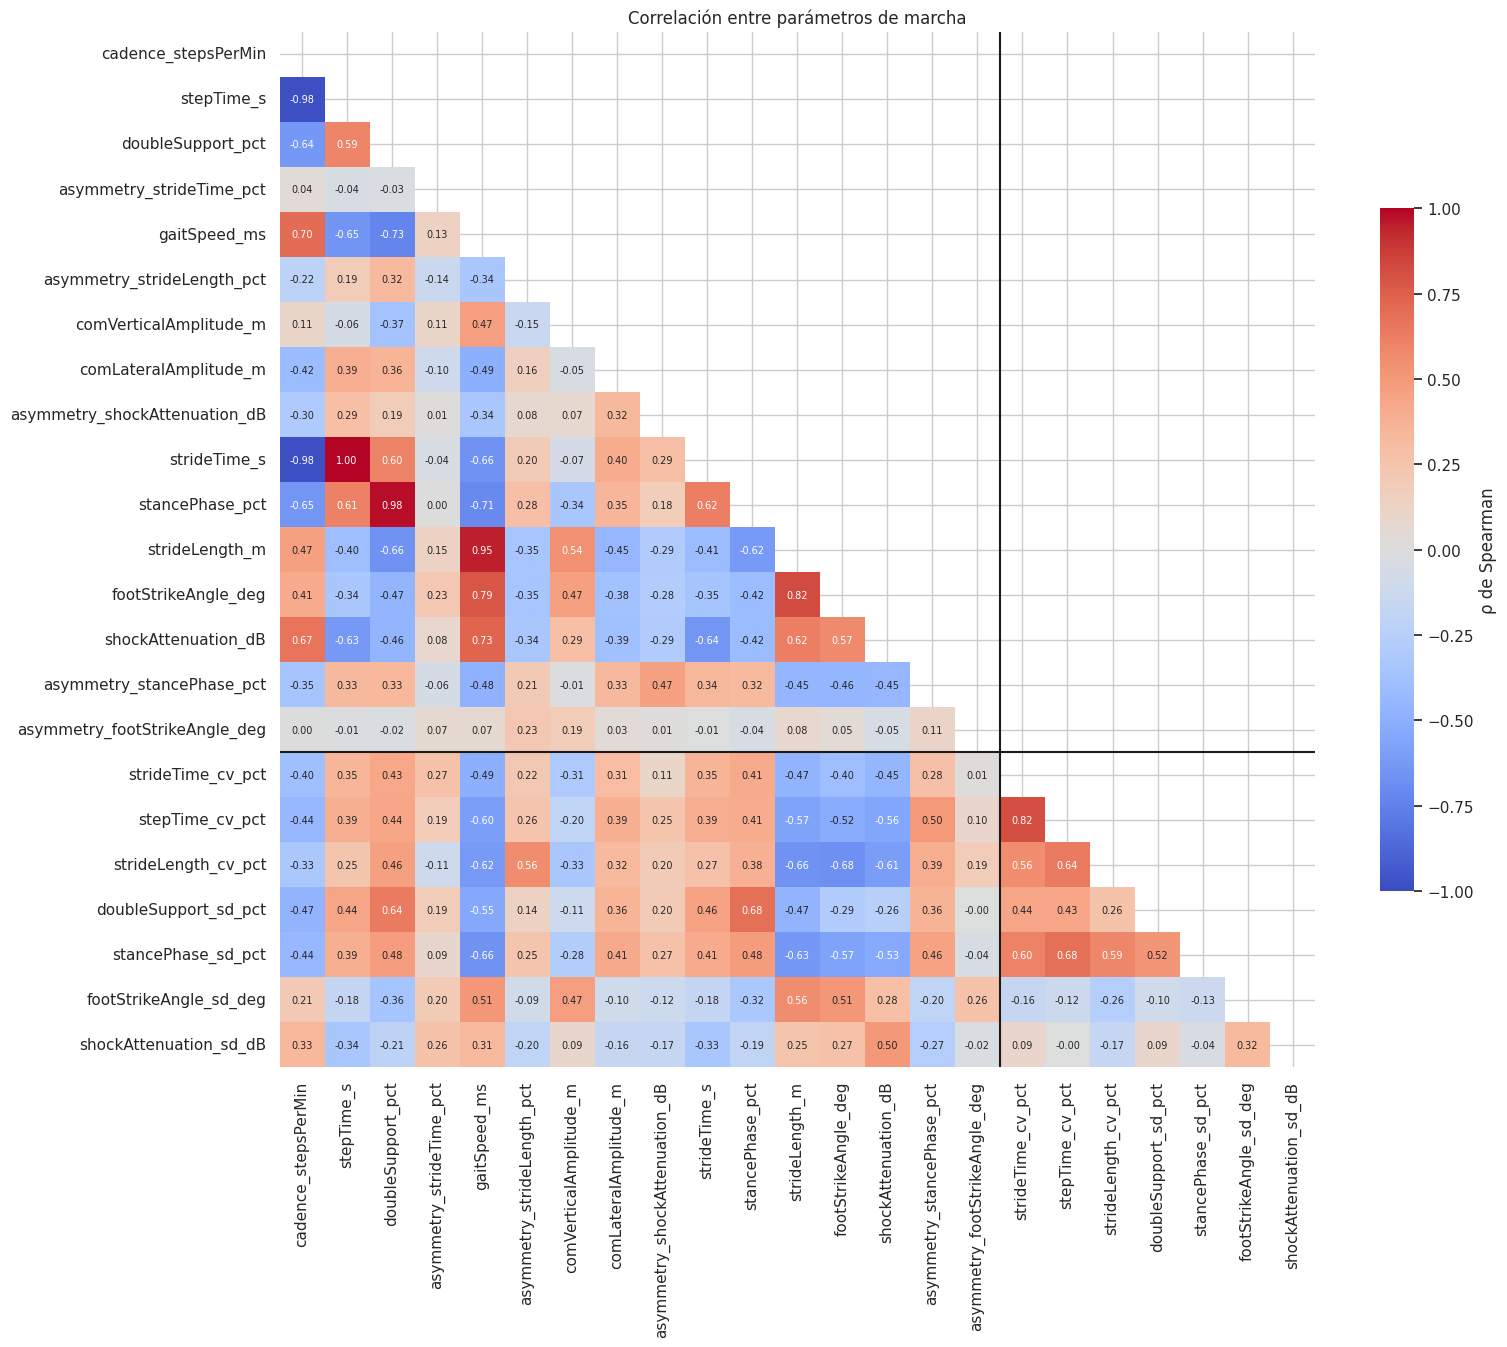

Pares muy correlacionados (|ρ| > 0.9):


,,ρ
strideTime_s,stepTime_s,1.00
stepTime_s,cadence_stepsPerMin,-0.98
strideTime_s,cadence_stepsPerMin,-0.98
stancePhase_pct,doubleSupport_pct,0.98
strideLength_m,gaitSpeed_ms,0.95


Correlación media entre variabilidad y medias: |ρ| = 0.34
Mayor correlación de cada variable de variabilidad con alguna media:


,media más relacionada,|ρ|
strideLength_cv_pct,footStrikeAngle_deg,0.68
doubleSupport_sd_pct,stancePhase_pct,0.68
stancePhase_sd_pct,gaitSpeed_ms,0.66
stepTime_cv_pct,gaitSpeed_ms,0.60
footStrikeAngle_sd_deg,strideLength_m,0.56
shockAttenuation_sd_dB,shockAttenuation_dB,0.50
strideTime_cv_pct,gaitSpeed_ms,0.49


In [ ]:
corr = med_sujeto[BIOMECH_BIL].corr(method="spearman")
mascara = np.triu(np.ones_like(corr, dtype=bool))

plt.figure(figsize=(16, 14))
sns.heatmap(corr, mask=mascara, cmap="coolwarm", center=0, vmin=-1, vmax=1, square=True,
            annot=True, fmt=".2f", annot_kws={"size": 7},
            cbar_kws={"shrink": .6, "label": "ρ de Spearman"})
plt.axhline(len(MEDIAS_BIL), color="k", lw=1.5); plt.axvline(len(MEDIAS_BIL), color="k", lw=1.5)
plt.title("Correlación entre parámetros de marcha")
plt.tight_layout(); guardar_fig("3_5_correlacion"); plt.show()

# 1) Pares casi redundantes
pares = corr.where(~mascara).stack()
print("Pares muy correlacionados (|ρ| > 0.9):")
display(pares[pares.abs() > 0.9].round(2).sort_values(key=abs, ascending=False).to_frame("ρ"))

# 2) ¿La variabilidad mide algo distinto de las medias?
bloque = corr.loc[VARIAB_BIL, MEDIAS_BIL].abs()
print(f"Correlación media entre variabilidad y medias: |ρ| = {bloque.values.mean():.2f}")
print("Mayor correlación de cada variable de variabilidad con alguna media:")
display(pd.DataFrame({"media más relacionada": bloque.idxmax(axis=1),
                      "|ρ|": bloque.max(axis=1).round(2)}).sort_values("|ρ|", ascending=False))

**Interpretación.** El análisis de correlación (Spearman, un valor por sujeto) identifica tres grupos de parámetros prácticamente redundantes (|ρ| > 0,9):
- **Ritmo:** tiempo de zancada, tiempo de paso y cadencia (|ρ| = 0,98–1,00), expresiones distintas de la misma magnitud.
- **Apoyo:** fase de apoyo y doble apoyo (ρ = 0,98), ya que un mayor tiempo de apoyo de cada pie implica más tiempo con ambos pies en el suelo.
- **Avance:** longitud de zancada y velocidad (ρ = 0,95), dado que la velocidad es el producto de la longitud de zancada y la cadencia.

Existen además relaciones fuertes no redundantes, como la del ángulo de contacto del pie con la longitud de zancada (ρ = 0,82) y la velocidad (0,79), o la de la atenuación del impacto con la velocidad (0,73). Esta última indica que la menor atenuación del impacto observada en todas las patologías (sección 3.4) puede reflejar en parte su menor velocidad de marcha.

Los parámetros de variabilidad muestran una correlación baja-moderada con los parámetros medios (|ρ| medio = 0,34; máximo = 0,68), relacionándose principalmente con la velocidad. Por tanto, la variabilidad aporta información en gran medida independiente de los valores medios, lo que justifica su inclusión en el conjunto de variables V2.

**Decisión.** En la selección de variables para los modelos (sección 4) se mantendrá un único representante de los grupos de ritmo (cadencia) y de apoyo (doble apoyo), eliminando el tiempo de zancada y la fase de apoyo. La velocidad y la longitud de zancada se conservan, ya que se normalizan de forma distinta y la velocidad incorpora también información del ritmo. Además, se excluirá la variabilidad del doble apoyo por su dependencia del sensor (sección 3.2).

## 4. Preparación de variables

RESUMEN VARIABLES A EXCLUIR
- `group`, `pathologyKey`: etiquetas a predecir.
- `evaluationScoreValue`, `visualGaitAssessment`, `clinicalDeficitSide`, `TUG_s`: información clínica ajena a los sensores; su presencia o ausencia depende del protocolo de cada cohorte (sección 2.2), lo que permitiría identificar la cohorte sin analizar la marcha.
- Identificadores (`subject`, `session`...).
- `sensor`, `protocolDistance_m`, `nCycles_*`: condiciones de adquisición confundidas con la cohorte (sección 3.1).
- **Edad y demás datos demográficos:** la edad está confundida con la cohorte (sección 3.1). Incluirla haría que el modelo detectase "persona mayor" en lugar de "marcha patológica" (se comprueba en la sección 5.6). La altura solo se usa para normalizar.
- **Parámetros redundantes:** tiempo de zancada, tiempo de paso y fase de apoyo (sección 3.5).
- **Variabilidad del doble apoyo:** dependiente del sensor (sección 3.2).
- **Diferencias de variabilidad entre piernas:** estimadas con la mitad de los ciclos y, por tanto, poco fiables.



### 4.1 Ingeniería de variables
A partir de los parámetros de cada visita se construyen las variables de los modelos, aplicando las decisiones del análisis descriptivo:
- **Normalización por altura:** longitud de zancada y amplitudes del centro de masas divididas por la altura, y velocidad adimensional (número de Froude, v / √(g·0,53·altura)), para eliminar el efecto de la estatura.
- **Variables independientes del lado:** media izquierda-derecha y asimetría, como en la sección 3.
- **Eliminación de redundancias (sección 3.5):** se mantiene la cadencia (no el tiempo de zancada) y el doble apoyo (no la fase de apoyo).
- **Eliminación de la variabilidad del doble apoyo**, por su dependencia del sensor (sección 3.2).

Se definen dos conjuntos para medir el aporte de la variabilidad:
- **V1 · Medias** (13 variables)
- **V2 · Medias + variabilidad** (19 variables)

In [ ]:
def ingenieria_variables(data, variabilidad=True):
    f = pd.DataFrame(index=data.index)
    h = data["height_m"].fillna(df["height_m"].median())

    # --- Medias (13) ---
    # Ritmo y apoyo (un representante de cada grupo redundante, sección 3.5)
    f["cadencia"]          = data["cadence_stepsPerMin"]
    f["doble_apoyo_pct"]   = data["doubleSupport_pct"]
    # Avance, normalizado por la altura
    f["long_zancada_h"]    = data[["strideLength_L_m", "strideLength_R_m"]].mean(axis=1) / h
    f["velocidad_froude"]  = data["gaitSpeed_ms"] / np.sqrt(9.81 * 0.53 * h)
    # Contacto del pie, centro de masas y amortiguación
    f["ang_contacto"]      = data[["footStrikeAngle_L_deg", "footStrikeAngle_R_deg"]].mean(axis=1)
    f["com_vertical_h"]    = data["comVerticalAmplitude_m"] / h
    f["com_lateral_h"]     = data["comLateralAmplitude_m"] / h
    f["atenuacion"]        = data[["shockAttenuation_L_dB", "shockAttenuation_R_dB"]].mean(axis=1)
    # Asimetrías (independientes del lado afectado)
    f["asim_t_zancada"]    = data["asymmetry_strideTime_pct"]
    f["asim_long_zancada"] = data["asymmetry_strideLength_pct"]
    f["asim_apoyo"]        = (data["stancePhase_L_pct"] - data["stancePhase_R_pct"]).abs()
    f["asim_ang_contacto"] = (data["footStrikeAngle_L_deg"] - data["footStrikeAngle_R_deg"]).abs()
    f["asim_atenuacion"]   = data["asymmetry_shockAttenuation_dB"]

    # --- Variabilidad (6) ---
    if variabilidad:
        f["cv_t_zancada"]    = data["strideTime_cv_pct"]
        f["cv_t_paso"]       = data["stepTime_cv_pct"]
        f["cv_long_zancada"] = data["strideLength_cv_pct"]
        f["sd_apoyo"]        = data[["stancePhase_L_sd_pct", "stancePhase_R_sd_pct"]].mean(axis=1)
        f["sd_ang_contacto"] = data[["footStrikeAngle_L_sd_deg", "footStrikeAngle_R_sd_deg"]].mean(axis=1)
        f["sd_atenuacion"]   = data[["shockAttenuation_L_sd_dB", "shockAttenuation_R_sd_dB"]].mean(axis=1)
    return f

X_V1 = ingenieria_variables(V, variabilidad=False)
X_V2 = ingenieria_variables(V, variabilidad=True)
FEAT_VARIAB = [c for c in X_V2.columns if c not in X_V1.columns]
groups = V["subject"]
print(f"V1: {X_V1.shape[1]} variables | V2: {X_V2.shape[1]} variables | {len(V)} visitas | {groups.nunique()} sujetos")

V1: 13 variables | V2: 19 variables | 335 visitas | 260 sujetos


En el apartado 3 se usa una fila por sujeto y solo su primera visita, porque eran tests estadísticos que necesitan datos independientes. Aquí, para los modelos, se usan todas las visitas (335), porque cada visita es un caso que el modelo tiene que clasificar, y la independencia se garantiza de otra forma, manteniendo juntas las visitas de un mismo sujeto al separar entrenamiento y test (sección 5).

### 4.2 Visualización del espacio de variables (PCA)
El **análisis de componentes principales (PCA)** resume las 19 variables de V2 en unas pocas componentes, combinaciones de las variables originales que recogen la mayor parte de la variabilidad de los datos. Permite representar todas las visitas en 2 o 3 dimensiones y ver si las cohortes forman grupos separados.El PCA busca las direcciones en las que los datos varían más, sin saber a qué cohorte pertenece cada punto

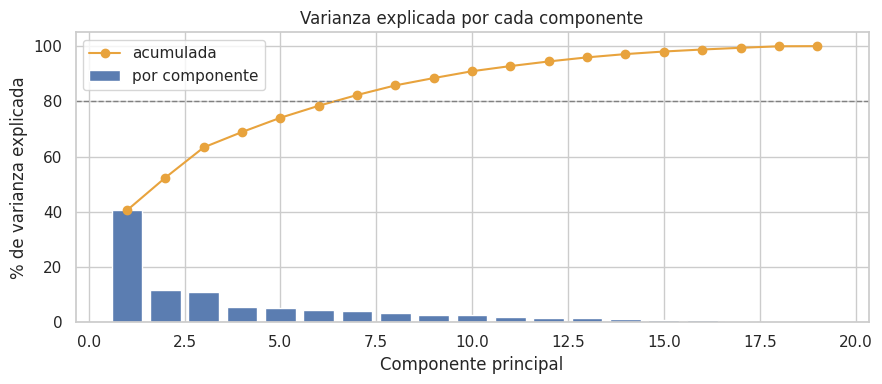

PC1: 40.5 % | PC2: 11.8 % | PC3: 11.0 %
PC1+PC2: 52.4 % | PC1+PC2+PC3: 63.3 %
Componentes necesarias para el 80 %: 7


In [ ]:
from sklearn.decomposition import PCA

X_pca = StandardScaler().fit_transform(SimpleImputer(strategy="median").fit_transform(X_V2))
pca = PCA(random_state=RANDOM_STATE).fit(X_pca)
Z_pca = pd.DataFrame(pca.transform(X_pca)[:, :3], columns=["PC1", "PC2", "PC3"], index=V.index)
var_exp = pca.explained_variance_ratio_

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(range(1, len(var_exp) + 1), var_exp * 100, color="#5B7DB1", label="por componente")
ax.plot(range(1, len(var_exp) + 1), np.cumsum(var_exp) * 100, "o-", color="#E8A33D", label="acumulada")
ax.axhline(80, ls="--", color="grey", lw=1)
ax.set_xlabel("Componente principal"); ax.set_ylabel("% de varianza explicada")
ax.set_title("Varianza explicada por cada componente"); ax.legend()
plt.tight_layout(); guardar_fig("4_3_pca_varianza"); plt.show()

print(f"PC1: {var_exp[0]*100:.1f} % | PC2: {var_exp[1]*100:.1f} % | PC3: {var_exp[2]*100:.1f} %")
print(f"PC1+PC2: {var_exp[:2].sum()*100:.1f} % | PC1+PC2+PC3: {var_exp[:3].sum()*100:.1f} %")
print(f"Componentes necesarias para el 80 %: {np.argmax(np.cumsum(var_exp) >= .8) + 1}")

**Interpretación.** La primera componente principal (PC1) recoge el 40,5 % de la varianza de las 19 variables, lo que indica que gran parte de los parámetros varían de forma conjunta a lo largo de un eje dominante. La segunda (11,8 %) y la tercera (11,0 %) aportan una cantidad de información similar entre sí, por lo que la representación en tres dimensiones (63,3 % de la varianza) resulta más completa que la bidimensional (52,4 %). A partir de la cuarta componente, el aporte de cada una es inferior al 6 %. Son necesarias 7 componentes para explicar el 80 % de la varianza, por lo que las representaciones gráficas muestran solo una parte de la información disponible, mientras que los modelos de clasificación utilizarán todas las variables.

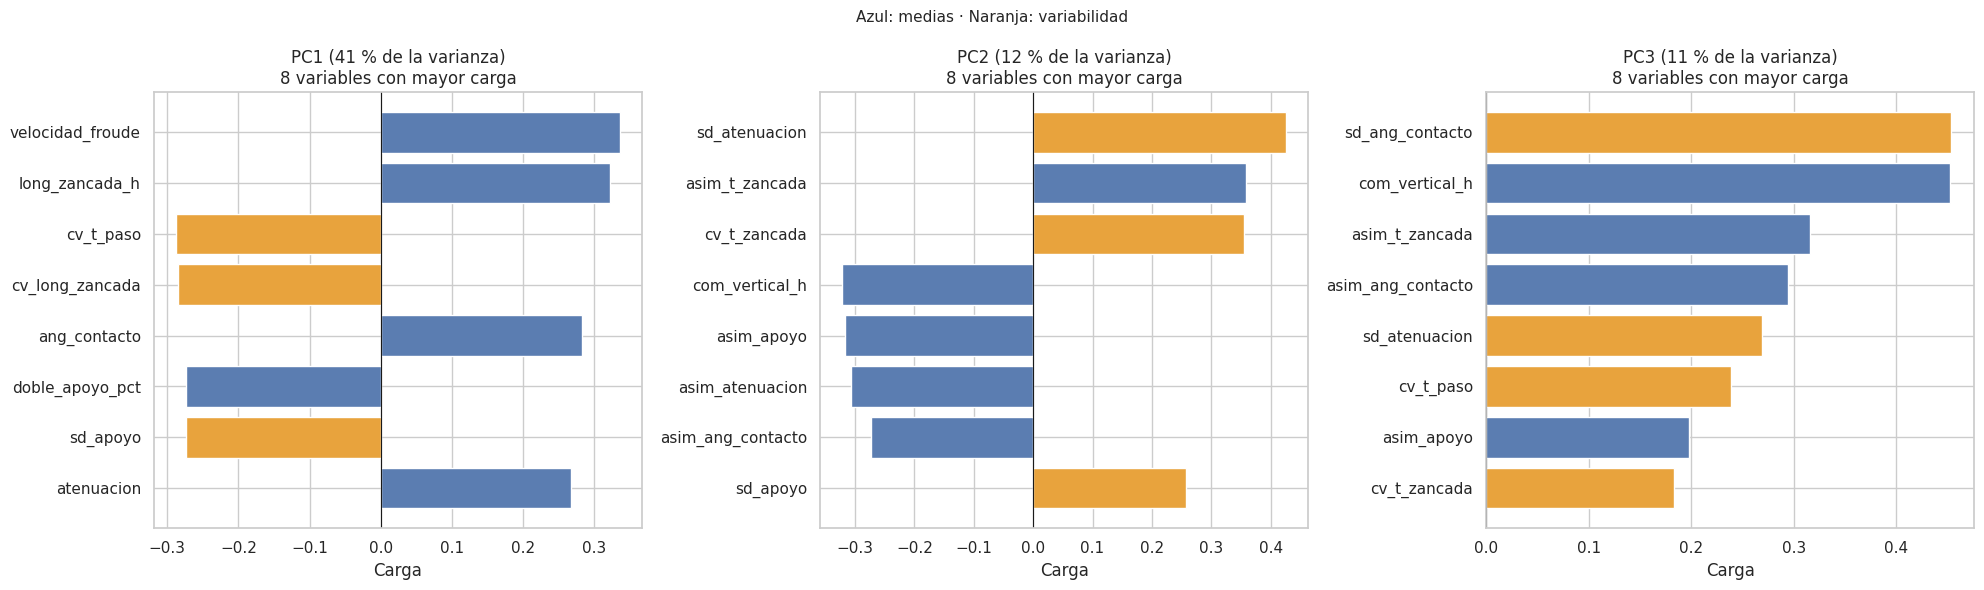

In [ ]:
cargas = pd.DataFrame(pca.components_[:3].T, index=X_V2.columns, columns=["PC1", "PC2", "PC3"])
guardar_tabla(cargas.round(3), "4_3_pca_cargas")

fig, axes = plt.subplots(1, 3, figsize=(20, 6))
for ax, pc in zip(axes, ["PC1", "PC2", "PC3"]):
    top = cargas[pc].reindex(cargas[pc].abs().sort_values().index).tail(8)
    colores = ["#E8A33D" if c in FEAT_VARIAB else "#5B7DB1" for c in top.index]
    ax.barh(top.index, top.values, color=colores)
    ax.axvline(0, color="k", lw=.8)
    ax.set_title(f"{pc} ({var_exp[int(pc[-1]) - 1]*100:.0f} % de la varianza)\n8 variables con mayor carga")
    ax.set_xlabel("Carga")
plt.suptitle("Azul: medias · Naranja: variabilidad", fontsize=11)
plt.tight_layout(); guardar_fig("4_3_pca_cargas"); plt.show()

**Interpretación de las cargas.**
- **PC1 (41 %), calidad global de la marcha:** cargas positivas de la velocidad, la longitud de zancada, el ángulo de contacto del pie y la atenuación del impacto, y negativas del doble apoyo y de la variabilidad del tiempo de paso, la longitud de zancada y la fase de apoyo. Valores altos corresponden a una marcha rápida, de pasos largos, regular y con buena amortiguación; valores bajos, a una marcha lenta, cautelosa e irregular. Este eje reúne las alteraciones comunes a la mayoría de patologías (sección 3.4) y representa el grado global de afectación.
- **PC2 (12 %), irregularidad temporal frente a asimetría:** contrapone la variabilidad del ritmo y de la amortiguación (cargas positivas) a la asimetría entre piernas en la fase de apoyo, la atenuación y el ángulo del pie, junto con la oscilación vertical (cargas negativas). Distingue, por tanto, entre una marcha irregular y una marcha asimétrica.
- **PC3 (11 %), inestabilidad del contacto del pie:** todas las cargas principales son positivas, destacando la variabilidad del ángulo de contacto y la oscilación vertical del centro de masas, junto con varias asimetrías y la variabilidad del ritmo.

Las variables de variabilidad (en naranja) contribuyen de forma importante a las tres componentes, lo que confirma que aportan información relevante para describir la marcha.

In [ ]:
import plotly.express as px
import plotly.graph_objects as go

datos_3d = Z_pca.assign(cohorte=V["pathologyKey"].values, grupo=V["group"].values,
                        sensor=V["sensor"].values, sujeto=V["subject"].values)
ejes = {f"PC{i}": f"PC{i} ({var_exp[i-1]*100:.0f} %)" for i in (1, 2, 3)}

# Coloreado por cohorte
fig = px.scatter_3d(datos_3d, x="PC1", y="PC2", z="PC3", color="cohorte",
                    category_orders={"cohorte": ORDEN}, color_discrete_map=PALETA,
                    symbol="grupo", hover_data=["sujeto", "sensor"], opacity=0.7, labels=ejes,
                    title="Visitas en el espacio PC1–PC2–PC3, por cohorte (gira con el ratón)")
centros3 = datos_3d.groupby("cohorte")[["PC1", "PC2", "PC3"]].median().loc[ORDEN]
fig.add_trace(go.Scatter3d(x=centros3["PC1"], y=centros3["PC2"], z=centros3["PC3"], mode="markers+text",
                           text=centros3.index, textposition="top center",
                           marker=dict(size=9, color=[PALETA[p] for p in centros3.index],
                                       line=dict(color="black", width=2)),
                           name="mediana de cada cohorte"))
fig.update_traces(marker=dict(size=4), selector=dict(type="scatter3d", mode="markers"))
fig.update_layout(height=700, legend=dict(itemsizing="constant"))
fig.show()

**Interpretación.** En el espacio de las tres primeras componentes, las cohortes no forman grupos separados, sino que se solapan ampliamente. Sin embargo, sus medianas se ordenan a lo largo de PC1 (calidad global de la marcha) según el grado de afectación: HS, CIPN, ACL, PD, HOA, KOA, RIL y CVA, en el mismo orden que sugieren los perfiles de la sección 3.4. La tercera componente aporta una separación parcial entre cohortes de afectación similar: las cohortes de artrosis se sitúan en valores bajos de PC3 y CVA y RIL en valores altos, lo que indica una mayor inestabilidad del contacto del pie en las patologías neurológicas.

Por tanto, las patologías se distribuyen a lo largo de un continuo de deterioro de la marcha más que en grupos diferenciados. Esto anticipa que será relativamente sencillo distinguir la marcha patológica de la sana, pero más difícil identificar la patología concreta, especialmente entre las cohortes próximas a la normalidad (ACL, CIPN y PD).

In [ ]:
# coeficiente silhouette (indica si los grupos están separados o mezclados)
from sklearn.metrics import silhouette_score
sil = pd.DataFrame({
    "19 variables": {"8 cohortes": silhouette_score(X_pca, V["pathologyKey"]),
                     "sano / orto / neuro": silhouette_score(X_pca, V["group"]),
                     "sensor": silhouette_score(X_pca, V["sensor"])},
    "3 primeras componentes": {"8 cohortes": silhouette_score(Z_pca, V["pathologyKey"]),
                               "sano / orto / neuro": silhouette_score(Z_pca, V["group"]),
                               "sensor": silhouette_score(Z_pca, V["sensor"])},
}).round(3)
sil

,19 variables,3 primeras componentes
8 cohortes,-0.083,-0.123
sano / orto / neuro,-0.021,-0.044
sensor,0.030,0.022


**Interpretación.** El coeficiente silhouette es prácticamente nulo o negativo para las 8 cohortes (−0,08 con las 19 variables; −0,12 con las tres primeras componentes) y para la agrupación en sano, ortopédico y neurológico (−0,02 y −0,04), lo que confirma que las cohortes no forman grupos compactos y separados, sino que se solapan a lo largo de un continuo de alteración de la marcha. El silhouette según el sensor es igualmente próximo a cero (0,03 y 0,02), lo que indica que los registros no se agrupan por sistema de medida.

Un silhouette bajo no implica que las cohortes no puedan distinguirse: este índice evalúa la existencia de grupos compactos y bien separados, mientras que un clasificador solo necesita encontrar fronteras de decisión, aunque los grupos sean contiguos. La capacidad real de discriminación se evalúa en la sección 5.

## 5. Clasificación con validación cruzada agrupada por sujeto

### 5.1 Esquema de validación, tareas y algoritmos
**Validación.** `StratifiedGroupKFold` (5 folds): todas las visitas de un sujeto quedan en el mismo fold, de modo que el modelo nunca se evalúa con personas que ha visto al entrenar. Se repite **3 veces** con particiones distintas y se promedia, para que los resultados no dependan de una partición concreta. La imputación y la estandarización se ajustan solo con los datos de entrenamiento de cada fold (pipeline), para evitar fuga de información.

**Métrica principal: *balanced accuracy*.** Es la **media del porcentaje de aciertos de cada clase**: para cada cohorte se calcula qué % de sus casos se clasifica bien (sensibilidad) y se promedian. Un 0,40 en 8 cohortes significa que, de media, se identifica correctamente el 40 % de los casos de cada patología.

¿Por qué no la *accuracy* normal? Porque con clases desbalanceadas engaña. En sano frente a patológico hay 256 visitas de pacientes y 79 de sanos: un modelo que dijera siempre "patológico" tendría una accuracy de 0,76 sin aprender nada, pero su balanced accuracy sería 0,50 (100 % de aciertos en pacientes y 0 % en sanos). El **nivel de azar** es 1 / nº de clases: 0,50 con 2 clases, 0,125 con 8. Los resultados deben interpretarse siempre frente a ese nivel.

**Tareas**, de menor a mayor dificultad:

| Tarea | Clases | Pregunta clínica |
|---|---|---|
| A | Sano / patológico | ¿Es patológica esta marcha? |
| B | Sano / ortopédico / neurológico | ¿Qué tipo de patología? |
| C | Ortopédico / neurológico (solo pacientes) | ¿Origen articular o neurológico? |
| D | 7 clases (HOA + KOA = artrosis) | ¿Qué patología concreta? |
| E | 8 cohortes | ¿Qué patología concreta? |

En la tarea D se fusionan HOA y KOA porque ambas son artrosis de miembro inferior con un patrón de marcha muy similar: menor velocidad y longitud de zancada y mayor tiempo de apoyo (sección 3.4).

**Variables.** Se comparan los conjuntos V1 (13 medias) y V2 (19 variables, medias y variabilidad) definidos en la sección 4.

**Factores de confusión.** La edad y el sensor están asociados a la cohorte (sección 3.1). En particular, las cohortes ortopédicas se registraron con XSens y las neurológicas mayoritariamente con TechnoConcept, por lo que las tareas que distinguen ambos grupos (especialmente la C) podrían verse influidas por el sistema de medida. Su efecto se evalúa en la sección 5.6 comparando el rendimiento de la marcha con el de modelos que solo conocen la edad o el sensor, y repitiendo la clasificación dentro de cada sensor.

In [ ]:
# Para cada tarea se define qué visitas entran y qué etiqueta tiene que adivinar el modelo.
es_paciente = V["pathologyKey"] != "HS"
TAREAS = {
    "A · Sano vs patológico":  (V.index, V["group"].map(lambda g: "sano" if g == "healthy" else "patológico")),
    "B · Sano/orto/neuro":     (V.index, V["group"]),
    "C · Orto vs neuro":       (V.index[es_paciente], V.loc[es_paciente, "group"]),
    "D · 7 clases (artrosis)": (V.index, V["pathologyKey"].replace({"HOA": "OA", "KOA": "OA"})),
    "E · 8 cohortes":          (V.index, V["pathologyKey"]),
}
for t, (idx, y) in TAREAS.items():
    print(f"{t}: {y.nunique()} clases, {len(idx)} visitas → {y.value_counts().to_dict()}")

A · Sano vs patológico: 2 clases, 335 visitas → {'patológico': 256, 'sano': 79}
B · Sano/orto/neuro: 3 clases, 335 visitas → {'neuro': 192, 'healthy': 79, 'ortho': 64}
C · Orto vs neuro: 2 clases, 256 visitas → {'neuro': 192, 'ortho': 64}
D · 7 clases (artrosis): 7 clases, 335 visitas → {'RIL': 83, 'HS': 79, 'CVA': 57, 'OA': 48, 'PD': 32, 'CIPN': 20, 'ACL': 16}
E · 8 cohortes: 8 clases, 335 visitas → {'RIL': 83, 'HS': 79, 'CVA': 57, 'PD': 32, 'HOA': 24, 'KOA': 24, 'CIPN': 20, 'ACL': 16}


Se puede ver que las clases están desbalanceadas, por lo que evidencia la necesidad de usar la balanced accuracy en los modelos para que no predigan siempre la clase mayoritaria.

**Interpretación.** Todas las tareas presentan desbalance de clases, desde una proporción 3:1 en las tareas binarias y de grupo (A, B, C) hasta 5:1 en las de patología concreta (D, E), lo que justifica el uso de la *balanced accuracy* y de pesos de clase balanceados. Las cohortes ACL (16 visitas de 11 sujetos) y CIPN (20 visitas de 19 sujetos) son las más pequeñas: con 5 folds agrupados por sujeto, cada fold de test contiene solo 2–4 sujetos de estas cohortes, por lo que su rendimiento individual será menos estable. La fusión de HOA y KOA en la tarea D da lugar a una clase de 48 visitas, lo que facilita el aprendizaje de un patrón de marcha que ambas cohortes comparten.

In [ ]:
# Define los modelos a usar
def crear_modelos():
    imp = ("imputer", SimpleImputer(strategy="median"))   # rellena huecos con la mediana
    sc  = ("sc", StandardScaler())                         # pone todas las variables en la misma escala
    return {
        # Referencia: predice siempre la clase más frecuente (no aprende nada)
        "Baseline (clase mayoritaria)": Pipeline([imp, ("clf", DummyClassifier(strategy="most_frequent"))]),
        # Lineales
        "Regresión logística": Pipeline([imp, sc, ("clf", LogisticRegression(max_iter=5000, class_weight="balanced"))]),
        "LDA": Pipeline([imp, sc, ("clf", LinearDiscriminantAnalysis())]),
        # Basado en distancias
        "KNN": Pipeline([imp, sc, ("clf", KNeighborsClassifier(n_neighbors=15, weights="distance"))]),
        # Basado en márgenes (kernel)
        "SVM (RBF)": Pipeline([imp, sc, ("clf", SVC(class_weight="balanced", random_state=RANDOM_STATE))]),
        # Árboles
        "Árbol de decisión": Pipeline([imp, ("clf", DecisionTreeClassifier(max_depth=5, class_weight="balanced",
                                                                          random_state=RANDOM_STATE))]),
        # Ensamblados por bagging
        "Random Forest": Pipeline([imp, ("clf", RandomForestClassifier(n_estimators=500, min_samples_leaf=3,
                                  class_weight="balanced_subsample", random_state=RANDOM_STATE, n_jobs=-1))]),
        "Extra Trees": Pipeline([imp, ("clf", ExtraTreesClassifier(n_estimators=500, min_samples_leaf=3,
                                class_weight="balanced_subsample", random_state=RANDOM_STATE, n_jobs=-1))]),
        # Ensamblado por boosting
        "Gradient Boosting": Pipeline([("clf", HistGradientBoostingClassifier(learning_rate=0.05, max_depth=3,
                                      min_samples_leaf=10, class_weight="balanced", random_state=RANDOM_STATE))]),
        # Red neuronal
        "MLP": Pipeline([imp, sc, ("clf", MLPClassifier(hidden_layer_sizes=(32,), alpha=1e-1, max_iter=2000,
                                                        random_state=RANDOM_STATE))]),
    }

In [ ]:
# FUNCIONES DE VALIDACION

def particiones(X, y, g, rep):
    """5 folds agrupados por sujeto y estratificados por clase. Cada repetición usa un reparto distinto."""
    return StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE + rep).split(X, y, g)

def predecir_cv(modelo, X, y, g, rep, proba=False):
    """Predicciones 'fuera de fold': cada visita se predice con un modelo que no ha visto a ese sujeto."""
    clases = np.sort(y.unique())
    pred = np.zeros((len(y), len(clases))) if proba else np.empty(len(y), dtype=object)
    for tr, te in particiones(X, y, g, rep):
        m = clone(modelo).fit(X.iloc[tr], y.iloc[tr])      # entrena solo con los sujetos de entrenamiento
        pred[te] = m.predict_proba(X.iloc[te]) if proba else m.predict(X.iloc[te])
    return pred, clases

#función que le das un modelo, unas variables y una tarea, devuelve la balanced accuracy media (y su desviación) tras 3 repeticiones de la validación cruzada.
def evaluar(modelo, X, y, g, reps=N_REPS):
    """Repite la validación cruzada N_REPS veces y devuelve la media de las métricas."""
    ba, f1 = [], []
    for r in range(reps):
        pred, _ = predecir_cv(modelo, X, y, g, r)
        ba.append(balanced_accuracy_score(y, pred))
        f1.append(f1_score(y, pred, average="macro"))
    return {"bal_acc": np.mean(ba), "bal_acc_sd": np.std(ba), "f1_macro": np.mean(f1)}

### 5.2 Comparación de algoritmos (conjunto V2)

entrena los 10 modelos en las 5 tareas, usando las 19 variables (V2), y mide la balanced accuracy de cada combinación con la validación agrupada por sujeto.

In [ ]:
filas = []
for tarea, (idx, y) in TAREAS.items():
    X, g = X_V2.loc[idx], groups.loc[idx]
    for nombre, modelo in crear_modelos().items():
        filas.append({"tarea": tarea, "modelo": nombre, **evaluar(modelo, X, y, g)})
res_alg = pd.DataFrame(filas).set_index(["tarea", "modelo"]).round(3)
guardar_tabla(res_alg, "5_2_comparacion_algoritmos")

# Tabla resumen: balanced accuracy de cada modelo (filas) en cada tarea (columnas)
tabla_alg = res_alg["bal_acc"].unstack(0)[list(TAREAS)]
tabla_alg["media"] = tabla_alg.mean(axis=1)
tabla_alg = tabla_alg.sort_values("media", ascending=False)
tabla_alg

/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning:

Stochastic Optimizer: Maximum iterations (2000) reached and the optimization hasn't converged yet.

/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning:

Stochastic Optimizer: Maximum iterations (2000) reached and the optimization hasn't converged yet.

/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning:

Stochastic Optimizer: Maximum iterations (2000) reached and the optimization hasn't converged yet.



tarea,A · Sano vs patológico,B · Sano/orto/neuro,C · Orto vs neuro,D · 7 clases (artrosis),E · 8 cohortes,media
modelo,,,,,,
Regresión logística,0.783,0.706,0.838,0.480,0.415,0.6444
SVM (RBF),0.771,0.697,0.845,0.446,0.407,0.6332
Extra Trees,0.762,0.692,0.819,0.389,0.364,0.6052
LDA,0.742,0.685,0.800,0.417,0.363,0.6014
Gradient Boosting,0.751,0.664,0.838,0.396,0.346,0.5990
MLP,0.710,0.684,0.831,0.374,0.328,0.5854
Random Forest,0.717,0.668,0.772,0.393,0.349,0.5798
Árbol de decisión,0.694,0.610,0.749,0.288,0.297,0.5276
KNN,0.705,0.600,0.648,0.340,0.299,0.5184


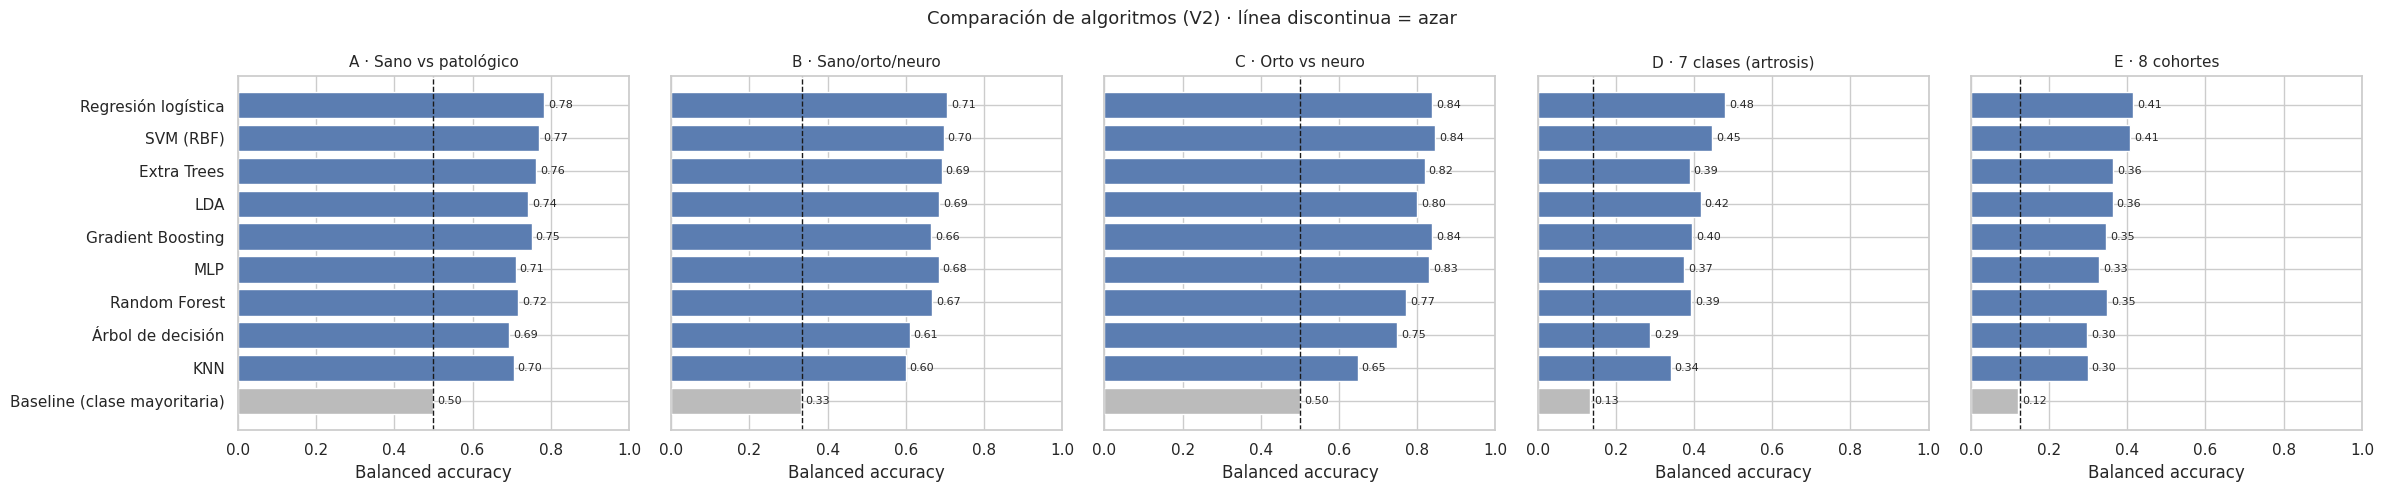

In [ ]:
# Para graficar los resultados anteriores y ver comparación
AZAR = {t: 1 / y.nunique() for t, (_, y) in TAREAS.items()}
fig, axes = plt.subplots(1, len(TAREAS), figsize=(24, 5))
for ax, tarea in zip(axes, TAREAS):
    datos = tabla_alg[tarea].iloc[::-1]
    colores = ["#BBBBBB" if "Baseline" in m else "#5B7DB1" for m in datos.index]
    ax.barh(datos.index, datos.values, color=colores)
    ax.axvline(AZAR[tarea], ls="--", color="k", lw=1)          # nivel de azar
    for i, v in enumerate(datos.values):
        ax.text(v + 0.01, i, f"{v:.2f}", va="center", fontsize=8)
    ax.set_title(tarea, fontsize=11); ax.set_xlim(0, 1); ax.set_xlabel("Balanced accuracy")
    if ax is not axes[0]:
        ax.set_yticklabels([])
plt.suptitle("Comparación de algoritmos (V2) · línea discontinua = azar", fontsize=13)
plt.tight_layout(); guardar_fig("5_2_comparacion_algoritmos"); plt.show()

In [ ]:
# Diferencia de cada modelo respecto al mejor, en la media de las 5 tareas
mejor = tabla_alg["media"].max()
print((mejor - tabla_alg["media"]).round(3).to_frame("distancia al mejor"))

MODELO_REF = "Regresión logística"   # se confirma o cambia tras ver la tabla
print(f"\nModelo de referencia: {MODELO_REF}")

                              distancia al mejor
modelo                                          
Regresión logística                        0.000
SVM (RBF)                                  0.011
Extra Trees                                0.039
LDA                                        0.043
Gradient Boosting                          0.045
MLP                                        0.059
Random Forest                              0.065
Árbol de decisión                          0.117
KNN                                        0.126
Baseline (clase mayoritaria)               0.327

Modelo de referencia: Regresión logística


### 5.3 Aporte de la variabilidad (V1 vs V2)

¿Los modelos clasifican mejor si, además de las medias, les damos la variabilidad?

variables,V1 · Medias,V2 · Medias + variabilidad,mejora
tarea,,,
A · Sano vs patológico,0.796,0.783,-0.014
B · Sano/orto/neuro,0.658,0.706,0.048
C · Orto vs neuro,0.758,0.838,0.080
D · 7 clases (artrosis),0.419,0.480,0.060
E · 8 cohortes,0.379,0.415,0.036


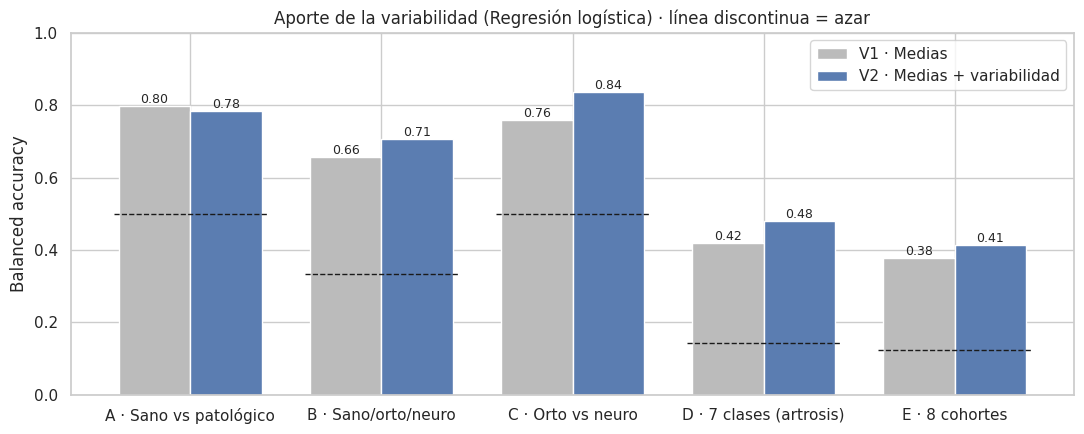

In [ ]:
filas = []
for tarea, (idx, y) in TAREAS.items():
    for nombre_fs, X in [("V1 · Medias", X_V1), ("V2 · Medias + variabilidad", X_V2)]:
        r = evaluar(crear_modelos()[MODELO_REF], X.loc[idx], y, groups.loc[idx])
        filas.append({"tarea": tarea, "variables": nombre_fs, **r})
res_var = pd.DataFrame(filas)

tabla_var = res_var.pivot(index="tarea", columns="variables", values="bal_acc").loc[list(TAREAS)]
tabla_var["mejora"] = tabla_var.iloc[:, 1] - tabla_var.iloc[:, 0]
guardar_tabla(tabla_var.round(3), "5_3_aporte_variabilidad")
display(tabla_var.round(3))

# Gráfico: V1 frente a V2 en cada tarea
ax = tabla_var.iloc[:, :2].plot.bar(figsize=(11, 4.5), color=["#BBBBBB", "#5B7DB1"], rot=0, width=.75)
for t, a in zip(range(len(TAREAS)), AZAR.values()):
    ax.hlines(a, t - .4, t + .4, colors="k", linestyles="--", lw=1)     # nivel de azar
for cont in ax.containers:
    ax.bar_label(cont, fmt="%.2f", fontsize=9)
ax.set_ylabel("Balanced accuracy"); ax.set_xlabel(""); ax.set_ylim(0, 1)
ax.set_title(f"Aporte de la variabilidad ({MODELO_REF}) · línea discontinua = azar")
ax.legend(title=""); plt.tight_layout(); guardar_fig("5_3_aporte_variabilidad"); plt.show()

**Interpretación.** La inclusión de la variabilidad (V2) no mejora la distinción entre marcha sana y patológica (tarea A: −0,01), que se resuelve con los parámetros medios, pero sí mejora de forma consistente la identificación del tipo de patología: +0,05 en la tarea B, +0,08 en la C y +0,06 en la D, mejoras varias veces superiores a la variabilidad entre repeticiones (≈ 0,01–0,02). En la clasificación de las 8 cohortes (tarea E), la mejora es menor (+0,04) y del orden de la variabilidad entre repeticiones. LA VARIABILIDAD SIRVE PARA IDENTIFICAR LA PATOLOGIA QUE ES, NO PARA SABER SI TIENE PROBLEMAS CON LA MARCHA.

Este resultado es coherente con los perfiles descritos en la sección 3.4: las cohortes ortopédicas se caracterizan por alteraciones de los parámetros medios (menor velocidad y longitud del paso, mayor apoyo), mientras que las neurológicas presentan además una marcha irregular. Los parámetros medios permiten detectar que la marcha está alterada, pero la variabilidad es necesaria para distinguir el origen de la alteración.

Dado que la mayor mejora se observa en la tarea C, asociada al tipo de sensor, y que la variabilidad de la longitud de zancada mostró indicios de depender del sistema de medida (sección 3.2), el aporte de la variabilidad se verifica dentro de cada sensor en la sección 5.6.

### 5.4 Métricas complementarias
- **AUC** (tarea A): capacidad de ordenar a los sujetos de más a menos probable de ser patológico, independiente del umbral de decisión.
- **Top-k** (tareas D y E): porcentaje de visitas en las que la patología real está entre las *k* más probables según el modelo. Refleja su uso como **apoyo al diagnóstico diferencial**.
- **AUC por clase** (una contra el resto): qué patologías se reconocen mejor.

In [ ]:
modelo = crear_modelos()[MODELO_REF]

# 1) AUC de todas las tareas
filas_auc = []
for tarea, (idx, y) in TAREAS.items():
    auc_rep = []
    for r in range(N_REPS):
        P, clases = predecir_cv(modelo, X_V2.loc[idx], y, groups.loc[idx], r, proba=True)
        # AUC de cada clase frente al resto y media de todas ellas
        auc_rep.append(np.mean([roc_auc_score(y == c, P[:, i]) for i, c in enumerate(clases)]))
    filas_auc.append({"tarea": tarea, "nº clases": len(clases),
                      "AUC": np.mean(auc_rep), "± sd": np.std(auc_rep)})

tabla_auc = pd.DataFrame(filas_auc).set_index("tarea").round(3)
guardar_tabla(tabla_auc, "5_4_auc_tareas")
display(tabla_auc)

# 2) Top-k solo en las tareas con muchas clases (D y E)
filas_topk = []
for tarea in ["D · 7 clases (artrosis)", "E · 8 cohortes"]:
    idx, y = TAREAS[tarea]
    res = {f"top-{k}": [] for k in (1, 2, 3)}
    for r in range(N_REPS):
        P, clases = predecir_cv(modelo, X_V2.loc[idx], y, groups.loc[idx], r, proba=True)
        for k in (1, 2, 3):
            res[f"top-{k}"].append(top_k_accuracy_score(y, P, k=k, labels=clases))
    filas_topk.append({"tarea": tarea, "azar top-1": 1 / len(clases),
                       **{k: np.mean(v) for k, v in res.items()}})

topk = pd.DataFrame(filas_topk).set_index("tarea").round(3)
guardar_tabla(topk, "5_4_topk")
topk

,nº clases,AUC,± sd
tarea,,,
A · Sano vs patológico,2,0.866,0.005
B · Sano/orto/neuro,3,0.854,0.006
C · Orto vs neuro,2,0.893,0.010
D · 7 clases (artrosis),7,0.816,0.001
E · 8 cohortes,8,0.799,0.011


,azar top-1,top-1,top-2,top-3
tarea,,,,
D · 7 clases (artrosis),0.143,0.466,0.680,0.819
E · 8 cohortes,0.125,0.428,0.645,0.779


Interpretación. Las probabilidades del modelo permiten evaluar su capacidad de discriminación con independencia del umbral de decisión. El AUC es bueno en todas las tareas (0,80–0,89), con una variabilidad entre repeticiones muy baja (sd ≤ 0,011). En la detección de patología (tarea A) alcanza 0,866: un paciente recibe mayor probabilidad de “patológico” que una persona sana en el 87 % de las parejas. En las tareas de identificación (D y E), el AUC se mantiene en torno a 0,80 pese a que la exactitud a la primera es moderada (43–47 %). Esto indica que el modelo ordena correctamente las clases, pero a menudo sitúa la correcta en segundo o tercer lugar. El análisis top-k lo confirma: en la tarea E, la cohorte correcta está entre las dos primeras opciones en el 65 % de los casos y entre las tres primeras en el 78 % (frente al 25 % y el 37,5 % esperables por azar). Desde un punto de vista clínico, el sistema funcionaría mejor como herramienta de apoyo que propone una lista corta de diagnósticos compatibles que como clasificador cerrado.

Precaución. El AUC más alto se obtiene en la distinción ortopédico/neurológico (tarea C, 0,893). Como esta tarea coincide casi por completo con el tipo de sensor, este resultado se revisa en el apartado 5.6.2.

### 5.5 Matrices de confusión

Hasta ahora sabemos cuánto acierta el modelo, pero no en qué se equivoca. La matriz de confusión responde a:

Cuando el modelo falla con un paciente de una cohorte, ¿qué cohorte dice en su lugar?

Predicciones *out-of-fold* de la regresión logística con V2, normalizadas por filas, la diagonal es la sensibilidad de cada clase.

B · Sano/orto/neuro
              precision    recall  f1-score   support

     healthy      0.553     0.722     0.626        79
       ortho      0.543     0.688     0.607        64
       neuro      0.861     0.677     0.758       192

    accuracy                          0.690       335
   macro avg      0.653     0.695     0.664       335
weighted avg      0.728     0.690     0.698       335



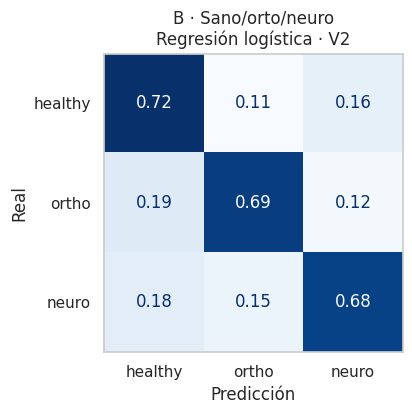

In [ ]:
def matriz_confusion(tarea, etiquetas, nombre_fig):
    idx, y = TAREAS[tarea]
    pred, _ = predecir_cv(crear_modelos()[MODELO_REF], X_V2.loc[idx], y, groups.loc[idx], rep=0)
    print(f"{tarea}\n" + classification_report(y, pred, labels=etiquetas, digits=3))
    cm = confusion_matrix(y, pred, labels=etiquetas, normalize="true")
    fig, ax = plt.subplots(figsize=(1.1 * len(etiquetas) + 2, 1.1 * len(etiquetas) + 1))
    ConfusionMatrixDisplay(cm, display_labels=etiquetas).plot(ax=ax, cmap="Blues", values_format=".2f", colorbar=False)
    ax.grid(False); ax.set_title(f"{tarea}\n{MODELO_REF} · V2")
    ax.set_xlabel("Predicción"); ax.set_ylabel("Real")
    plt.tight_layout(); guardar_fig(nombre_fig); plt.show()

matriz_confusion("B · Sano/orto/neuro", ["healthy", "ortho", "neuro"], "5_5_confusion_grupo")

E · 8 cohortes
              precision    recall  f1-score   support

          HS      0.661     0.519     0.582        79
         HOA      0.303     0.417     0.351        24
         KOA      0.414     0.500     0.453        24
         ACL      0.280     0.438     0.341        16
        CIPN      0.170     0.400     0.239        20
          PD      0.317     0.406     0.356        32
         RIL      0.553     0.313     0.400        83
         CVA      0.627     0.561     0.593        57

    accuracy                          0.445       335
   macro avg      0.416     0.444     0.414       335
weighted avg      0.505     0.445     0.459       335



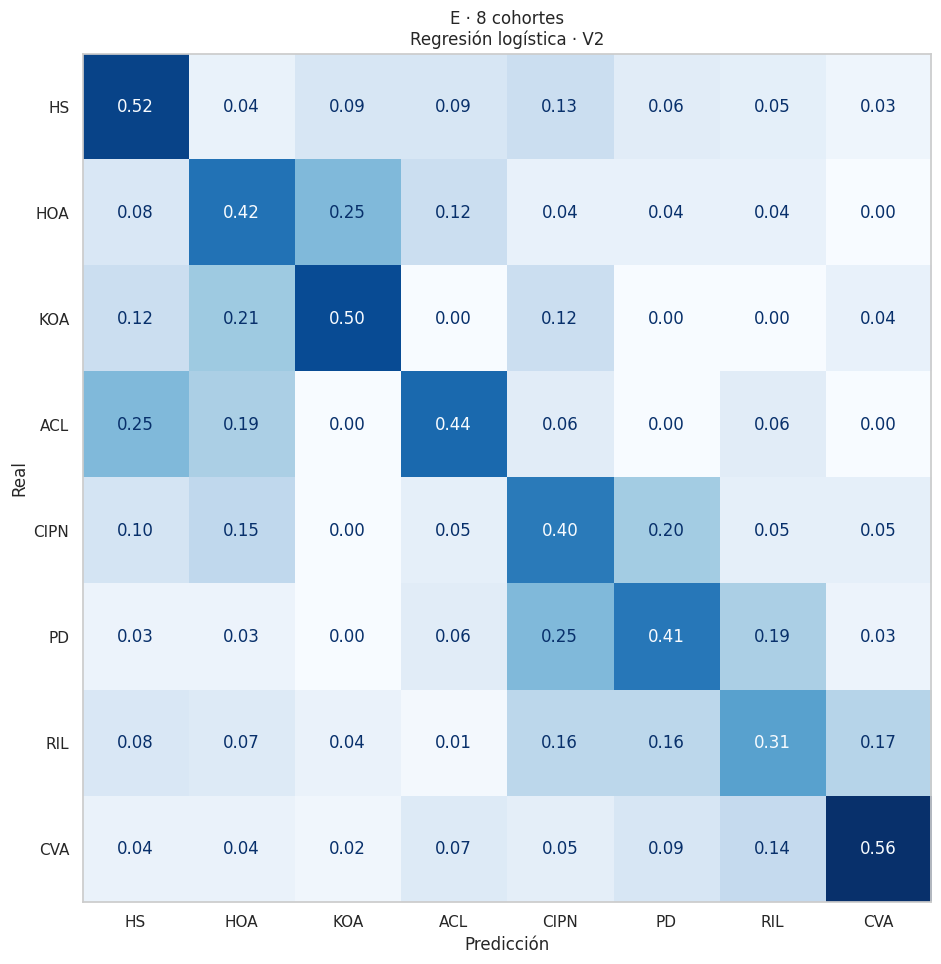

In [ ]:
matriz_confusion("E · 8 cohortes",
                 ["HS", "HOA", "KOA", "ACL", "CIPN", "PD", "RIL", "CVA"],
                 "5_5_confusion_8cohortes")

Interpretación. En la tarea sano/ortopédico/neurológico, las tres clases se reconocen con una sensibilidad similar (0,68–0,72) pese al desbalance (192 visitas neurológicas frente a 64 ortopédicas), gracias a la ponderación de clases. La confusión entre ortopédicos y neurológicos es la menor de la matriz (0,12–0,15). La precisión moderada de sanos y ortopédicos (≈0,55) se explica porque una pequeña fracción de errores de la clase mayoritaria (neurológicos) supone un número de visitas comparable al de estas clases.

En la tarea de 8 cohortes, todas superan la sensibilidad esperable por azar (0,125). Las mejor reconocidas son CVA (0,56), HS (0,52) y KOA (0,50), y la peor, RIL (0,31). Las confusiones no son aleatorias, sino clínicamente coherentes: las dos artrosis se confunden entre sí (HOA↔KOA), los pacientes de ACL, jóvenes y rehabilitados, se clasifican a menudo como sanos (0,25), y los errores de las cohortes neurológicas se dirigen principalmente a otras neurológicas (CIPN↔PD, RIL↔CVA). Entre el 63 % y el 88 % de las predicciones de cada cohorte patológica caen dentro de su mismo grupo (ortopédico o neurológico). Por tanto, el modelo identifica bien el tipo de alteración aunque no siempre la cohorte exacta, lo que concuerda con los resultados top-k. RIL presenta los errores más dispersos, lo que sugiere una cohorte heterogénea en gravedad. La baja precisión de ACL (0,28) y CIPN (0,17) refleja su reducido tamaño (16 y 20 visitas), por lo que estas cifras deben interpretarse con cautela.

### 5.6 Análisis de robustez
Se comprueba que los resultados no se deben a factores de confusión ni a decisiones metodológicas:

1. **Edad:** ¿cuánto se explica solo con la edad? ¿Se mantiene el rendimiento en sujetos de edad comparable?
2. **Sensor:** ¿la mejora de la variabilidad se mantiene dentro de un mismo sensor?
3. **Desbalance:** ¿mejoran los resultados con técnicas de remuestreo (SMOTE, undersampling)?
4. **Hiperparámetros:** ¿mejoran optimizando el modelo?

In [ ]:
# 5.6.1 (a) ¿Cuánto se explica solo con la edad en cada tarea?
modelo = crear_modelos()[MODELO_REF]
edad = V[["age"]].fillna(V["age"].median())

filas = []
for tarea, (idx, y) in TAREAS.items():
    filas.append({
        "tarea": tarea,
        "azar": 1 / y.nunique(),
        "solo edad": evaluar(modelo, edad.loc[idx], y, groups.loc[idx])["bal_acc"],
        "marcha V2": evaluar(modelo, X_V2.loc[idx], y, groups.loc[idx])["bal_acc"],
    })

edad_tareas = pd.DataFrame(filas).set_index("tarea")
edad_tareas["V2 − edad"] = edad_tareas["marcha V2"] - edad_tareas["solo edad"]
edad_tareas = edad_tareas.round(3)
guardar_tabla(edad_tareas, "5_6_1_edad_por_tarea")
edad_tareas

,azar,solo edad,marcha V2,V2 − edad
tarea,,,,
A · Sano vs patológico,0.500,0.788,0.783,-0.006
B · Sano/orto/neuro,0.333,0.494,0.706,0.212
C · Orto vs neuro,0.500,0.463,0.838,0.375
D · 7 clases (artrosis),0.143,0.288,0.480,0.191
E · 8 cohortes,0.125,0.241,0.415,0.174


**Interpretación.** El sesgo de edad afecta fundamentalmente a la detección de patología (tarea A), donde la edad sola alcanza el mismo rendimiento que la marcha (0,788 frente a 0,783). En la distinción ortopédico/neurológico (tarea C), la edad no aporta información (0,463, por debajo del azar), por lo que el rendimiento de la marcha (0,838) no se explica por diferencias de edad. En las tareas B, D y E, la edad supera ligeramente el azar porque permite separar los grupos más jóvenes (sanos y ACL), pero la marcha la supera ampliamente (+0,17 a +0,21). Por tanto, la capacidad de los modelos para identificar el tipo de patología no se debe a la edad. La tarea A requiere un análisis específico, que se realiza a continuación.

In [ ]:
# 5.6.1 (b) Tarea A: todas las visitas vs solo sujetos ≥ 45 años
idx, y = TAREAS["A · Sano vs patológico"]
mayores = V["age"] >= 45

filas = []
for nombre, X in [("Solo edad", edad), ("Marcha V1", X_V1), ("Marcha V2", X_V2)]:
    filas.append({
        "modelo": nombre,
        "todas las visitas": evaluar(modelo, X, y, groups)["bal_acc"],
        "solo ≥ 45 años": evaluar(modelo, X[mayores], y[mayores], groups[mayores])["bal_acc"],
    })

robust_edad = pd.DataFrame(filas).set_index("modelo").round(3)
guardar_tabla(robust_edad, "5_6_1_robustez_edad")

print(f"Visitas ≥ 45 años: {y[mayores].value_counts().to_dict()}")
print(f"Marcha V2 + edad (todas las visitas, NO recomendado): "
      f"{evaluar(modelo, X_V2.join(edad), y, groups)['bal_acc']:.3f}")
robust_edad

Visitas ≥ 45 años: {'patológico': 224, 'sano': 23}
Marcha V2 + edad (todas las visitas, NO recomendado): 0.812


,todas las visitas,solo ≥ 45 años
modelo,,
Solo edad,0.788,0.474
Marcha V1,0.796,0.649
Marcha V2,0.783,0.689


**Interpretación.** Con todas las visitas, la edad sola clasifica sanos y pacientes igual que la marcha (0,788), lo que refleja un sesgo del diseño del dataset. Por ello la edad no se incluye como variable: aunque añadirla mejora ligeramente el resultado (0,812), el modelo estaría explotando una característica de la muestra no generalizable a la práctica clínica. Al restringir el análisis a sujetos de 45 años o más, la edad deja de discriminar (0,474, nivel de azar), mientras que la marcha mantiene un rendimiento claramente superior (V1: 0,649; V2: 0,689). Esto demuestra que los parámetros de marcha contienen información sobre la patología independiente de la edad. En este subgrupo, además, la variabilidad sí aporta mejora (+0,04), lo que sugiere que, una vez controlado el efecto del envejecimiento sobre los parámetros medios, la variabilidad resulta más específica de la patología.

**Limitaciones.** El rendimiento con edad comparable es inferior al global, por lo que parte del acierto en la tarea A con todas las visitas se debe a diferencias asociadas a la edad. La estimación de 0,689 debe considerarse la medida más realista de la capacidad de detección. Además, el subgrupo incluye solo 23 visitas de sujetos sanos, lo que limita la precisión de esta estimación.

In [ ]:
# 5.6.2 (a) ¿Cuánto se explica solo con el sensor en cada tarea?
modelo = crear_modelos()[MODELO_REF]
solo_sensor = pd.get_dummies(V["sensor"]).astype(float)

filas = []
for tarea, (idx, y) in TAREAS.items():
    filas.append({
        "tarea": tarea,
        "azar": 1 / y.nunique(),
        "solo sensor": evaluar(modelo, solo_sensor.loc[idx], y, groups.loc[idx])["bal_acc"],
        "marcha V2": evaluar(modelo, X_V2.loc[idx], y, groups.loc[idx])["bal_acc"],
    })

sensor_tareas = pd.DataFrame(filas).set_index("tarea")
sensor_tareas["V2 − sensor"] = sensor_tareas["marcha V2"] - sensor_tareas["solo sensor"]
sensor_tareas = sensor_tareas.round(3)
guardar_tabla(sensor_tareas, "5_6_2_sensor_por_tarea")
sensor_tareas

,azar,solo sensor,marcha V2,V2 − sensor
tarea,,,,
A · Sano vs patológico,0.500,0.703,0.783,0.080
B · Sano/orto/neuro,0.333,0.632,0.706,0.074
C · Orto vs neuro,0.500,0.948,0.838,-0.110
D · 7 clases (artrosis),0.143,0.294,0.480,0.185
E · 8 cohortes,0.125,0.263,0.415,0.152


Interpretación. El tipo de sensor está fuertemente asociado al grupo clínico: todos los pacientes ortopédicos se registraron con XSens y la mayoría de los neurológicos con TechnoConcept. Un modelo que solo conoce el sensor distingue ortopédicos de neurológicos con una exactitud equilibrada de 0,948, superior a la de la marcha (0,838), por lo que el resultado de la tarea C con todas las visitas no permite separar el efecto de la marcha del del sensor. En las tareas A y B, el sensor solo alcanza 0,70 y 0,63, y la marcha lo supera por un margen moderado (+0,07–0,08). En las tareas D y E, el sensor apenas supera el azar y la marcha lo supera ampliamente (+0,15–0,19). Para comprobar si la marcha funciona sin la ayuda del sensor, se repite el análisis dentro de cada sensor.

In [ ]:
# 5.6.2 (b) ¿Sigue funcionando la marcha dentro de un mismo sensor?
filas = []
for sensor in V["sensor"].unique():
    en_sensor = V["sensor"] == sensor
    for tarea in ["A · Sano vs patológico", "C · Orto vs neuro", "E · 8 cohortes"]:
        idx, y = TAREAS[tarea]
        y_s = y[en_sensor.loc[idx]]
        y_s = y_s[y_s.map(y_s.value_counts()) >= 10]      # quita clases con muy pocas visitas
        if y_s.nunique() < 2:                              # hace falta al menos 2 clases
            continue
        filas.append({
            "sensor": sensor, "tarea": tarea,
            "clases": ", ".join(sorted(y_s.unique())),
            "visitas por clase": y_s.value_counts().to_dict(),
            "azar": 1 / y_s.nunique(),
            "marcha V2": evaluar(modelo, X_V2.loc[y_s.index], y_s, groups.loc[y_s.index])["bal_acc"],
        })

robust_sensor = pd.DataFrame(filas).set_index(["sensor", "tarea"]).round(3)
guardar_tabla(robust_sensor, "5_6_2_robustez_sensor")
robust_sensor

clases  \
sensor           tarea                                            
MTw Awinda XSens A · Sano vs patológico        patológico, sano   
                 C · Orto vs neuro                 neuro, ortho   
                 E · 8 cohortes          ACL, HOA, HS, KOA, RIL   
TechnoConcept    A · Sano vs patológico        patológico, sano   
                 E · 8 cohortes          CIPN, CVA, HS, PD, RIL   

                                                                         visitas por clase  \
sensor           tarea                                                                       
MTw Awinda XSens A · Sano vs patológico                     {'patológico': 84, 'sano': 58}   
                 C · Orto vs neuro                              {'ortho': 64, 'neuro': 20}   
                 E · 8 cohortes          {'HS': 58, 'KOA': 24, 'HOA': 24, 'ACL': 16, 'R...   
TechnoConcept    A · Sano vs patológico                    {'patológico': 172, 'sano': 21}   
                 E · 8 cohortes          {'RIL': 69, 'CVA': 57, 'PD': 27, 'HS': 21, 'CI...   

                                         azar  marcha V2  
sensor           tarea                                    
MTw Awinda XSens A · Sano vs patológico   0.5      0.782  
                 C · Orto vs neuro        0.5      0.686  
                 E · 8 cohortes           0.2      0.405  
TechnoConcept    A · Sano vs patológico   0.5      0.816  
                 E · 8 cohortes           0.2      0.407

Interpretación. Dentro de un mismo sensor, este no puede contribuir a la clasificación. En la detección de patología (tarea A), la marcha mantiene el mismo rendimiento que con todas las visitas (XSens: 0,782; TechnoConcept: 0,816), y en la identificación de cohortes (tarea E) sigue duplicando el nivel de azar en ambos sensores (0,405 y 0,407 frente a 0,20). Por tanto, estos resultados no se deben al sensor. En la distinción ortopédico/neurológico, evaluable solo dentro de XSens, la marcha sigue superando el azar (0,686), pero con un rendimiento claramente inferior al obtenido con todas las visitas (0,838). Esto indica que parte de ese resultado se debía al sensor, y 0,686 debe considerarse la estimación realista. Esta estimación es además orientativa, ya que solo se dispone de 20 visitas neurológicas registradas con XSens.

In [ ]:
# 5.6.3 Optimización de hiperparámetros (validación anidada y agrupada por sujeto)
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV

# Buscadores que agrupan por sujeto también en la validación interna
class GridAgrupado(GridSearchCV):
    def fit(self, X, y):
        return super().fit(X, y, groups=groups.loc[X.index])

class RandomAgrupado(RandomizedSearchCV):
    def fit(self, X, y):
        return super().fit(X, y, groups=groups.loc[X.index])

cv_interna = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=RANDOM_STATE)
base = crear_modelos()

# Los 3 mejores modelos del apartado 5.2: (modelo sin optimizar, buscador)
busquedas = {
    "Regresión logística": (
        base["Regresión logística"],
        GridAgrupado(base["Regresión logística"],
                     {"clf__C": [0.01, 0.03, 0.1, 0.3, 1, 3, 10]},
                     cv=cv_interna, scoring="balanced_accuracy", n_jobs=-1)),
    "SVM (RBF)": (
        base["SVM (RBF)"],
        RandomAgrupado(base["SVM (RBF)"],
                       {"clf__C": [0.1, 0.3, 1, 3, 10, 30, 100],
                        "clf__gamma": ["scale", 0.001, 0.01, 0.1, 1]},
                       n_iter=20, cv=cv_interna, scoring="balanced_accuracy",
                       random_state=RANDOM_STATE, n_jobs=-1)),
    "Extra Trees": (
        base["Extra Trees"],
        RandomAgrupado(base["Extra Trees"],
                       {"clf__n_estimators": [200, 300],
                        "clf__max_depth": [None, 5, 10],
                        "clf__min_samples_leaf": [1, 3, 5],
                        "clf__max_features": ["sqrt", "log2", None]},
                       n_iter=10, cv=cv_interna, scoring="balanced_accuracy",
                       random_state=RANDOM_STATE, n_jobs=-1)),
}

filas = []
for tarea, (idx, y) in TAREAS.items():
    X, g = X_V2.loc[idx], groups.loc[idx]
    for nombre, (sin_opt, buscador) in busquedas.items():
        filas.append({"tarea": tarea, "modelo": nombre,
                      "sin optimizar": evaluar(sin_opt, X, y, g)["bal_acc"],
                      "optimizado": evaluar(buscador, X, y, g)["bal_acc"]})
    print(f"✓ {tarea}")

robust_hp = pd.DataFrame(filas).set_index(["tarea", "modelo"])
robust_hp["mejora"] = robust_hp["optimizado"] - robust_hp["sin optimizar"]
robust_hp = robust_hp.round(3)
guardar_tabla(robust_hp, "5_6_3_hiperparametros")
robust_hp

✓ A · Sano vs patológico
✓ B · Sano/orto/neuro
✓ C · Orto vs neuro
✓ D · 7 clases (artrosis)
✓ E · 8 cohortes


sin optimizar  optimizado  mejora
tarea                   modelo                                                
A · Sano vs patológico  Regresión logística          0.783       0.786   0.003
                        SVM (RBF)                    0.771       0.786   0.015
                        Extra Trees                  0.762       0.777   0.016
B · Sano/orto/neuro     Regresión logística          0.706       0.701  -0.005
                        SVM (RBF)                    0.697       0.705   0.008
                        Extra Trees                  0.692       0.699   0.006
C · Orto vs neuro       Regresión logística          0.838       0.840   0.003
                        SVM (RBF)                    0.845       0.853   0.009
                        Extra Trees                  0.819       0.861   0.043
D · 7 clases (artrosis) Regresión logística          0.480       0.474  -0.006
                        SVM (RBF)                    0.446       0.461   0.015
                        Extra Trees                  0.389       0.396   0.007
E · 8 cohortes          Regresión logística          0.415       0.411  -0.004
                        SVM (RBF)                    0.407       0.405  -0.002
                        Extra Trees                  0.364       0.359  -0.005

Interpretación. Se optimizaron los hiperparámetros de los tres mejores modelos del apartado 5.2 mediante validación cruzada anidada y agrupada por sujeto. La búsqueda se realizó dentro de cada fold de entrenamiento (GridSearchCV para la regresión logística y RandomizedSearchCV para SVM y Extra Trees), de modo que los datos de evaluación nunca intervinieron en la selección. Las mejoras obtenidas son muy reducidas (entre −0,006 y +0,016 en casi todos los casos), del mismo orden que la variabilidad entre repeticiones. La regresión logística no mejora con la optimización (media de 0,644 sin optimizar y 0,642 optimizada), lo que indica que su configuración por defecto ya era adecuada. Los ligeros descensos observados en algunas tareas reflejan la incertidumbre de seleccionar hiperparámetros con muestras reducidas y confirman que la validación anidada no produce estimaciones optimistas. El SVM optimizado alcanza a la regresión logística (0,642 de media en ambos), pero no la supera, por lo que se mantiene esta última por ser más sencilla e interpretable. La única mejora apreciable corresponde a Extra Trees en la distinción ortopédico/neurológico (+0,043). Como esta tarea está condicionada por el tipo de sensor (apartado 5.6.2), esta mejora no se interpreta como una mayor capacidad para analizar la marcha. En conjunto, estos resultados indican que el rendimiento está limitado por la información contenida en los parámetros de marcha, y no por el algoritmo o su ajuste.

## 6. Interpretabilidad: ¿qué parámetros describen cada patología?


### 6.1 Importancia global
▶ **Qué hace esta celda:** calcula la importancia de las variables para detectar patología (tarea A) y para identificar la cohorte (tarea E). La tarea C no se analiza porque está condicionada por el sensor (5.6.2).

👀 **Qué mirar en el resultado:** qué variables encabezan cada gráfico y si son de media (azul) o de variabilidad (naranja).

In [ ]:
# Variables de variabilidad (las que V2 añade a V1)
FEAT_VARIAB = [c for c in X_V2.columns if c not in X_V1.columns]

def importancia_permutacion(modelo_base, X, y, g, n_repeats=10, reps=N_REPS):
    importancias = []
    for r in range(reps):
        for tr, te in particiones(X, y, g, r):
            m = clone(modelo_base).fit(X.iloc[tr], y.iloc[tr])
            res = permutation_importance(m, X.iloc[te], y.iloc[te], scoring="balanced_accuracy",
                                         n_repeats=n_repeats, random_state=RANDOM_STATE, n_jobs=-1)
            importancias.append(res.importances_mean)
    imp = pd.DataFrame(importancias, columns=X.columns)
    return pd.DataFrame({"media": imp.mean(), "sd": imp.std()}).sort_values("media", ascending=False)

def grafico_importancia(imp, titulo, nombre_fig, top=15):
    imp = imp.head(top)[::-1]
    colores = ["#E8A33D" if c in FEAT_VARIAB else "#5B7DB1" for c in imp.index]
    plt.figure(figsize=(8, 0.4 * len(imp) + 1))
    plt.barh(imp.index, imp["media"], xerr=imp["sd"], color=colores, alpha=.9)
    plt.axvline(0, color="k", lw=.8)
    plt.xlabel("Caída de balanced accuracy al permutar")
    plt.title(titulo + "\n(azul = media/asimetría · naranja = variabilidad)")
    plt.tight_layout(); guardar_fig(nombre_fig); plt.show()

Interpretación. En la detección de patología (tarea A), el modelo se apoya principalmente en tres variables: la atenuación del impacto (0,146), la longitud de zancada normalizada (0,080) y la variabilidad de la longitud de zancada (0,040). El resto presenta importancias pequeñas cuyo intervalo incluye el cero. En la identificación de cohortes (tarea E), la importancia se reparte entre un número mayor de variables (unas diez con aportaciones entre 0,04 y 0,12), lo que indica que cada cohorte se caracteriza por una combinación propia de alteraciones. La variabilidad de la longitud de zancada asciende al segundo puesto (0,117), y entre las quince variables más importantes aparecen cuatro de variabilidad, frente a una en la tarea A. Esto confirma, mediante un método distinto, lo observado en el apartado 5.3: la variabilidad aporta poco a la detección de patología, pero contribuye a su identificación.

La ausencia de la velocidad y la cadencia entre las variables más importantes de la tarea A no implica que no estén alteradas (apartado 3.3). Se debe a su correlación con la longitud de zancada: al permutar una de ellas, el modelo recupera la información a través de las demás, por lo que la importancia se concentra en una sola.

### 6.2 Qué hace específica a cada cohorte
Para cada cohorte se entrena un modelo **esa cohorte frente a todas las demás** y se calcula la importancia de cada variable. Complementa al apartado 3.4: allí se veía en qué se diferencia cada patología de los **sanos**; aquí, qué la hace **específica** frente al resto de cohortes.

▶ **Qué hace esta celda:** entrena un modelo por cohorte (esa cohorte frente al resto), calcula la importancia de cada variable y lo muestra en un mapa de calor.

👀 **Qué mirar en el resultado:** las celdas más oscuras de cada columna, que son las variables que hacen específica a esa cohorte, y si las de variabilidad (parte de abajo) pesan más en unas cohortes que en otras.

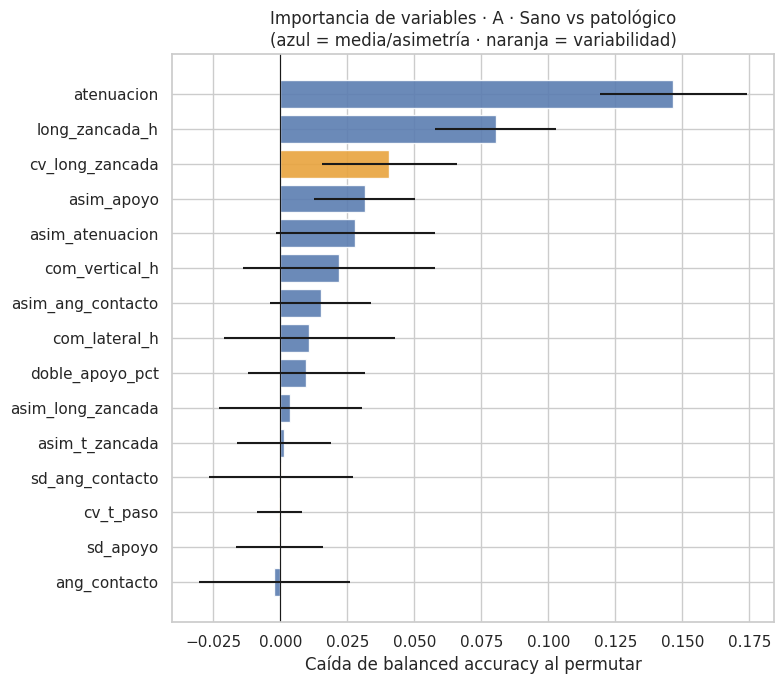

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning:

y_pred contains classes not in y_true



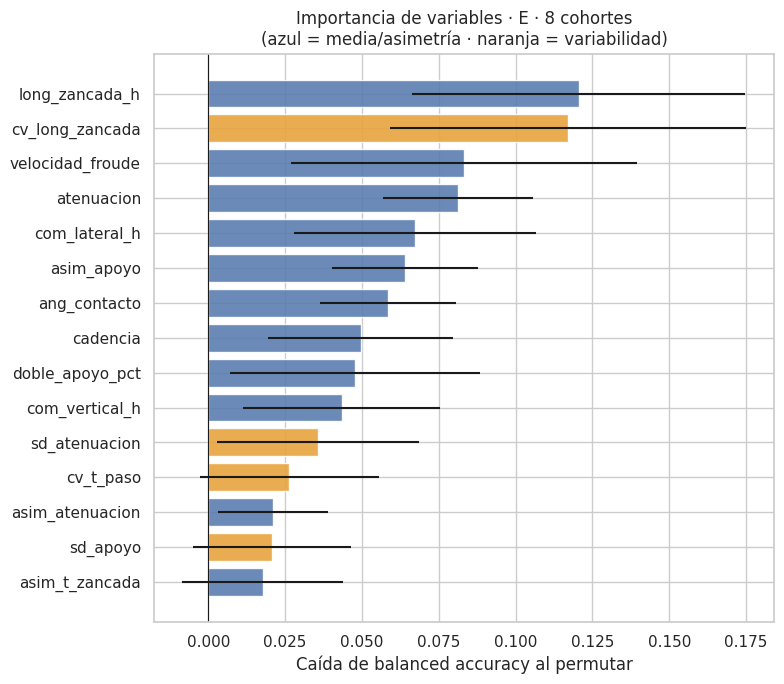

In [ ]:
for tarea, nombre_fig in [("A · Sano vs patológico", "6_1_importancia_sano_patologico"),
                          ("E · 8 cohortes", "6_1_importancia_8cohortes")]:
    idx, y = TAREAS[tarea]
    imp = importancia_permutacion(crear_modelos()[MODELO_REF], X_V2.loc[idx], y, groups.loc[idx], reps=1)
    guardar_tabla(imp.round(4), nombre_fig)
    grafico_importancia(imp, f"Importancia de variables · {tarea}", nombre_fig)

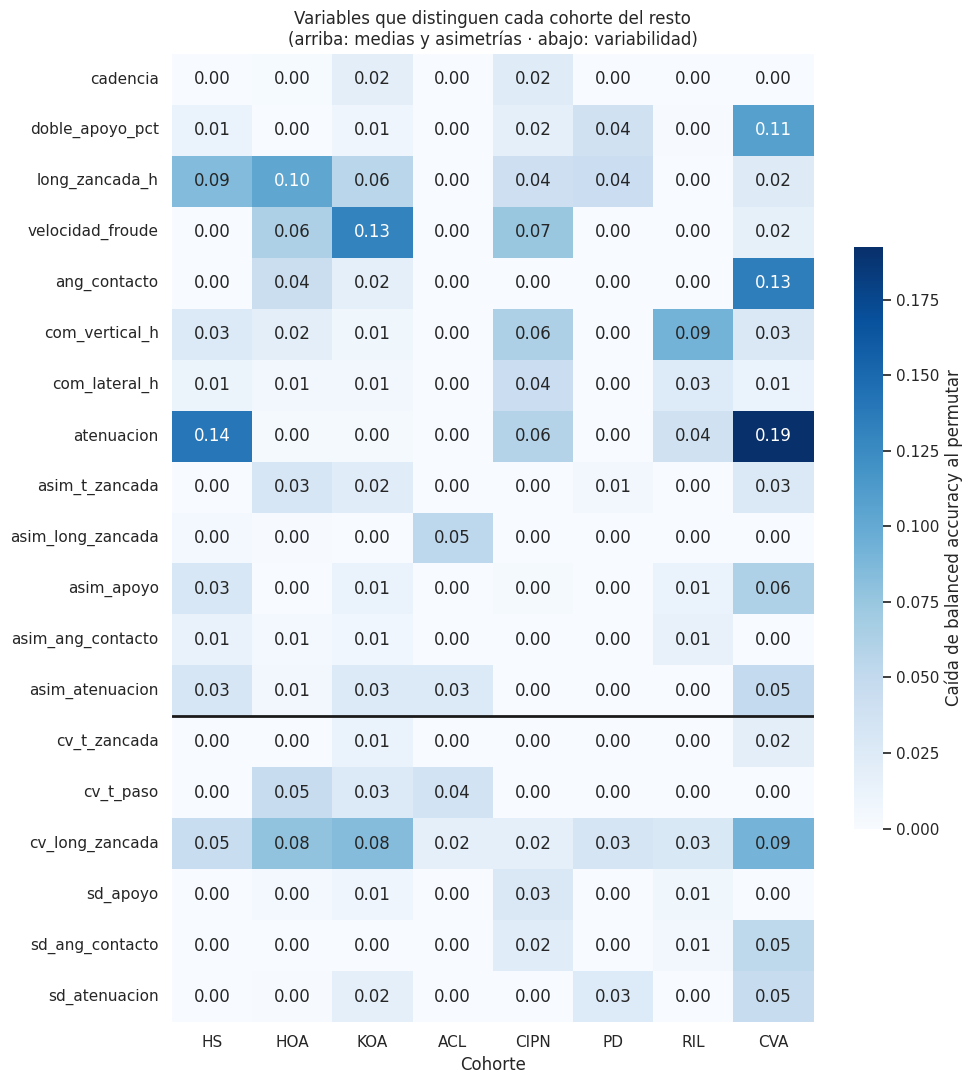

In [ ]:
ORDEN_COH = ["HS", "HOA", "KOA", "ACL", "CIPN", "PD", "RIL", "CVA"]   # mismo orden que en el 5.5

imp_ovr = {}
for p in ORDEN_COH:
    y_ovr = V["pathologyKey"].map(lambda k: p if k == p else "resto")
    imp_ovr[p] = importancia_permutacion(crear_modelos()[MODELO_REF], X_V2, y_ovr, groups,
                                         n_repeats=5, reps=1)["media"]

imp_ovr = pd.DataFrame(imp_ovr).loc[X_V2.columns, ORDEN_COH]

plt.figure(figsize=(10, 11))
sns.heatmap(imp_ovr.clip(lower=0), annot=True, fmt=".2f", cmap="Blues",
            cbar_kws={"label": "Caída de balanced accuracy al permutar", "shrink": .6})
plt.axhline(X_V1.shape[1], color="k", lw=2)
plt.title("Variables que distinguen cada cohorte del resto\n(arriba: medias y asimetrías · abajo: variabilidad)")
plt.xlabel("Cohorte"); plt.ylabel("")
plt.tight_layout(); guardar_fig("6_2_importancia_por_cohorte"); plt.show()
guardar_tabla(imp_ovr.round(4), "6_2_importancia_por_cohorte")

Interpretación. El análisis de cada cohorte frente al resto permite identificar las variables que la hacen específica. CVA presenta la firma más marcada y diversa: atenuación del impacto (0,19), ángulo de contacto del pie (0,13), porcentaje de doble apoyo (0,11), variabilidad de la longitud de zancada (0,09) y asimetría del apoyo (0,06). Este patrón es coherente con la hemiparesia característica del ictus. Las dos artrosis (HOA y KOA) dependen de las mismas variables (longitud de zancada, velocidad y variabilidad de la zancada), lo que explica su confusión mutua en el apartado 5.5. ACL muestra una firma débil basada únicamente en asimetrías, compatible con una afectación unilateral de la rodilla en pacientes rehabilitados. CIPN y RIL dependen principalmente del desplazamiento del centro de masas, relacionado con el control del tronco, y PD no muestra ninguna variable claramente dominante.

La intensidad de la firma de cada cohorte se corresponde con su sensibilidad en la matriz de confusión: las cohortes con más variables importantes (CVA, HS, KOA) son las mejor reconocidas, y las de firma débil o basada en una sola variable (RIL, PD, ACL) las peores. Entre las variables de variabilidad, solo la de la longitud de zancada contribuye de forma generalizada. El resto aporta en cohortes concretas, especialmente en CVA.

Limitaciones. Las variables correlacionadas reparten su importancia, por lo que algunas, como la cadencia o la variabilidad del tiempo de zancada, aparecen con importancia nula aunque contengan información relevante. Además, las estimaciones de las cohortes de menor tamaño (ACL, CIPN) son menos estables.

## 7. Estimación de la severidad

La pregunta: ¿se puede saber lo grave que está un paciente solo con cómo anda, sin pasarle la escala clínica?

En cada visita, el paciente anduvo con los sensores y fue evaluado por un clínico con una escala (WOMAC, UPDRS...). Si los parámetros de marcha reflejan esa puntuación, los sensores servirían como una medida objetiva de la gravedad**, útil para seguir la evolución sin depender de cuestionarios ni de la exploración clínica.

In [ ]:
def particiones_sujeto(g, n_splits, seed):
    """Folds por sujeto con reparto aleatorio (distinto en cada repetición)."""
    sujetos_ = np.random.RandomState(seed).permutation(g.unique())
    fold_de = {s: i % n_splits for i, s in enumerate(sujetos_)}
    f = g.map(fold_de).values
    return [(np.where(f != k)[0], np.where(f == k)[0]) for k in range(n_splits)]

# cohorte: (escala, puntuación máxima, ¿puntuación alta = mejor estado?)
ESCALAS = {
    "HOA":  ("WOMAC",     100, True),    # alto = mejor en este dataset (apartado 2.4)
    "KOA":  ("WOMAC",     100, True),    # alto = mejor en este dataset (apartado 2.4)
    "ACL":  ("IKDC",      100, True),
    "CVA":  ("FMA-LE",     34, True),
    "PD":   ("UPDRS III", 108, False),
    "CIPN": ("TNSc",       28, False),
    "RIL":  ("OCS",        12, False),
}

def severidad_normalizada(fila):
    _, maximo, alto_es_mejor = ESCALAS[fila["pathologyKey"]]
    s = fila["evaluationScoreValue"] / maximo
    return 1 - s if alto_es_mejor else s

S = V[V["pathologyKey"].isin(ESCALAS) & V["evaluationScoreValue"].notna()].copy()
S["severidad"] = S.apply(severidad_normalizada, axis=1)
X_S = ingenieria_variables(S, variabilidad=True)

resumen_sev = S.groupby("pathologyKey").agg(
    escala=("pathologyKey", lambda p: ESCALAS[p.iloc[0]][0]),
    sujetos=("subject", "nunique"), visitas=("subject", "size"),
    score_mediana=("evaluationScoreValue", "median"),
    severidad_media=("severidad", "mean")).round(2)

MIN_SUJETOS = 10
COHORTES_SEV = [p for p in ORDEN if p in resumen_sev.index and resumen_sev.loc[p, "sujetos"] >= MIN_SUJETOS]
print("Cohortes analizadas:", COHORTES_SEV)
resumen_sev.loc[COHORTES_SEV]

Cohortes analizadas: ['HOA', 'KOA', 'ACL', 'CVA', 'PD', 'CIPN', 'RIL']


,escala,sujetos,visitas,score_mediana,severidad_media
pathologyKey,,,,,
HOA,WOMAC,15,24,70.5,0.30
KOA,WOMAC,18,24,53.0,0.49
ACL,IKDC,11,16,75.5,0.33
CVA,FMA-LE,49,57,27.0,0.22
PD,UPDRS III,24,32,34.0,0.31
CIPN,TNSc,18,19,5.0,0.21
RIL,OCS,45,75,7.0,0.53


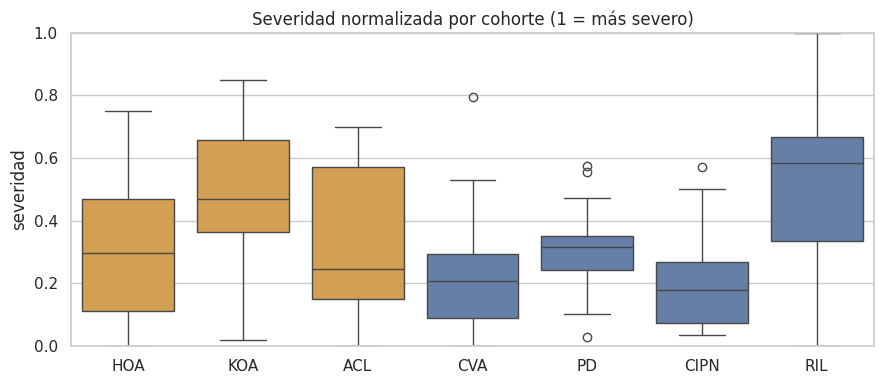

In [ ]:
# boxplot de la severidad por cohorte
plt.figure(figsize=(9, 4))
sns.boxplot(data=S, x="pathologyKey", y="severidad", order=COHORTES_SEV, hue="pathologyKey",
            palette=PALETA, legend=False)
plt.title("Severidad normalizada por cohorte (1 = más severo)"); plt.xlabel(""); plt.ylim(0, 1)
plt.tight_layout(); guardar_fig("7_1_severidad_por_cohorte"); plt.show()

Interpretación. Las siete cohortes patológicas superan el mínimo de 10 sujetos, aunque ACL se sitúa en el límite (11 sujetos, 16 visitas), por lo que sus resultados deben interpretarse con cautela. Se dispone de puntuación clínica en 247 visitas. Todas las cohortes presentan variabilidad en la severidad, condición necesaria para estudiar su relación con la marcha, aunque en distinto grado. HOA, KOA, ACL y RIL cubren un rango amplio de gravedad, mientras que CVA y CIPN se concentran en valores leves y PD presenta un rango muy estrecho (rango intercuartílico de 0,24 a 0,35), lo que limitará la capacidad de detectar asociaciones en esta cohorte. Las diferencias de severidad media entre cohortes no implican diferencias clínicas de gravedad, ya que las escalas no son equivalentes. Por ello, la relación entre marcha y severidad se analiza dentro de cada cohorte.

### 7.2 Índice de desviación de la marcha

Si la marcha refleja la gravedad, los pacientes cuya marcha se aleja más de lo normal deberían ser los más graves.

Lo especial de este enfoque es que no aprende nada de la escala clínica. Solo compara la marcha de cada paciente con la de las personas sanas. Si aun así coincide con la escala, es una prueba muy sólida

indice_V1: AUC sano vs patológico = 0.745 | solo ≥ 45 años = 0.672
indice_V2: AUC sano vs patológico = 0.745 | solo ≥ 45 años = 0.655


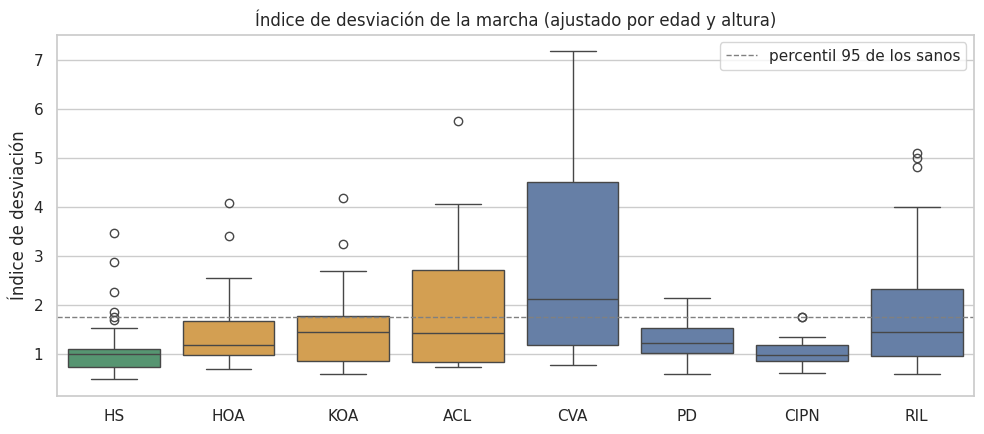

In [ ]:
def indice_desviacion(datos, X, covariables=("age", "height_m")):
    covs = datos[list(covariables)]
    validos = covs.notna().all(axis=1)
    datos, X, covs = datos[validos], X[validos], covs[validos]
    Xi = X.fillna(X.median())
    sano = datos["pathologyKey"] == "HS"
    Z = pd.DataFrame(index=X.index, columns=X.columns, dtype=float)

    def ajustar_y_aplicar(idx_ajuste, idx_aplicar):
        for c in X.columns:
            reg = LinearRegression().fit(covs.loc[idx_ajuste], Xi.loc[idx_ajuste, c])
            sd = (Xi.loc[idx_ajuste, c] - reg.predict(covs.loc[idx_ajuste])).std()
            Z.loc[idx_aplicar, c] = (Xi.loc[idx_aplicar, c] - reg.predict(covs.loc[idx_aplicar])) / sd

    idx_sanos = datos.index[sano]
    for tr, te in particiones_sujeto(datos.loc[idx_sanos, "subject"], 5, RANDOM_STATE):
        ajustar_y_aplicar(idx_sanos[tr], idx_sanos[te])          # sanos: sin usarse a sí mismos
    ajustar_y_aplicar(idx_sanos, datos.index[~sano])              # pacientes: con todos los sanos
    return np.sqrt((Z ** 2).mean(axis=1)), Z

V_idx = V.copy()
V_idx["indice_V1"], _ = indice_desviacion(V, X_V1)
V_idx["indice_V2"], Z_V2 = indice_desviacion(V, X_V2)
V_idx = V_idx.dropna(subset=["indice_V2"])
V_idx["severidad"] = np.nan
comunes = S.index.intersection(V_idx.index)
V_idx.loc[comunes, "severidad"] = S.loc[comunes, "severidad"]

sano = V_idx["pathologyKey"] == "HS"
mayores = V_idx["age"] >= 45
for col in ["indice_V1", "indice_V2"]:
    print(f"{col}: AUC sano vs patológico = {roc_auc_score(~sano, V_idx[col]):.3f} | "
          f"solo ≥ 45 años = {roc_auc_score(~sano[mayores], V_idx.loc[mayores, col]):.3f}")

plt.figure(figsize=(10, 4.5))
sns.boxplot(data=V_idx, x="pathologyKey", y="indice_V2", order=ORDEN, hue="pathologyKey",
            palette=PALETA, legend=False)
plt.axhline(V_idx.loc[sano, "indice_V2"].quantile(.95), ls="--", color="grey", lw=1,
            label="percentil 95 de los sanos")
plt.title("Índice de desviación de la marcha (ajustado por edad y altura)")
plt.xlabel(""); plt.ylabel("Índice de desviación"); plt.legend()
plt.tight_layout(); guardar_fig("7_2_indice_por_cohorte"); plt.show()

In [ ]:
filas = []
con_sev = V_idx.dropna(subset=["severidad"])
for p in COHORTES_SEV:
    d = con_sev[con_sev["pathologyKey"] == p]
    fila = {"cohorte": p, "escala": ESCALAS[p][0], "visitas": len(d)}
    for col in ["indice_V1", "indice_V2"]:
        r, pval_ = spearmanr(d[col], d["severidad"])
        fila[f"ρ {col}"], fila[f"p {col}"] = r, pval_
    filas.append(fila)

indice_sev = pd.DataFrame(filas).set_index("cohorte").round(3)
guardar_tabla(indice_sev, "7_2_indice_vs_severidad")
indice_sev

,escala,visitas,ρ indice_V1,p indice_V1,ρ indice_V2,p indice_V2
cohorte,,,,,,
HOA,WOMAC,24,0.607,0.002,0.626,0.001
KOA,WOMAC,24,0.663,0.000,0.701,0.000
ACL,IKDC,16,0.717,0.002,0.736,0.001
CVA,FMA-LE,57,0.601,0.000,0.594,0.000
PD,UPDRS III,31,-0.408,0.023,-0.299,0.102
CIPN,TNSc,19,-0.012,0.960,-0.004,0.989
RIL,OCS,73,0.501,0.000,0.568,0.000


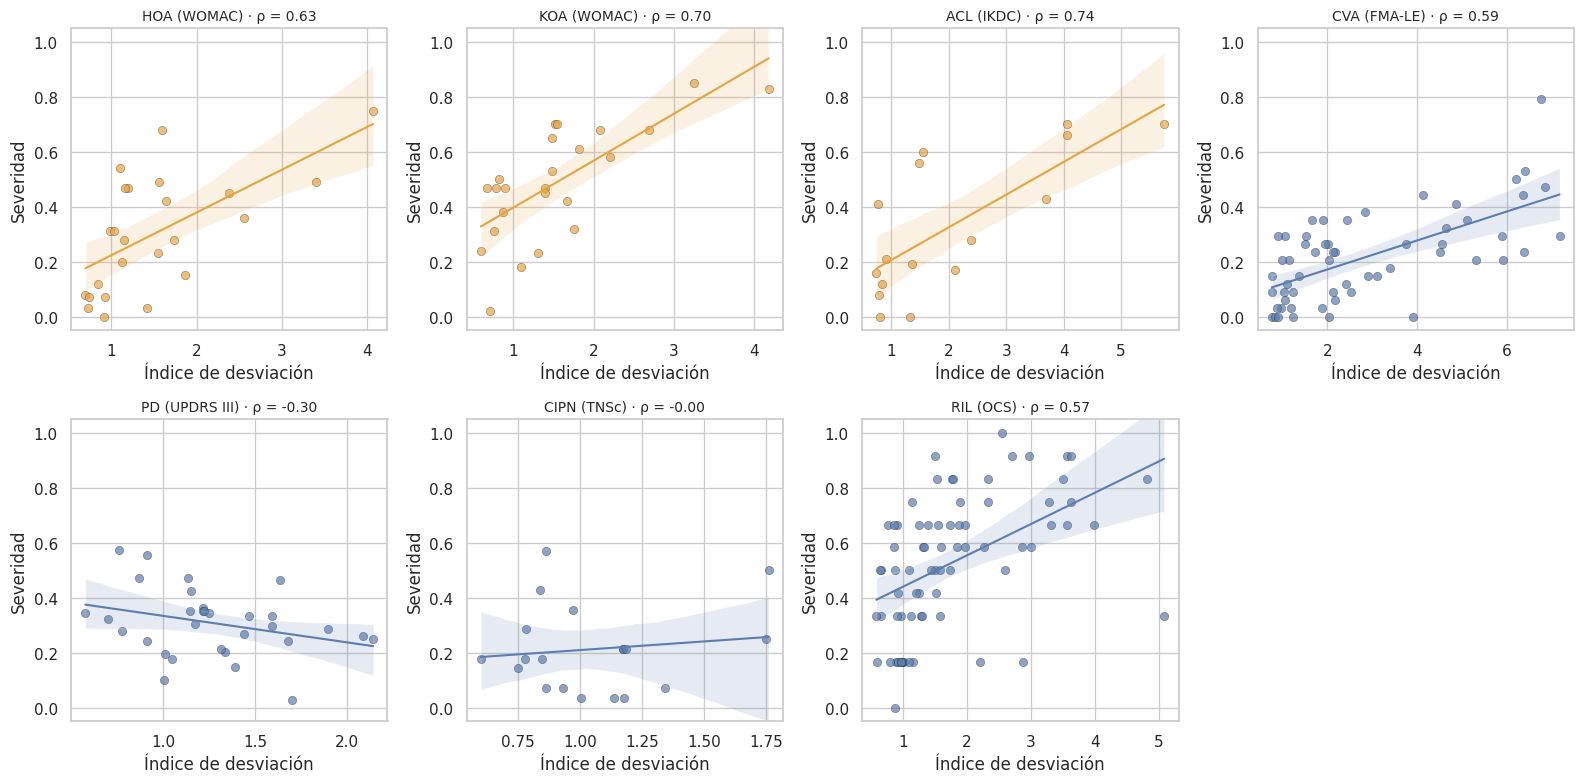

In [ ]:
n_col = 4
n_fil = int(np.ceil(len(COHORTES_SEV) / n_col))
fig, axes = plt.subplots(n_fil, n_col, figsize=(16, 4 * n_fil), squeeze=False)
for ax in axes.ravel()[len(COHORTES_SEV):]:
    ax.axis("off")
for ax, p in zip(axes.ravel(), COHORTES_SEV):
    d = con_sev[con_sev["pathologyKey"] == p]
    sns.regplot(data=d, x="indice_V2", y="severidad", ax=ax, color=PALETA[p],
                scatter_kws={"alpha": .7, "edgecolor": "k", "linewidths": .3}, line_kws={"lw": 1.5})
    ax.set_title(f"{p} ({ESCALAS[p][0]}) · ρ = {indice_sev.loc[p, 'ρ indice_V2']:.2f}", fontsize=10)
    ax.set_xlabel("Índice de desviación"); ax.set_ylabel("Severidad"); ax.set_ylim(-0.05, 1.05)
plt.tight_layout(); guardar_fig("7_2_indice_vs_severidad"); plt.show()

Interpretación. El índice de desviación resume en un único valor cuánto se aleja la marcha de cada visita de la esperada en una persona sana de la misma edad y altura. Al construirse solo a partir de sujetos sanos, no utiliza en ningún momento la puntuación clínica.

El índice distingue sujetos sanos de pacientes con un AUC de 0,745, que se mantiene en 0,655–0,672 en sujetos de 45 años o más. Este valor es comparable al del clasificador supervisado en el mismo subgrupo (0,689, apartado 5.6.1), lo que confirma que la marcha de los pacientes se aparta de la normalidad aun controlando la edad. Por cohortes, CVA presenta la mayor desviación, mientras que PD y CIPN se mantienen próximas a los valores de los sujetos sanos, en concordancia con lo observado en el análisis de componentes principales y en la matriz de confusión.

El resultado principal es la asociación entre el índice y la severidad clínica. En cinco de las siete cohortes (HOA, KOA, ACL, CVA y RIL), el índice se correlaciona de forma positiva y significativa con la severidad (ρ = 0,57–0,74; p ≤ 0,001): los pacientes cuya marcha más se aleja de la normalidad son los que obtienen peor puntuación en la escala. En PD y CIPN no se observa asociación. Esto puede explicarse por la naturaleza de sus escalas: la UPDRS III valora principalmente temblor, rigidez y bradicinesia en distintas partes del cuerpo, y la TNSc es fundamentalmente sensorial, por lo que ninguna mide directamente la marcha. A ello se suma el estrecho rango de severidad de PD y la escasa alteración de la marcha en ambas cohortes. La inclusión de la variabilidad (V2) apenas modifica los resultados.

Limitaciones. El valor normal de cada variable se estima a partir de sujetos sanos mayoritariamente jóvenes, por lo que en pacientes de edad avanzada se trata de una extrapolación. Además, el índice ordena a los pacientes por gravedad, pero no se traduce directamente en puntos de cada escala: es un marcador objetivo de severidad, no un sustituto de la evaluación clínica. Por último, varias cohortes incluyen más de una visita por sujeto, y la cohorte ACL cuenta con solo 16 visitas.

### 7.3 Modelo de severidad por patología

Un modelo aprende directamente de las puntuaciones del médico para intentar adivinar la gravedad de pacientes nuevos.

In [ ]:
def modelos_regresion():
    imp = ("imputer", SimpleImputer(strategy="median"))
    sc = ("sc", StandardScaler())
    return {
        "Baseline (media)": Pipeline([imp, ("reg", DummyRegressor(strategy="mean"))]),
        "Ridge (3 variables)": Pipeline([imp, sc, ("sel", SelectKBest(f_regression, k=3)),
                                         ("reg", RidgeCV(alphas=np.logspace(-2, 3, 30)))]),
        "KNN": Pipeline([imp, sc, ("reg", KNeighborsRegressor(n_neighbors=7, weights="distance"))]),
        "Random Forest": Pipeline([imp, ("reg", RandomForestRegressor(n_estimators=300, min_samples_leaf=3,
                                                                     random_state=RANDOM_STATE, n_jobs=-1))]),
    }
MODELO_SEV = "Ridge (3 variables)"

def evaluar_regresion(modelo, X, y, g, reps=N_REPS, n_splits=5):
    r2, mae, rho_, preds = [], [], [], []
    for r in range(reps):
        pred = np.zeros(len(y))
        for tr, te in particiones_sujeto(g, n_splits, RANDOM_STATE + r):
            m = clone(modelo).fit(X.iloc[tr], y.iloc[tr])
            pred[te] = np.ravel(m.predict(X.iloc[te]))
        r2.append(r2_score(y, pred)); mae.append(mean_absolute_error(y, pred))
        rho_.append(spearmanr(y, pred)[0] if np.std(pred) > 0 else np.nan)
        preds.append(pred)
    return {"R²": np.mean(r2), "MAE (0–1)": np.mean(mae), "ρ real-pred": np.nanmean(rho_)}, np.mean(preds, axis=0)

filas, pred_sev = [], {}
for p in COHORTES_SEV:
    m = S["pathologyKey"] == p
    y, g = S.loc[m, "severidad"], S.loc[m, "subject"]
    for nombre_fs, cols in [("V1", X_V1.columns), ("V2", X_V2.columns)]:
        for nombre, modelo in modelos_regresion().items():
            if nombre.startswith("Baseline") and nombre_fs == "V2":
                continue        # el baseline no usa variables: basta con calcularlo una vez
            met, pred = evaluar_regresion(modelo, X_S.loc[m, cols], y, g)
            pred_sev[(p, nombre_fs, nombre)] = (y.values, pred)
            filas.append({"cohorte": p, "variables": nombre_fs if not nombre.startswith("Baseline") else "—",
                          "modelo": nombre, **met, "MAE (puntos)": met["MAE (0–1)"] * ESCALAS[p][1]})

res_sev = pd.DataFrame(filas).set_index(["cohorte", "variables", "modelo"]).round(3)
guardar_tabla(res_sev, "7_3_severidad_por_cohorte")
print("Tabla completa guardada. Resumen en la celda siguiente.")

Tabla completa guardada. Resumen en la celda siguiente.


In [ ]:
# Resumen: modelo principal (Ridge, 3 variables) frente al baseline
base = res_sev.xs("Baseline (media)", level="modelo").droplevel("variables")
resumen = []
for p in COHORTES_SEV:
    for fs in ["V1", "V2"]:
        r = res_sev.loc[(p, fs, MODELO_SEV)]
        resumen.append({"cohorte": p, "escala": ESCALAS[p][0], "variables": fs,
                        "R²": r["R²"], "ρ real-pred": r["ρ real-pred"],
                        "MAE (puntos)": r["MAE (puntos)"],
                        "mejora MAE vs baseline (%)": (1 - r["MAE (0–1)"] / base.loc[p, "MAE (0–1)"]) * 100})

resumen_sev_modelo = pd.DataFrame(resumen).set_index(["cohorte", "escala", "variables"]).round(3)
guardar_tabla(resumen_sev_modelo, "7_3_resumen_modelo_principal")
resumen_sev_modelo

R²  ρ real-pred  MAE (puntos)  \
cohorte escala    variables                                     
HOA     WOMAC     V1         0.289        0.476        14.557   
                  V2         0.211        0.378        15.574   
KOA     WOMAC     V1         0.432        0.696        12.069   
                  V2         0.409        0.669        12.248   
ACL     IKDC      V1         0.473        0.691        15.167   
                  V2         0.473        0.691        15.167   
CVA     FMA-LE    V1         0.371        0.578         3.527   
                  V2         0.341        0.563         3.617   
PD      UPDRS III V1        -0.500       -0.477        12.044   
                  V2        -0.531       -0.481        12.110   
CIPN    TNSc      V1        -0.725       -0.510         4.295   
                  V2        -0.815       -0.399         4.417   
RIL     OCS       V1         0.170        0.481         2.174   
                  V2         0.183        0.503         2.146   

                             mejora MAE vs baseline (%)  
cohorte escala    variables                              
HOA     WOMAC     V1                             23.158  
                  V2                             17.895  
KOA     WOMAC     V1                             27.976  
                  V2                             27.381  
ACL     IKDC      V1                             34.483  
                  V2                             34.483  
CVA     FMA-LE    V1                             18.750  
                  V2                             17.188  
PD      UPDRS III V1                            -17.895  
                  V2                            -17.895  
CIPN    TNSc      V1                            -19.531  
                  V2                            -23.438  
RIL     OCS       V1                             13.810  
                  V2                             14.762

Interpretación. Para cada patología se entrenó un modelo de regresión Ridge con las tres variables más asociadas a la severidad, seleccionadas dentro de cada fold para evitar fugas de información. Se evaluó con validación cruzada agrupada por sujeto. El modelo supera al de referencia (predecir la severidad media) en cinco de las siete cohortes: ACL (R² = 0,47; ρ = 0,69), KOA (R² = 0,43; ρ = 0,70), CVA (R² = 0,37; ρ = 0,58), HOA (R² = 0,29; ρ = 0,48) y RIL (R² = 0,17; ρ = 0,48). En ellas reduce el error medio entre un 14 % y un 34 %. Es decir, a partir de un único registro de marcha de 10 metros, el modelo explica entre el 17 % y el 47 % de las diferencias de gravedad entre pacientes no vistos durante el entrenamiento, con un error medio de 12–15 puntos en las escalas de 0 a 100 (WOMAC, IKDC), de 3,5 puntos en Fugl-Meyer (0–34) y de 2,2 puntos en OCS (0–12).

En PD y CIPN, el modelo no supera al de referencia (R² negativo). Las correlaciones negativas entre severidad real y predicha no indican una relación inversa: son un efecto conocido de la validación cruzada en ausencia de señal, ya que al reservar para test a los pacientes más graves, el conjunto de entrenamiento queda desplazado hacia valores menores. Estos resultados coinciden con los del índice de desviación, y se atribuyen a que la UPDRS III y la TNSc no evalúan directamente la marcha.

La inclusión de las variables de variabilidad no mejora la estimación de la severidad (V1 obtiene resultados iguales o superiores a V2 en seis de las siete cohortes). Esto contrasta con su utilidad para identificar la patología (apartados 5.3 y 6.1): la variabilidad ayuda a reconocer qué patología presenta un paciente, pero no cuán grave es.

Limitaciones. El tamaño muestral por cohorte es reducido (16–75 visitas), especialmente en ACL, por lo que las estimaciones tienen una incertidumbre considerable. El modelo permite estimar el nivel aproximado de gravedad, pero no sustituye a la evaluación clínica

### 7.4 Modelo global de severidad

In [ ]:
GRUPO_DE = {"HS": "healthy", "HOA": "ortho", "KOA": "ortho", "ACL": "ortho",
            "CVA": "neuro", "PD": "neuro", "CIPN": "neuro", "RIL": "neuro"}

S_glob = S[S["pathologyKey"].isin(COHORTES_SEV)]
cohorte_oh = pd.get_dummies(S_glob["pathologyKey"], prefix="cohorte").astype(float)
y_g, g_g = S_glob["severidad"], S_glob["subject"]

filas, pred_glob = [], {}

# Baseline: solo sabe la cohorte → predice la severidad media de esa cohorte
met, pred_glob["Baseline (media de la cohorte)"] = evaluar_regresion(LinearRegression(), cohorte_oh, y_g, g_g)
filas.append({"variables": "solo cohorte", "modelo": "Baseline (media de la cohorte)", **met})

modelos_glob = {
    "Ridge": Pipeline([("imputer", SimpleImputer(strategy="median")), ("sc", StandardScaler()),
                       ("reg", RidgeCV(alphas=np.logspace(-2, 3, 30)))]),
    "KNN": modelos_regresion()["KNN"],
    "Random Forest": modelos_regresion()["Random Forest"],
}
for nombre_fs, cols in [("V1", X_V1.columns), ("V2", X_V2.columns)]:
    X_g = pd.concat([X_S.loc[S_glob.index, cols], cohorte_oh], axis=1)    # marcha + cohorte
    for nombre, modelo in modelos_glob.items():
        met, pred = evaluar_regresion(modelo, X_g, y_g, g_g)
        pred_glob[f"{nombre} · {nombre_fs}"] = pred
        filas.append({"variables": nombre_fs, "modelo": nombre, **met})

res_glob = pd.DataFrame(filas).set_index(["variables", "modelo"])
res_glob["mejora R² vs baseline"] = res_glob["R²"] - res_glob.loc[("solo cohorte", "Baseline (media de la cohorte)"), "R²"]
res_glob = res_glob.round(3)
guardar_tabla(res_glob, "7_4_severidad_global")
res_glob

R²  MAE (0–1)  ρ real-pred  \
variables    modelo                                                          
solo cohorte Baseline (media de la cohorte)  0.249      0.164        0.420   
V1           Ridge                           0.460      0.140        0.671   
             KNN                             0.437      0.143        0.644   
             Random Forest                   0.389      0.150        0.602   
V2           Ridge                           0.446      0.142        0.663   
             KNN                             0.425      0.144        0.635   
             Random Forest                   0.404      0.149        0.616   

                                             mejora R² vs baseline  
variables    modelo                                                 
solo cohorte Baseline (media de la cohorte)                  0.000  
V1           Ridge                                           0.212  
             KNN                                             0.188  
             Random Forest                                   0.141  
V2           Ridge                                           0.197  
             KNN                                             0.176  
             Random Forest                                   0.156

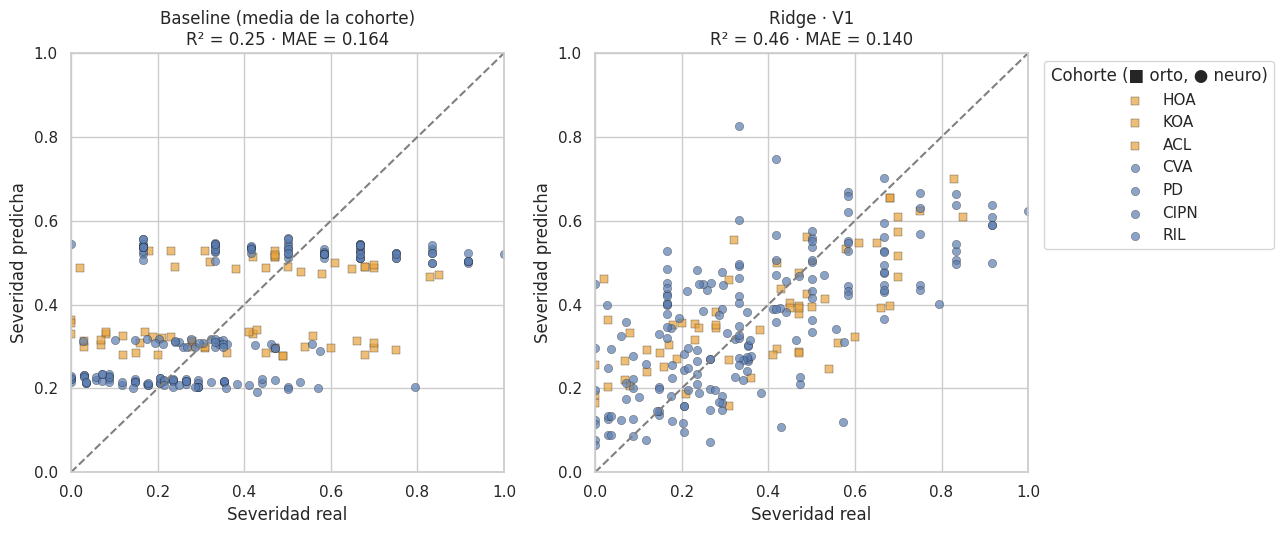

In [ ]:
mejor_glob = res_glob.drop(index="solo cohorte", level="variables")["R²"].idxmax()
nombre_mejor = f"{mejor_glob[1]} · {mejor_glob[0]}"

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for ax, nombre, fila in [(axes[0], "Baseline (media de la cohorte)", ("solo cohorte", "Baseline (media de la cohorte)")),
                         (axes[1], nombre_mejor, mejor_glob)]:
    for p in COHORTES_SEV:
        m = (S_glob["pathologyKey"] == p).values
        ax.scatter(y_g.values[m], pred_glob[nombre][m], color=PALETA[p], alpha=.7, edgecolor="k",
                   linewidth=.3, label=p, marker="o" if GRUPO_DE[p] == "neuro" else "s")
    ax.plot([0, 1], [0, 1], "--", color="grey"); ax.set_xlim(0, 1); ax.set_ylim(0, 1)
    ax.set_title(f"{nombre}\nR² = {res_glob.loc[fila, 'R²']:.2f} · MAE = {res_glob.loc[fila, 'MAE (0–1)']:.3f}")
    ax.set_xlabel("Severidad real"); ax.set_ylabel("Severidad predicha")
axes[1].legend(title="Cohorte (■ orto, ● neuro)", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout(); guardar_fig("7_4_severidad_global"); plt.show()

Interpretación. El modelo global combina todas las cohortes (247 visitas) e incluye la patología como variable, ya que al evaluar la gravedad el diagnóstico es conocido. Como cada cohorte presenta una severidad media distinta, el modelo de referencia predice la severidad media de la cohorte del paciente. Este modelo ya explica el 25 % de la variabilidad (R² = 0,249) sin utilizar información de la marcha.

Al añadir los parámetros de marcha, el mejor modelo (Ridge con V1) alcanza un R² de 0,460 (ρ = 0,67), lo que supone una mejora de 0,21 sobre la referencia. Es decir, la marcha explica aproximadamente el 28 % de la variabilidad de la severidad no atribuible a la patología, y el error medio se reduce de 0,164 a 0,140. Este resultado se obtiene pese a incluir las cohortes en las que la marcha no se asocia con la escala clínica (PD y CIPN).

La regresión Ridge, que asume un efecto común de la marcha sobre la severidad en todas las patologías, supera a los modelos capaces de aprender efectos específicos por patología (KNN: 0,437; Random Forest: 0,389). Esto sugiere la existencia de alteraciones de la marcha asociadas a la gravedad de forma transversal a distintas patologías, y es coherente con el pequeño tamaño muestral, que favorece los modelos sencillos. Como en los apartados anteriores, la inclusión de la variabilidad (V2) no mejora la estimación de la severidad.

### 7.5 ¿Qué parámetros se relacionan con la severidad?

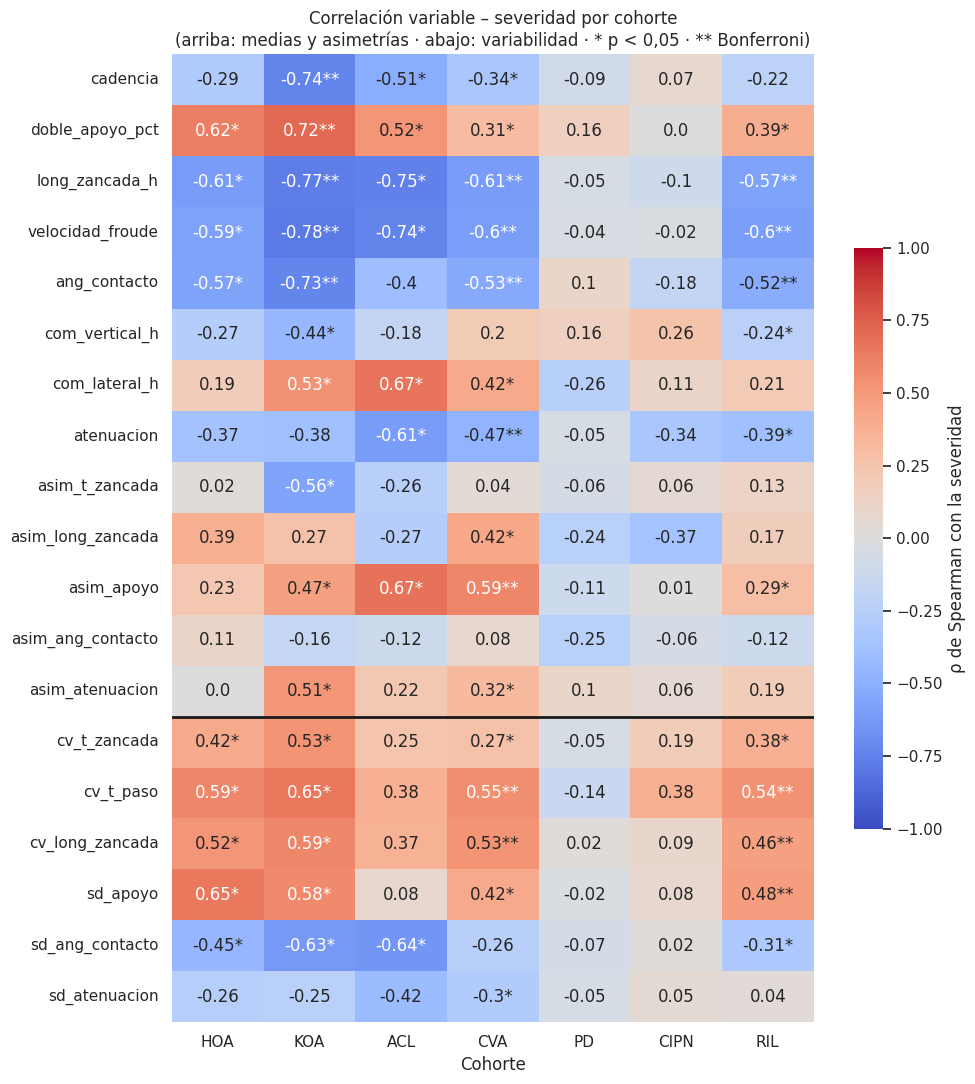

Correlaciones significativas: 59 sin corregir · 18 tras Bonferroni (de 133)


In [ ]:
rho = pd.DataFrame(index=X_S.columns, columns=COHORTES_SEV, dtype=float)
pv = rho.copy()
for p in COHORTES_SEV:
    m = S["pathologyKey"] == p
    for c in X_S.columns:
        r, pval_ = spearmanr(X_S.loc[m, c], S.loc[m, "severidad"], nan_policy="omit")
        rho.loc[c, p], pv.loc[c, p] = r, pval_

n_tests_75 = rho.size                                   # 19 variables × 7 cohortes
p_bonf = (pv * n_tests_75).clip(upper=1)
marca = np.where(p_bonf < 0.05, "**", np.where(pv < 0.05, "*", ""))
anot = rho.round(2).astype(str) + marca

plt.figure(figsize=(10, 11))
sns.heatmap(rho, annot=anot, fmt="", cmap="coolwarm", center=0, vmin=-1, vmax=1,
            cbar_kws={"label": "ρ de Spearman con la severidad", "shrink": .6})
plt.axhline(X_V1.shape[1], color="k", lw=2)
plt.title("Correlación variable – severidad por cohorte\n"
          "(arriba: medias y asimetrías · abajo: variabilidad · * p < 0,05 · ** Bonferroni)")
plt.xlabel("Cohorte"); plt.ylabel("")
plt.tight_layout(); guardar_fig("7_5_correlacion_severidad"); plt.show()
guardar_tabla(rho.round(3), "7_5_rho_severidad")
print(f"Correlaciones significativas: {(pv < 0.05).sum().sum()} sin corregir · "
      f"{(p_bonf < 0.05).sum().sum()} tras Bonferroni (de {n_tests_75})")

In [ ]:
from scipy.stats import rankdata

def correlacion_parcial(x, y, z):
    """Correlación de Spearman parcial entre x e y controlando z (sobre rangos)."""
    rx, ry, rz = rankdata(x), rankdata(y), rankdata(z)
    ex = rx - np.polyval(np.polyfit(rz, rx, 1), rz)
    ey = ry - np.polyval(np.polyfit(rz, ry, 1), rz)
    return spearmanr(ex, ey)

filas = []
for p in COHORTES_SEV:
    for var in ["cv_t_paso", "cv_t_zancada", "cv_long_zancada"]:
        m = (S["pathologyKey"] == p) & X_S[var].notna() & X_S["velocidad_froude"].notna()
        r_simple = spearmanr(X_S.loc[m, var], S.loc[m, "severidad"])
        r_parcial = correlacion_parcial(X_S.loc[m, var].values, S.loc[m, "severidad"].values,
                                        X_S.loc[m, "velocidad_froude"].values)
        filas.append({"cohorte": p, "variable": var,
                      "ρ simple": r_simple[0], "p simple": r_simple[1],
                      "ρ parcial (sin velocidad)": r_parcial[0], "p parcial": r_parcial[1]})

parcial = pd.DataFrame(filas).set_index(["cohorte", "variable"]).round(3)
guardar_tabla(parcial, "7_5_correlacion_parcial")
parcial

ρ simple  p simple  ρ parcial (sin velocidad)  \
cohorte variable                                                         
HOA     cv_t_paso           0.592     0.002                      0.385   
        cv_t_zancada        0.421     0.040                      0.029   
        cv_long_zancada     0.523     0.009                      0.163   
KOA     cv_t_paso           0.652     0.001                      0.233   
        cv_t_zancada        0.525     0.008                      0.019   
        cv_long_zancada     0.588     0.002                     -0.253   
ACL     cv_t_paso           0.377     0.150                     -0.156   
        cv_t_zancada        0.250     0.350                     -0.091   
        cv_long_zancada     0.374     0.153                     -0.088   
CVA     cv_t_paso           0.551     0.000                      0.207   
        cv_t_zancada        0.270     0.042                      0.016   
        cv_long_zancada     0.526     0.000                      0.241   
PD      cv_t_paso          -0.141     0.440                     -0.257   
        cv_t_zancada       -0.054     0.771                     -0.106   
        cv_long_zancada     0.019     0.918                     -0.069   
CIPN    cv_t_paso           0.383     0.105                      0.351   
        cv_t_zancada        0.194     0.425                      0.119   
        cv_long_zancada     0.094     0.703                      0.139   
RIL     cv_t_paso           0.537     0.000                      0.239   
        cv_t_zancada        0.379     0.001                      0.099   
        cv_long_zancada     0.462     0.000                      0.041   

                         p parcial  
cohorte variable                    
HOA     cv_t_paso            0.063  
        cv_t_zancada         0.894  
        cv_long_zancada      0.448  
KOA     cv_t_paso            0.273  
        cv_t_zancada         0.929  
        cv_long_zancada      0.233  
ACL     cv_t_paso            0.564  
        cv_t_zancada         0.737  
        cv_long_zancada      0.745  
CVA     cv_t_paso            0.123  
        cv_t_zancada         0.907  
        cv_long_zancada      0.071  
PD      cv_t_paso            0.156  
        cv_t_zancada         0.564  
        cv_long_zancada      0.708  
CIPN    cv_t_paso            0.141  
        cv_t_zancada         0.627  
        cv_long_zancada      0.571  
RIL     cv_t_paso            0.039  
        cv_t_zancada         0.396  
        cv_long_zancada      0.728